---
**Script name:** 04_02_02_09_simulation_plot_results.ipynb

**Purpose of script:** This script is to aggregate the results from each simulation into one pickle file and to plot the time difference of the estimates.

**Author:** Dr Katie Allan

**Date Created:** 2022-07-10

**Email:** katie.allan@sussex.ac.uk

**License:** 

---

**Notes:** Change 'path_to_folder' to appropriate folder paths.

---

## Importing libraries that are required

In [ ]:
import os
import pandas as pd
from pandas.api.types import is_datetime64_ns_dtype
import numpy as np
import pickle
import re
from plotnine import (
    ggplot,
    aes,
    after_stat,
    geom_point,
    geom_line,
    geom_bar,
    geom_histogram,
    coord_flip,
    facet_wrap,
    theme_matplotlib,
    theme_set,
    labs,
    theme_bw
)

## Define variables

In [ ]:
# File directories
input_dir = Path("../../04_01_data_wrangling/output")
output_dir = Path(".")

In [ ]:
# Define file directory and list of files
dir_path = os.getcwd()
filelist = os.listdir(dir_path)

In [11]:
# Define regular expression pattern to match filenames with numbers
folder_pattern = re.compile(r'simulation_error_estimate_.*')
subfolder_pattern = re.compile(r'simulation_error_estimate_.*_seed_\d+\_results')
file_pattern = re.compile(r'simulation_data_seed_\d+\_error_estimate.pickle')

## Load Data

In [ ]:
# create empty dictionary for dataframes and list for names
dataframes = {}

# Create loop to import files
for folder in filelist:
    #create folder name
    folder_name = folder
    print(f'The current directory is "{folder_name}"')
    
    #check folder matches node_id value
    if re.match(folder_pattern, folder_name):
        
        #set the full folder path
        full_path = f'{dir_path}\\{folder_name}\\'
        #print(full_path)

        #list all files in this directory
        sub_folderlist = os.listdir(full_path)
        #print(sub_folderlist)
        
        #loop through each file in node folder
        for sub_folder in sub_folderlist:
            #create folder name
            subfolder_name = sub_folder
            #print(subfolder_name)
            #check file matches beep_
            if re.match(subfolder_pattern, subfolder_name):
                #set the full folder path
                sub_path = f'{full_path}{subfolder_name}\\'
                #print(sub_path)
                
                #list all files in this directory
                sub_folderlist = os.listdir(sub_path)
                #print(sub_folderlist)
                
                #loop through each file in node folder
                for file in sub_folderlist:
                    #check file matches beep_
                    if re.match(file_pattern, file):
                        #print(file)
                        
                        #set the node id from folder
                        node_id = f'{folder_name[26:]}'
               
                        #set file name of jusr seed
                        file_id = file[16:38]
                        
                        #create file name
                        file_name = f'{node_id}_{file_id}'
                        print(file_name)

                        #create file_path variable
                        file_path = f'{sub_path}{file}'
                
                        #read file into python
                        with open(f'{file_path}', 'rb') as file:
                            df = pickle.load(file)

                        #assign file to python dictionary
                        dataframes[file_name] = df

## Data processing BatHouse results

In [ ]:
#Create blank lists for results
all_results_list = []
first_results_list = []
median_results_list = []
last_results_list = []

for outer_key, inner_dict in dataframes.items():
    if re.match(re.compile(r'^BatHouse_1.*$'), outer_key):
        print(outer_key, type(inner_dict))
        seed_value = outer_key[11:18]
        print(seed_value)
        
        # Iterate over the inner dictionary
        for inner_key, df in inner_dict.items():
            if re.match(re.compile(r'.*_all_kl_div_error'), inner_key):
                print(inner_key, type(df))
                
                for final_key, final_df in df.items():
                    print(final_key)
                    ss_value = final_key[12:]
                    print(ss_value)
                    
                    if final_df.empty:
                        print('DataFrame is empty!')

                    else:
                        #create a copy of the dataframe before changing
                        new_df = final_df
                    
                        #create new columns of the sample size and the set seed of simnulation
                        new_df['sample_size'] = ss_value
                        new_df['set_seed'] = seed_value
                    
                        #calculate the mode values
                        first_mode = new_df.iloc[[0]]
                        last_mode = new_df.iloc[[-1]]
                        #median of the mode
                        new_df['median_diff'] = (new_df['time_diff'] - new_df['time_diff'].median()).abs()
                        median_mode = new_df.loc[new_df['median_diff'] == new_df['median_diff'].min()]
                    
                        #Add to dataframes
                        all_results_list.append(new_df)
                        first_results_list.append(first_mode)
                        median_results_list.append(median_mode)
                        last_results_list.append(last_mode)

bathouse_1_all_results_df = pd.concat(all_results_list, axis = 0, ignore_index = True)
bathouse_1_all_results_df[['sample_size']] = bathouse_1_all_results_df[['sample_size']].apply(pd.to_numeric)

bathouse_1_first_results_df = pd.concat(first_results_list, axis = 0, ignore_index = True)
bathouse_1_first_results_df[['sample_size']] = bathouse_1_first_results_df[['sample_size']].apply(pd.to_numeric)

bathouse_1_median_results_df = pd.concat(median_results_list, axis = 0, ignore_index = True)
bathouse_1_median_results_df[['sample_size']] = bathouse_1_median_results_df[['sample_size']].apply(pd.to_numeric)

bathouse_1_last_results_df = pd.concat(last_results_list, axis = 0, ignore_index = True)
bathouse_1_last_results_df[['sample_size']] = bathouse_1_last_results_df[['sample_size']].apply(pd.to_numeric)

In [15]:
bathouse_1_all_KL_div_sim_results = {
    "all_mode_results" : bathouse_1_all_results_df,
    "first_mode_results" : bathouse_1_first_results_df,
    "median_mode_results" : bathouse_1_median_results_df,
    "last_mode_results" : bathouse_1_last_results_df
}

In [16]:
#Remove NA values
bathouse_1_all_results_df.dropna(subset = ['error_estimate'], inplace = True)
bathouse_1_first_results_df.dropna(subset = ['error_estimate'], inplace = True)
bathouse_1_median_results_df.dropna(subset = ['error_estimate'], inplace = True)
bathouse_1_last_results_df.dropna(subset = ['error_estimate'], inplace = True)

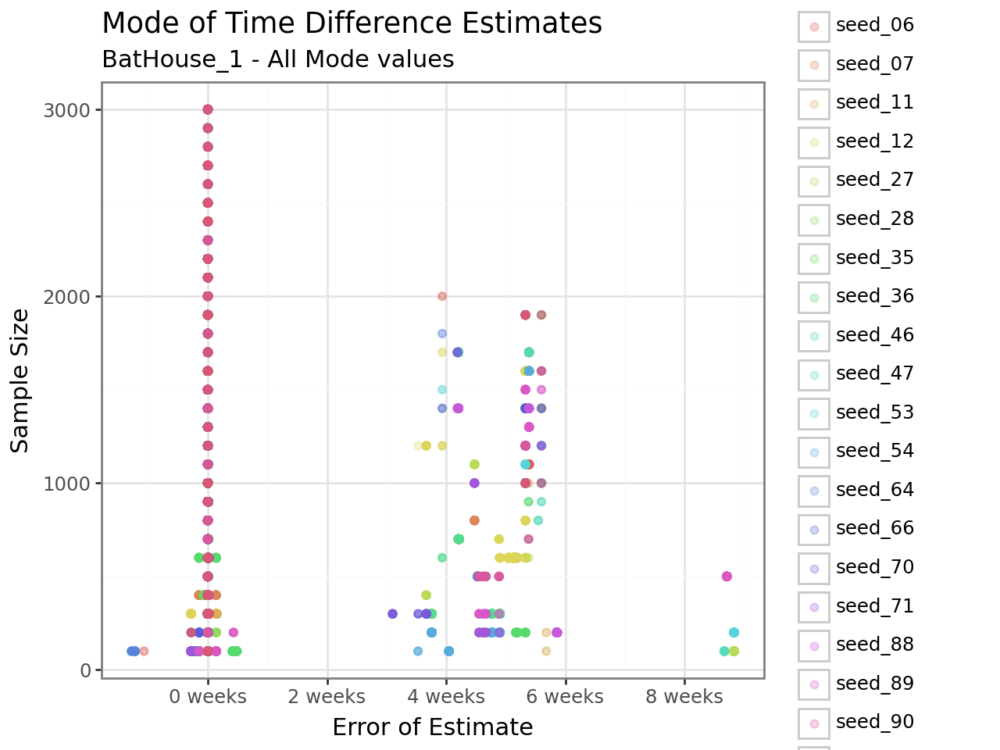

C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:606: PlotnineWarning: Saving 6.4 x 4.8 in image.
C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:607: PlotnineWarning: Filename: BatHouse_1_all_results_all_mode.png


In [17]:
p = ggplot(bathouse_1_all_results_df, aes("error_estimate", "sample_size", colour = "set_seed"))  + geom_point(alpha = 0.25) + labs(title= "Mode of Time Difference Estimates", subtitle="BatHouse_1 - All Mode values", x = "Error of Estimate",  y = "Sample Size", colour = "Simulation seed") + theme_bw()
p.show()
p.save(filename = 'BatHouse_1_all_results_all_mode.png', dpi = 300)

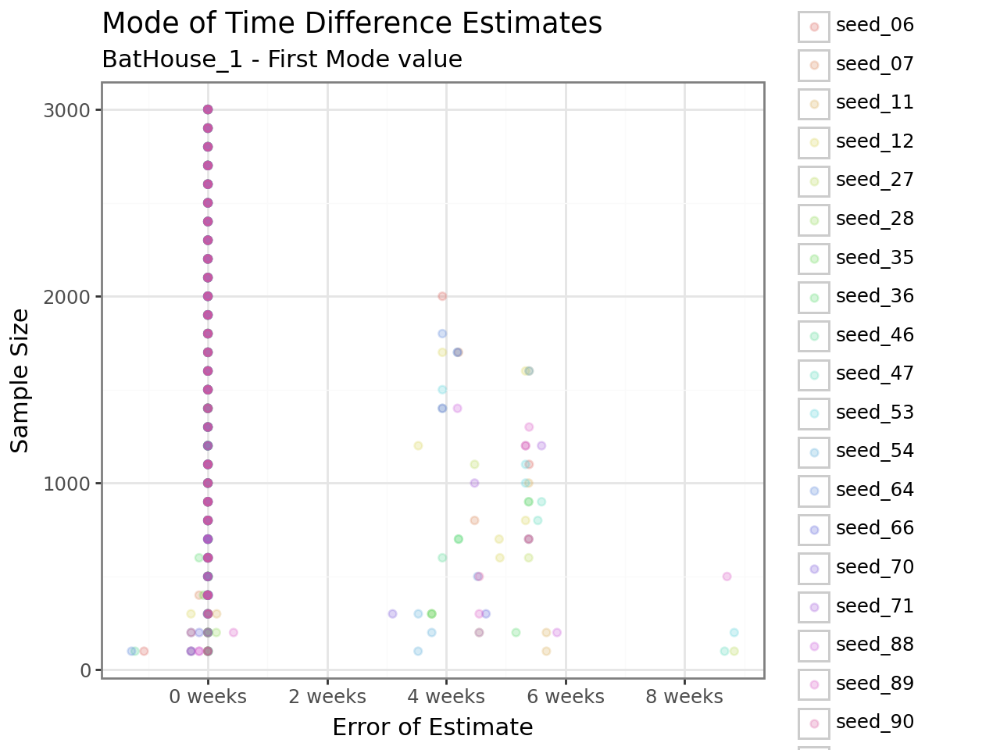

C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:606: PlotnineWarning: Saving 6.4 x 4.8 in image.
C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:607: PlotnineWarning: Filename: BatHouse_1_all_results_first_mode.png


In [18]:
p = ggplot(bathouse_1_first_results_df, aes("error_estimate", "sample_size", colour = "set_seed")) + geom_point(alpha = 0.25) + labs(title= "Mode of Time Difference Estimates", subtitle="BatHouse_1 - First Mode value", x = "Error of Estimate",  y = "Sample Size", colour = "Simulation seed") + theme_bw()
p.show()
p.save(filename = 'BatHouse_1_all_results_first_mode.png', dpi = 300)

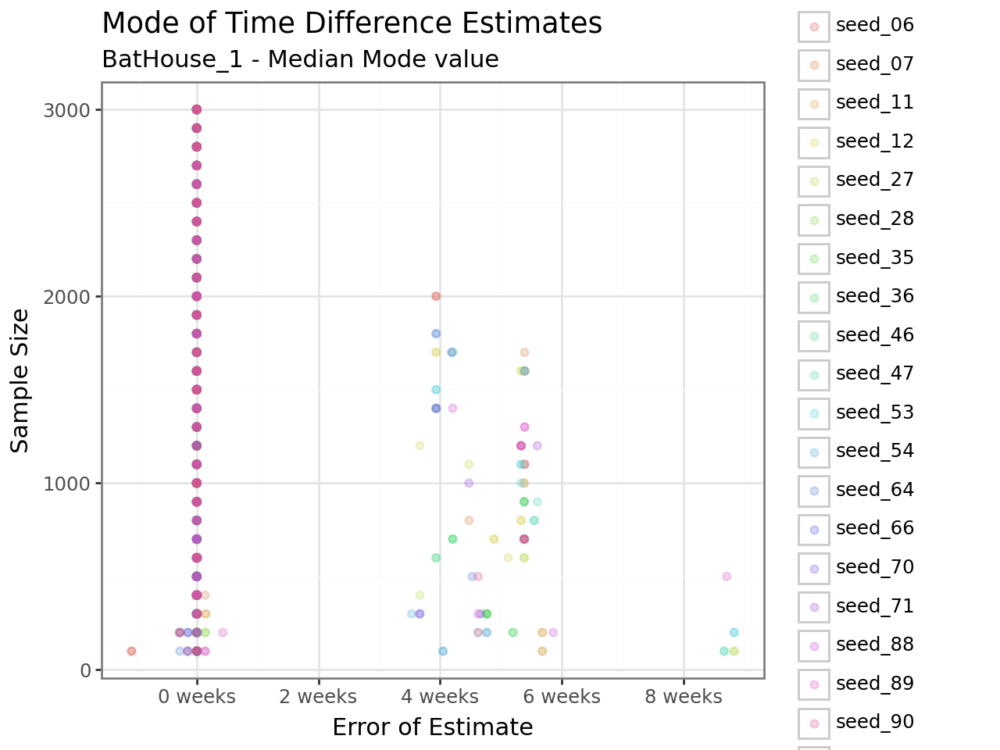

C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:606: PlotnineWarning: Saving 6.4 x 4.8 in image.
C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:607: PlotnineWarning: Filename: BatHouse_1_all_results_median_mode.png


In [19]:
p = ggplot(bathouse_1_median_results_df, aes("error_estimate", "sample_size", colour = "set_seed"))  + geom_point(alpha = 0.25) + labs(title= "Mode of Time Difference Estimates", subtitle="BatHouse_1 - Median Mode value", x = "Error of Estimate",  y = "Sample Size", colour = "Simulation seed") + theme_bw()
p.show()
p.save(filename = 'BatHouse_1_all_results_median_mode.png', dpi = 300)

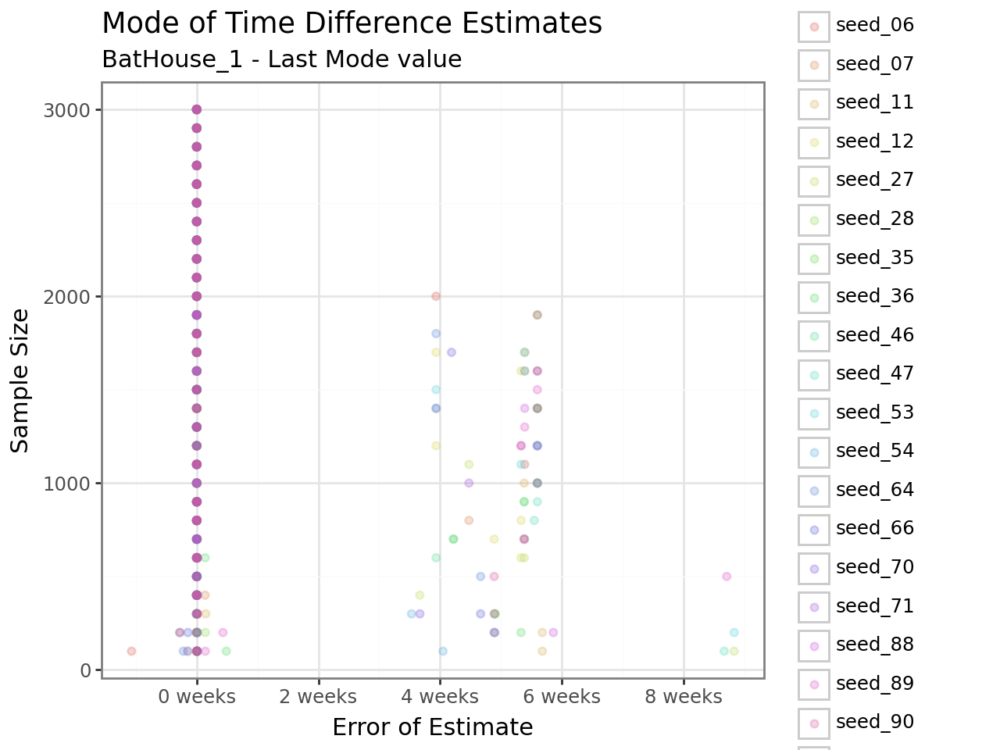

C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:606: PlotnineWarning: Saving 6.4 x 4.8 in image.
C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:607: PlotnineWarning: Filename: BatHouse_1_all_results_last_mode.png


In [20]:
p = ggplot(bathouse_1_last_results_df, aes("error_estimate", "sample_size", colour = "set_seed"))  + geom_point(alpha = 0.25) + labs(title= "Mode of Time Difference Estimates", subtitle="BatHouse_1 - Last Mode value", x = "Error of Estimate",  y = "Sample Size", colour = "Simulation seed") + theme_bw()
p.show()
p.save(filename = 'BatHouse_1_all_results_last_mode.png', dpi = 300)

In [ ]:
#Create blank lists for results
all_results_list = []
first_results_list = []
median_results_list = []
last_results_list = []

for outer_key, inner_dict in dataframes.items():
    if re.match(re.compile(r'^BatHouse_1.*$'), outer_key):
        print(outer_key, type(inner_dict))
        seed_value = outer_key[11:18]
        print(seed_value)
        
        # Iterate over the inner dictionary
        for inner_key, df in inner_dict.items():
            if re.match(re.compile(r'.*_low_kl_div_error'), inner_key):
                print(inner_key, type(df))
                
                for final_key, final_df in df.items():
                    print(final_key)
                    ss_value = final_key[12:]
                    print(ss_value)
                    
                    if final_df.empty:
                        print('DataFrame is empty!')

                    else:
                        #create a copy of the dataframe before changing
                        new_df = final_df
                    
                        #create new columns of the sample size and the set seed of simnulation
                        new_df['sample_size'] = ss_value
                        new_df['set_seed'] = seed_value
                    
                        #calculate the mode values
                        first_mode = new_df.iloc[[0]]
                        last_mode = new_df.iloc[[-1]]
                        #median of the mode
                        new_df['median_diff'] = (new_df['time_diff'] - new_df['time_diff'].median()).abs()
                        median_mode = new_df.loc[new_df['median_diff'] == new_df['median_diff'].min()]
                    
                        #Add to dataframes
                        all_results_list.append(new_df)
                        first_results_list.append(first_mode)
                        median_results_list.append(median_mode)
                        last_results_list.append(last_mode)

bathouse_1_all_results_df = pd.concat(all_results_list, axis = 0, ignore_index = True)
bathouse_1_all_results_df[['sample_size']] = bathouse_1_all_results_df[['sample_size']].apply(pd.to_numeric)

bathouse_1_first_results_df = pd.concat(first_results_list, axis = 0, ignore_index = True)
bathouse_1_first_results_df[['sample_size']] = bathouse_1_first_results_df[['sample_size']].apply(pd.to_numeric)

bathouse_1_median_results_df = pd.concat(median_results_list, axis = 0, ignore_index = True)
bathouse_1_median_results_df[['sample_size']] = bathouse_1_median_results_df[['sample_size']].apply(pd.to_numeric)

bathouse_1_last_results_df = pd.concat(last_results_list, axis = 0, ignore_index = True)
bathouse_1_last_results_df[['sample_size']] = bathouse_1_last_results_df[['sample_size']].apply(pd.to_numeric)

In [22]:
bathouse_1_low_KL_div_sim_results = {
    "all_mode_results" : bathouse_1_all_results_df,
    "first_mode_results" : bathouse_1_first_results_df,
    "median_mode_results" : bathouse_1_median_results_df,
    "last_mode_results" : bathouse_1_last_results_df
}

In [23]:
#Remove NA values
bathouse_1_all_results_df.dropna(subset = ['error_estimate'], inplace = True)
bathouse_1_first_results_df.dropna(subset = ['error_estimate'], inplace = True)
bathouse_1_median_results_df.dropna(subset = ['error_estimate'], inplace = True)
bathouse_1_last_results_df.dropna(subset = ['error_estimate'], inplace = True)

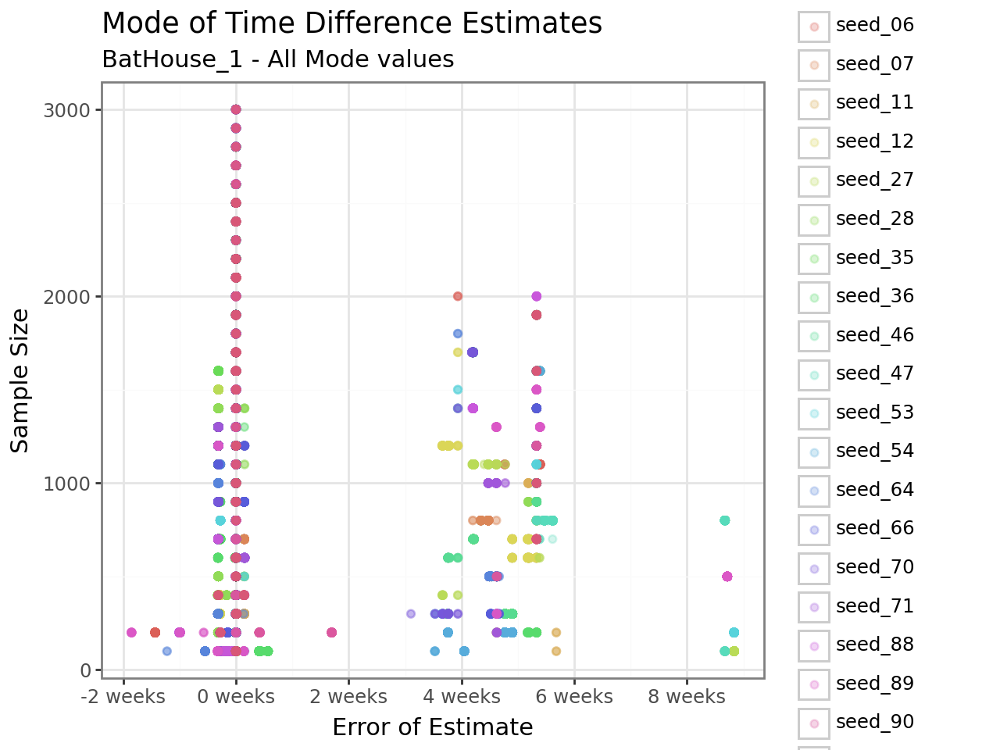

C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:606: PlotnineWarning: Saving 6.4 x 4.8 in image.
C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:607: PlotnineWarning: Filename: BatHouse_1_low_results_all_mode.png


In [24]:
p = ggplot(bathouse_1_all_results_df, aes("error_estimate", "sample_size", colour = "set_seed"))  + geom_point(alpha = 0.25) + labs(title= "Mode of Time Difference Estimates", subtitle="BatHouse_1 - All Mode values", x = "Error of Estimate",  y = "Sample Size", colour = "Simulation seed") + theme_bw()
p.show()
p.save(filename = 'BatHouse_1_low_results_all_mode.png', dpi = 300)

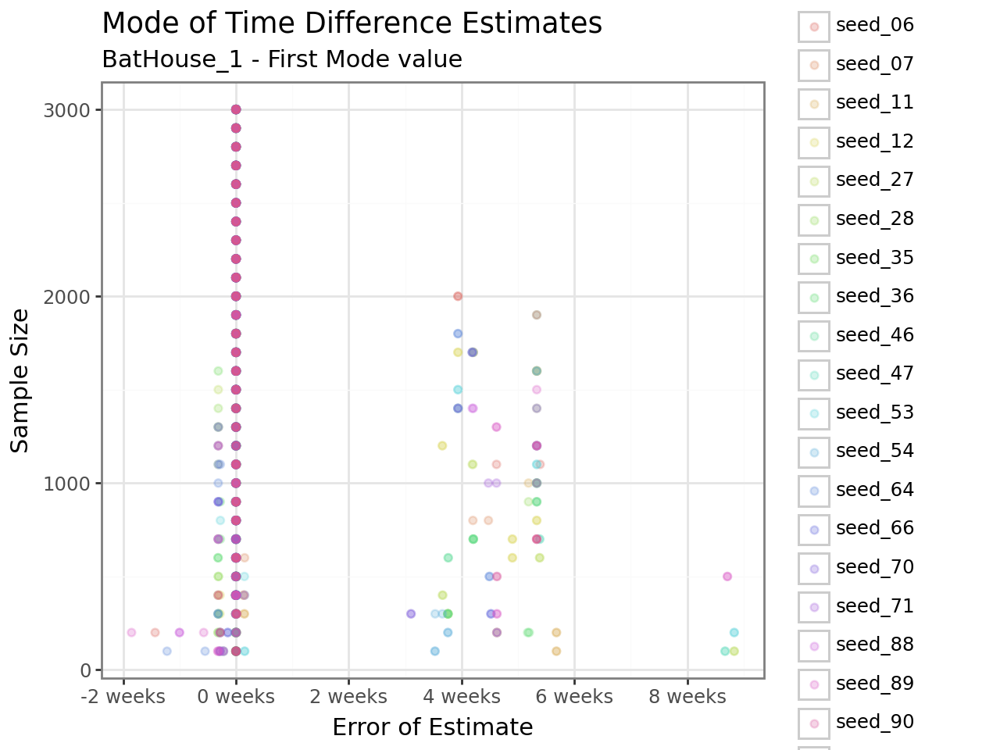

C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:606: PlotnineWarning: Saving 6.4 x 4.8 in image.
C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:607: PlotnineWarning: Filename: BatHouse_1_low_results_first_mode.png


In [25]:
p = ggplot(bathouse_1_first_results_df, aes("error_estimate", "sample_size", colour = "set_seed")) + geom_point(alpha = 0.25) + labs(title= "Mode of Time Difference Estimates", subtitle="BatHouse_1 - First Mode value", x = "Error of Estimate",  y = "Sample Size", colour = "Simulation seed") + theme_bw()
p.show()
p.save(filename = 'BatHouse_1_low_results_first_mode.png', dpi = 300)

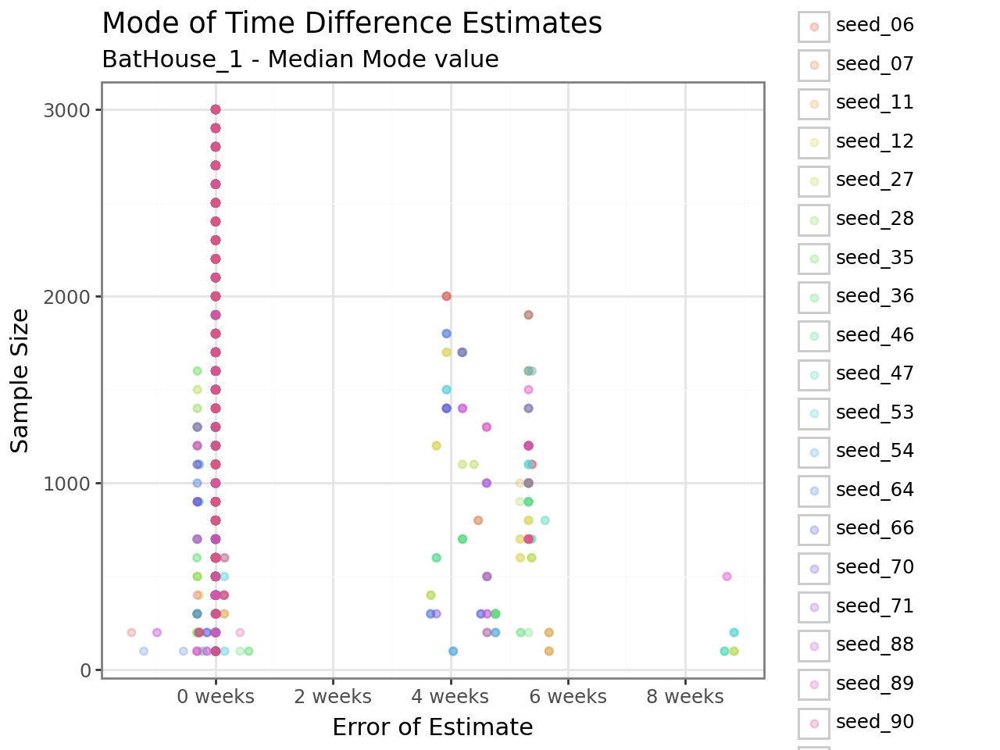

C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:606: PlotnineWarning: Saving 6.4 x 4.8 in image.
C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:607: PlotnineWarning: Filename: BatHouse_1_low_results_median_mode.png


In [26]:
p = ggplot(bathouse_1_median_results_df, aes("error_estimate", "sample_size", colour = "set_seed"))  + geom_point(alpha = 0.25) + labs(title= "Mode of Time Difference Estimates", subtitle="BatHouse_1 - Median Mode value", x = "Error of Estimate",  y = "Sample Size", colour = "Simulation seed") + theme_bw()
p.show()
p.save(filename = 'BatHouse_1_low_results_median_mode.png', dpi = 300)

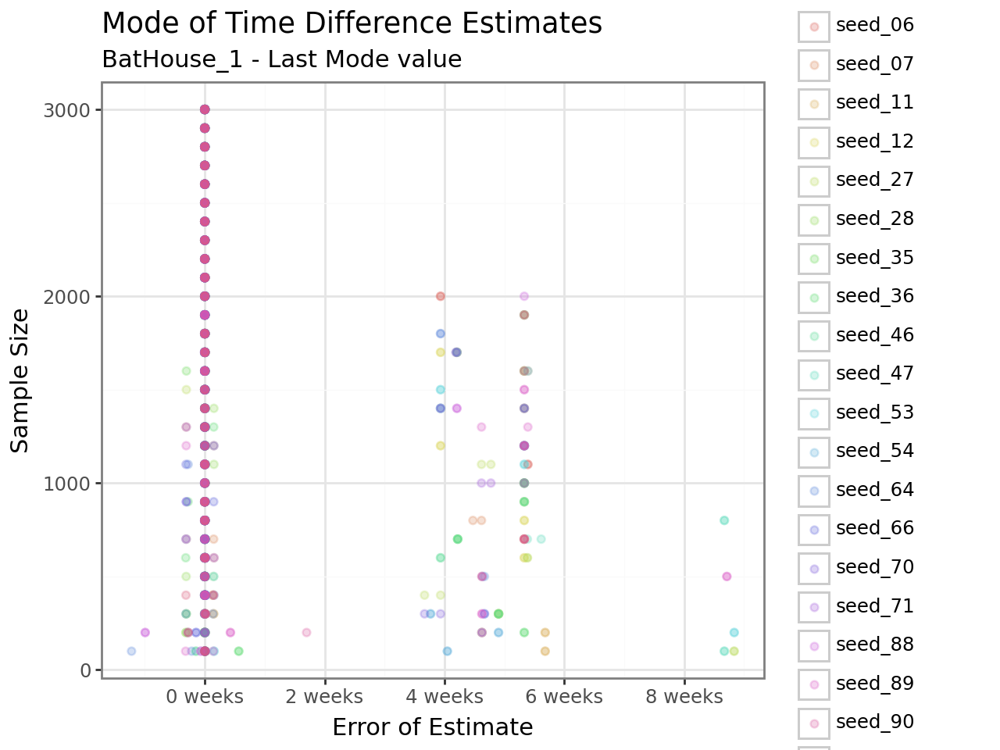

C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:606: PlotnineWarning: Saving 6.4 x 4.8 in image.
C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:607: PlotnineWarning: Filename: BatHouse_1_low_results_last_mode.png


In [27]:
p = ggplot(bathouse_1_last_results_df, aes("error_estimate", "sample_size", colour = "set_seed"))  + geom_point(alpha = 0.25) + labs(title= "Mode of Time Difference Estimates", subtitle="BatHouse_1 - Last Mode value", x = "Error of Estimate",  y = "Sample Size", colour = "Simulation seed") + theme_bw()
p.show()
p.save(filename = 'BatHouse_1_low_results_last_mode.png', dpi = 300)

#Create blank lists for results
all_results_list = []
first_results_list = []
median_results_list = []
last_results_list = []

for outer_key, inner_dict in dataframes.items():
    if re.match(re.compile(r'^BatHouse_1.*$'), outer_key):
        print(outer_key, type(inner_dict))
        seed_value = outer_key[11:18]
        print(seed_value)
        
        # Iterate over the inner dictionary
        for inner_key, df in inner_dict.items():
            if re.match(re.compile(r'.*_very_low_kl_div_error'), inner_key):
                print(inner_key, type(df))
                
                for final_key, final_df in df.items():
                    print(final_key)
                    ss_value = final_key[12:]
                    print(ss_value)
                    
                    if final_df.empty:
                        print('DataFrame is empty!')

                    else:
                        #create a copy of the dataframe before changing
                        new_df = final_df
                    
                        #create new columns of the sample size and the set seed of simnulation
                        new_df['sample_size'] = ss_value
                        new_df['set_seed'] = seed_value
                    
                        #calculate the mode values
                        first_mode = new_df.iloc[[0]]
                        last_mode = new_df.iloc[[-1]]
                        #median of the mode
                        new_df['median_diff'] = (new_df['time_diff'] - new_df['time_diff'].median()).abs()
                        median_mode = new_df.loc[new_df['median_diff'] == new_df['median_diff'].min()]
                    
                        #Add to dataframes
                        all_results_list.append(new_df)
                        first_results_list.append(first_mode)
                        median_results_list.append(median_mode)
                        last_results_list.append(last_mode)

bathouse_1_all_results_df = pd.concat(all_results_list, axis = 0, ignore_index = True)
bathouse_1_all_results_df[['sample_size']] = bathouse_1_all_results_df[['sample_size']].apply(pd.to_numeric)

bathouse_1_first_results_df = pd.concat(first_results_list, axis = 0, ignore_index = True)
bathouse_1_first_results_df[['sample_size']] = bathouse_1_first_results_df[['sample_size']].apply(pd.to_numeric)

bathouse_1_median_results_df = pd.concat(median_results_list, axis = 0, ignore_index = True)
bathouse_1_median_results_df[['sample_size']] = bathouse_1_median_results_df[['sample_size']].apply(pd.to_numeric)

bathouse_1_last_results_df = pd.concat(last_results_list, axis = 0, ignore_index = True)
bathouse_1_last_results_df[['sample_size']] = bathouse_1_last_results_df[['sample_size']].apply(pd.to_numeric)

In [29]:
bathouse_1_very_low_KL_div_sim_results = {
    "all_mode_results" : bathouse_1_all_results_df,
    "first_mode_results" : bathouse_1_first_results_df,
    "median_mode_results" : bathouse_1_median_results_df,
    "last_mode_results" : bathouse_1_last_results_df
}

In [30]:
#Remove NA values
bathouse_1_all_results_df.dropna(subset = ['error_estimate'], inplace = True)
bathouse_1_first_results_df.dropna(subset = ['error_estimate'], inplace = True)
bathouse_1_median_results_df.dropna(subset = ['error_estimate'], inplace = True)
bathouse_1_last_results_df.dropna(subset = ['error_estimate'], inplace = True)

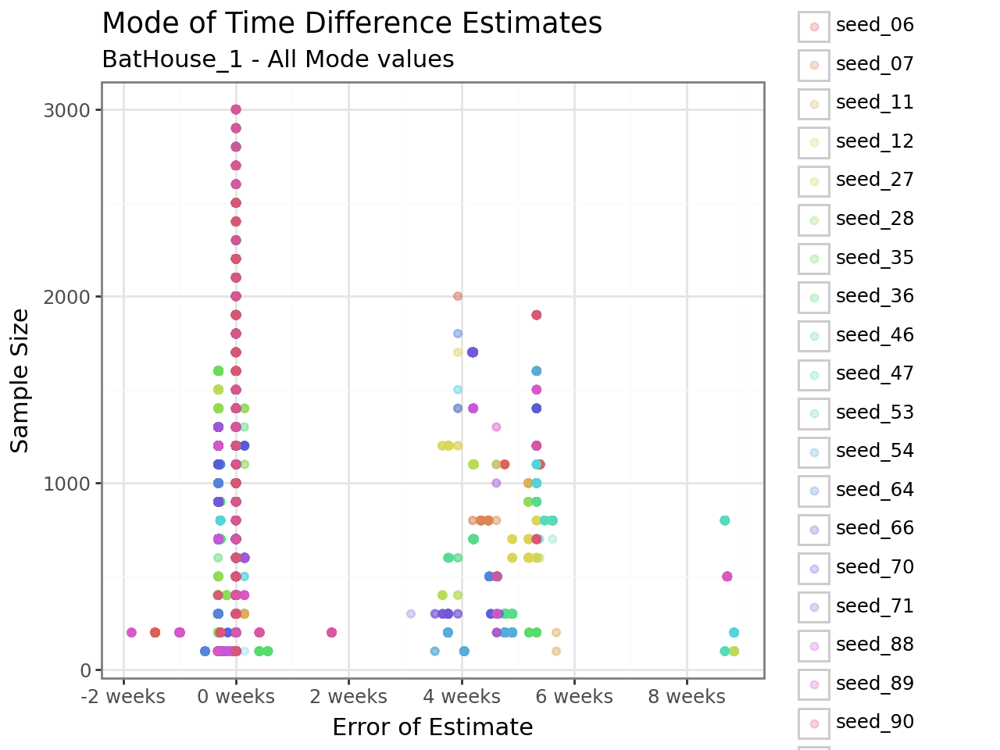

C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:606: PlotnineWarning: Saving 6.4 x 4.8 in image.
C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:607: PlotnineWarning: Filename: BatHouse_1_very_low_results_all_mode.png


In [31]:
p = ggplot(bathouse_1_all_results_df, aes("error_estimate", "sample_size", colour = "set_seed"))  + geom_point(alpha = 0.25) + labs(title= "Mode of Time Difference Estimates", subtitle="BatHouse_1 - All Mode values", x = "Error of Estimate",  y = "Sample Size", colour = "Simulation seed") + theme_bw()
p.show()
p.save(filename = 'BatHouse_1_very_low_results_all_mode.png', dpi = 300)

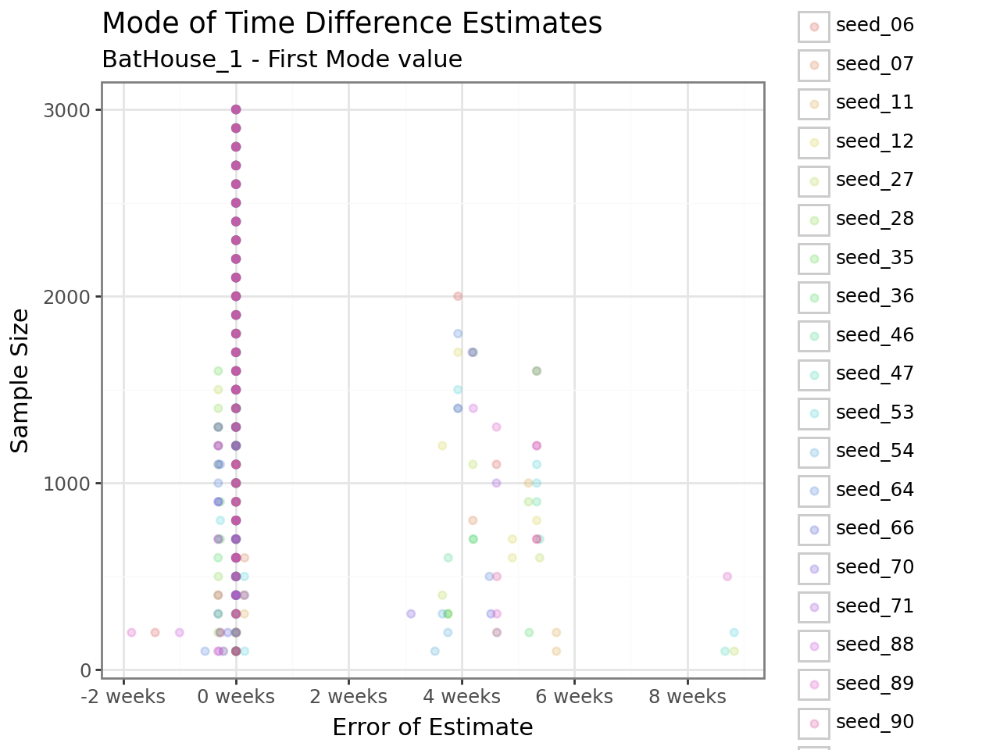

C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:606: PlotnineWarning: Saving 6.4 x 4.8 in image.
C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:607: PlotnineWarning: Filename: BatHouse_1_very_low_results_first_mode.png


In [32]:
p = ggplot(bathouse_1_first_results_df, aes("error_estimate", "sample_size", colour = "set_seed")) + geom_point(alpha = 0.25) + labs(title= "Mode of Time Difference Estimates", subtitle="BatHouse_1 - First Mode value", x = "Error of Estimate",  y = "Sample Size", colour = "Simulation seed") + theme_bw()
p.show()
p.save(filename = 'BatHouse_1_very_low_results_first_mode.png', dpi = 300)

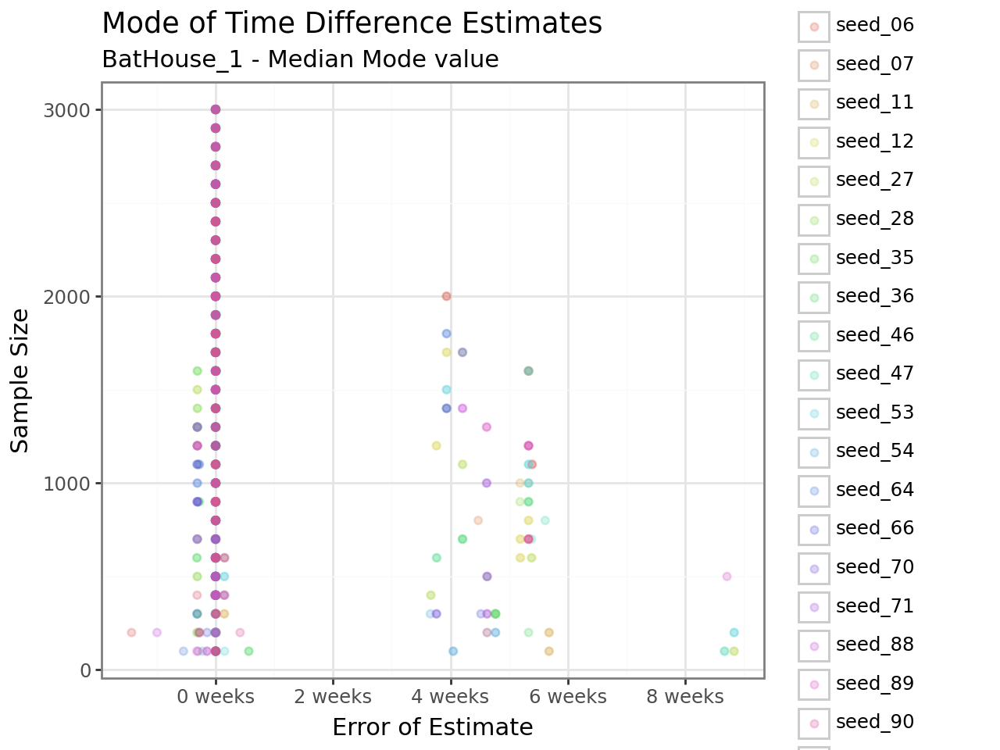

C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:606: PlotnineWarning: Saving 6.4 x 4.8 in image.
C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:607: PlotnineWarning: Filename: BatHouse_1_very_low_results_median_mode.png


In [33]:
p = ggplot(bathouse_1_median_results_df, aes("error_estimate", "sample_size", colour = "set_seed"))  + geom_point(alpha = 0.25) + labs(title= "Mode of Time Difference Estimates", subtitle="BatHouse_1 - Median Mode value", x = "Error of Estimate",  y = "Sample Size", colour = "Simulation seed") + theme_bw()
p.show()
p.save(filename = 'BatHouse_1_very_low_results_median_mode.png', dpi = 300)

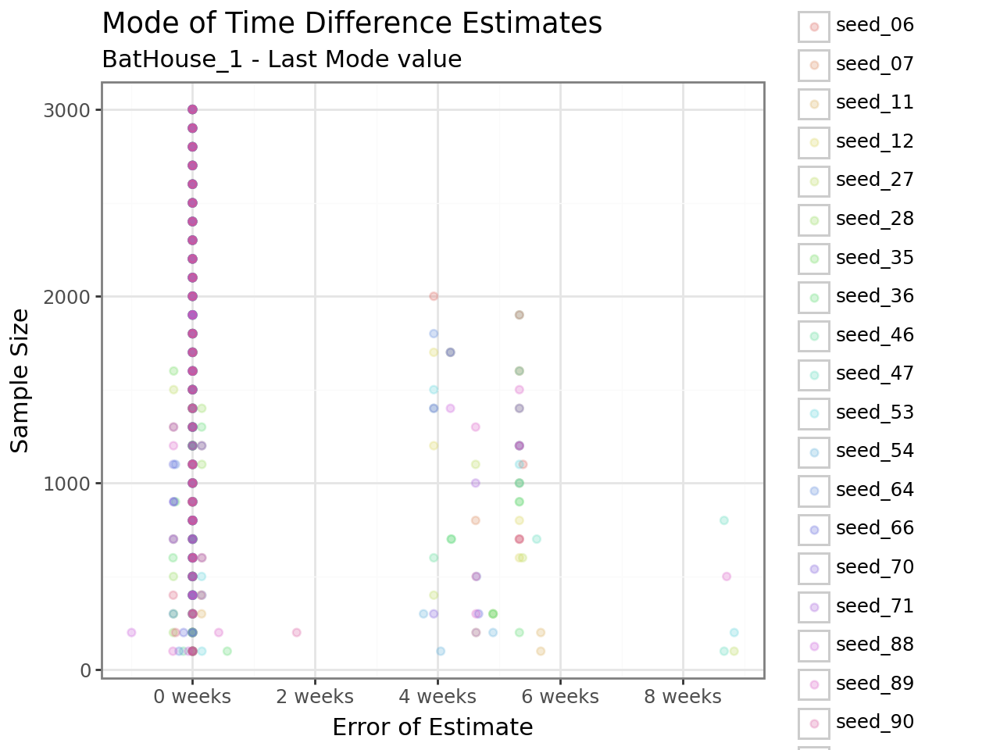

C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:606: PlotnineWarning: Saving 6.4 x 4.8 in image.
C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:607: PlotnineWarning: Filename: BatHouse_1_very_low_results_last_mode.png


In [34]:
p = ggplot(bathouse_1_last_results_df, aes("error_estimate", "sample_size", colour = "set_seed"))  + geom_point(alpha = 0.25) + labs(title= "Mode of Time Difference Estimates", subtitle="BatHouse_1 - Last Mode value", x = "Error of Estimate",  y = "Sample Size", colour = "Simulation seed") + theme_bw()
p.show()
p.save(filename = 'BatHouse_1_very_low_results_last_mode.png', dpi = 300)

In [ ]:
#Create blank lists for results
all_results_list = []
first_results_list = []
median_results_list = []
last_results_list = []

for outer_key, inner_dict in dataframes.items():
    if re.match(re.compile(r'^BatHouse_1.*$'), outer_key):
        print(outer_key, type(inner_dict))
        seed_value = outer_key[11:18]
        print(seed_value)
        
        # Iterate over the inner dictionary
        for inner_key, df in inner_dict.items():
            if re.match(re.compile(r'.*_zero_kl_div_error'), inner_key):
                print(inner_key, type(df))
                
                for final_key, final_df in df.items():
                    print(final_key)
                    ss_value = final_key[12:]
                    print(ss_value)
                    
                    if final_df.empty:
                        print('DataFrame is empty!')

                    else:
                        #create a copy of the dataframe before changing
                        new_df = final_df
                    
                        #create new columns of the sample size and the set seed of simnulation
                        new_df['sample_size'] = ss_value
                        new_df['set_seed'] = seed_value
                    
                        #calculate the mode values
                        first_mode = new_df.iloc[[0]]
                        last_mode = new_df.iloc[[-1]]
                        #median of the mode
                        new_df['median_diff'] = (new_df['time_diff'] - new_df['time_diff'].median()).abs()
                        median_mode = new_df.loc[new_df['median_diff'] == new_df['median_diff'].min()]
                    
                        #Add to dataframes
                        all_results_list.append(new_df)
                        first_results_list.append(first_mode)
                        median_results_list.append(median_mode)
                        last_results_list.append(last_mode)

bathouse_1_all_results_df = pd.concat(all_results_list, axis = 0, ignore_index = True)
bathouse_1_all_results_df[['sample_size']] = bathouse_1_all_results_df[['sample_size']].apply(pd.to_numeric)

bathouse_1_first_results_df = pd.concat(first_results_list, axis = 0, ignore_index = True)
bathouse_1_first_results_df[['sample_size']] = bathouse_1_first_results_df[['sample_size']].apply(pd.to_numeric)

bathouse_1_median_results_df = pd.concat(median_results_list, axis = 0, ignore_index = True)
bathouse_1_median_results_df[['sample_size']] = bathouse_1_median_results_df[['sample_size']].apply(pd.to_numeric)

bathouse_1_last_results_df = pd.concat(last_results_list, axis = 0, ignore_index = True)
bathouse_1_last_results_df[['sample_size']] = bathouse_1_last_results_df[['sample_size']].apply(pd.to_numeric)

In [36]:
#Put results into dictionary
bathouse_1_zero_KL_div_sim_results = {
    "all_mode_results" : bathouse_1_all_results_df,
    "first_mode_results" : bathouse_1_first_results_df,
    "median_mode_results" : bathouse_1_median_results_df,
    "last_mode_results" : bathouse_1_last_results_df
}

In [37]:
#Remove NA values
bathouse_1_all_results_df.dropna(subset = ['error_estimate'], inplace = True)
bathouse_1_first_results_df.dropna(subset = ['error_estimate'], inplace = True)
bathouse_1_median_results_df.dropna(subset = ['error_estimate'], inplace = True)
bathouse_1_last_results_df.dropna(subset = ['error_estimate'], inplace = True)

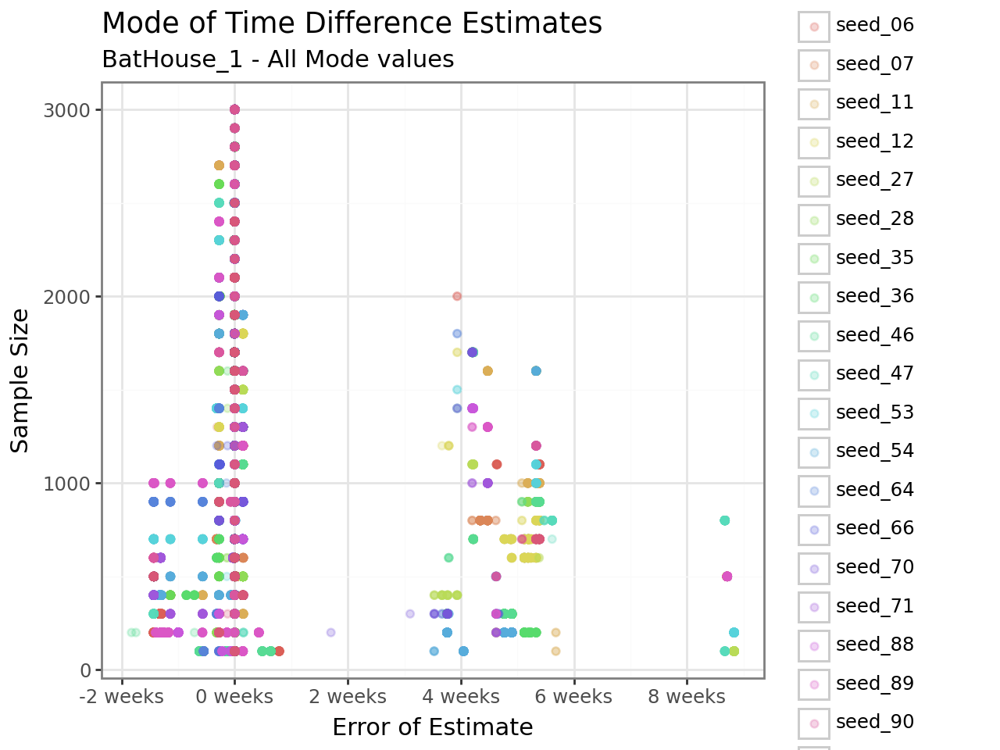

C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:606: PlotnineWarning: Saving 6.4 x 4.8 in image.
C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:607: PlotnineWarning: Filename: BatHouse_1_zero_results_all_mode.png


In [38]:
p = ggplot(bathouse_1_all_results_df, aes("error_estimate", "sample_size", colour = "set_seed"))  + geom_point(alpha = 0.25) + labs(title= "Mode of Time Difference Estimates", subtitle="BatHouse_1 - All Mode values", x = "Error of Estimate",  y = "Sample Size", colour = "Simulation seed") + theme_bw()
p.show()
p.save(filename = 'BatHouse_1_zero_results_all_mode.png', dpi = 300)

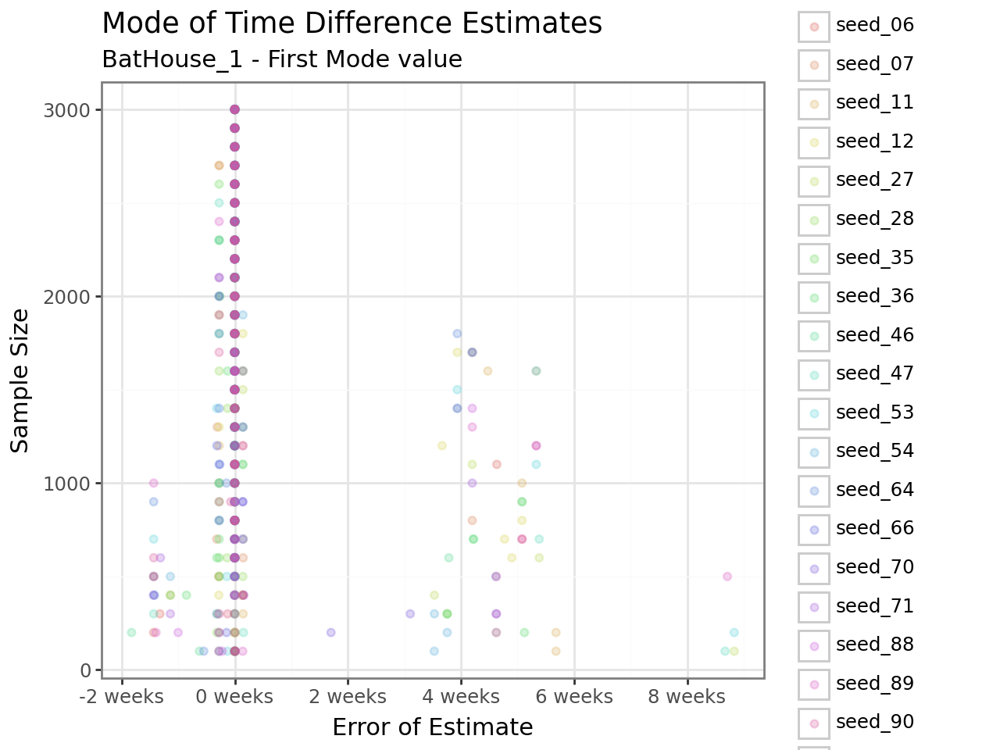

C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:606: PlotnineWarning: Saving 6.4 x 4.8 in image.
C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:607: PlotnineWarning: Filename: BatHouse_1_zero_results_first_mode.png


In [39]:
p = ggplot(bathouse_1_first_results_df, aes("error_estimate", "sample_size", colour = "set_seed")) + geom_point(alpha = 0.25) + labs(title= "Mode of Time Difference Estimates", subtitle="BatHouse_1 - First Mode value", x = "Error of Estimate",  y = "Sample Size", colour = "Simulation seed") + theme_bw()
p.show()
p.save(filename = 'BatHouse_1_zero_results_first_mode.png', dpi = 300)

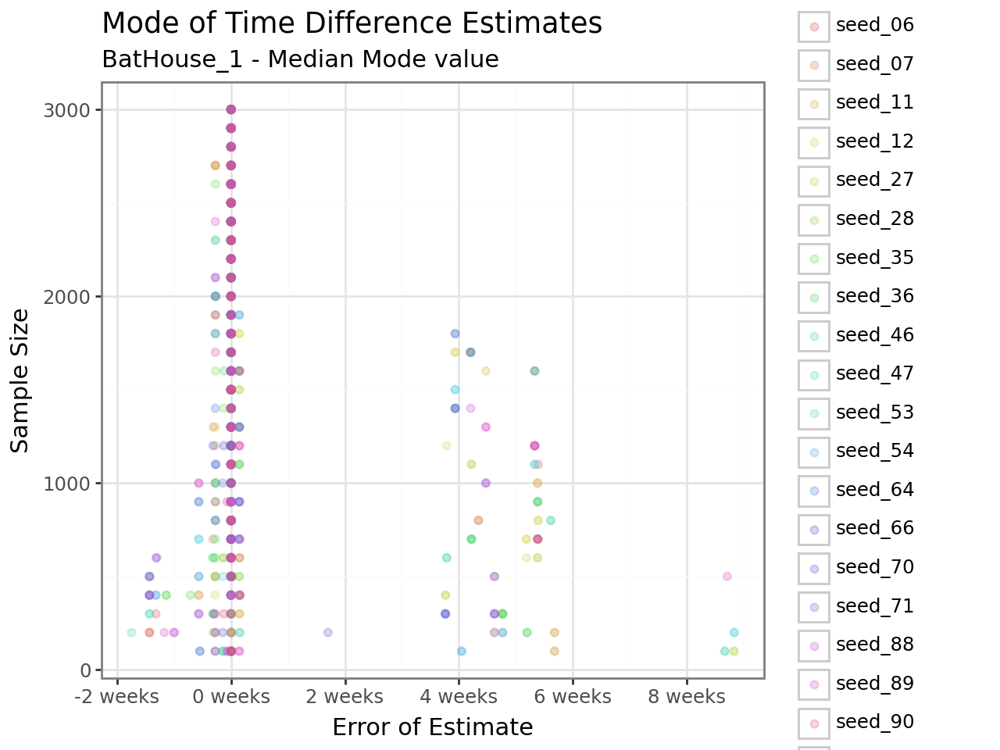

C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:606: PlotnineWarning: Saving 6.4 x 4.8 in image.
C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:607: PlotnineWarning: Filename: BatHouse_1_zero_results_median_mode.png


In [40]:
p = ggplot(bathouse_1_median_results_df, aes("error_estimate", "sample_size", colour = "set_seed"))  + geom_point(alpha = 0.25) + labs(title= "Mode of Time Difference Estimates", subtitle="BatHouse_1 - Median Mode value", x = "Error of Estimate",  y = "Sample Size", colour = "Simulation seed") + theme_bw()
p.show()
p.save(filename = 'BatHouse_1_zero_results_median_mode.png', dpi = 300)

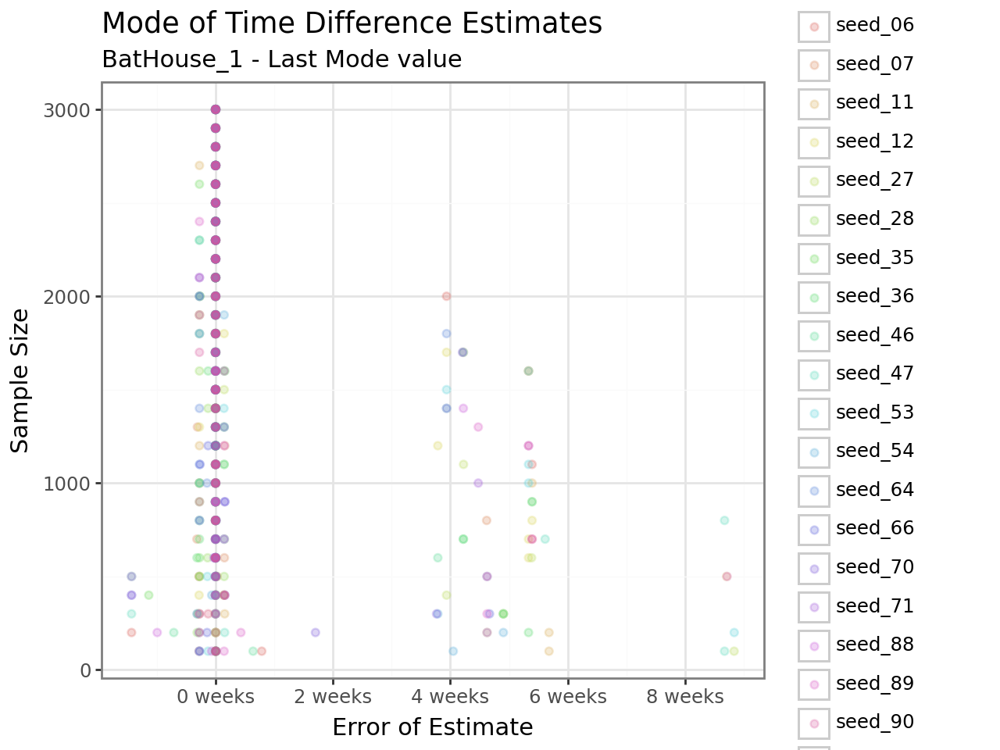

C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:606: PlotnineWarning: Saving 6.4 x 4.8 in image.
C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:607: PlotnineWarning: Filename: BatHouse_1_zero_results_last_mode.png


In [41]:
p = ggplot(bathouse_1_last_results_df, aes("error_estimate", "sample_size", colour = "set_seed"))  + geom_point(alpha = 0.25) + labs(title= "Mode of Time Difference Estimates", subtitle="BatHouse_1 - Last Mode value", x = "Error of Estimate",  y = "Sample Size", colour = "Simulation seed") + theme_bw()
p.show()
p.save(filename = 'BatHouse_1_zero_results_last_mode.png', dpi = 300)

In [42]:
#Create dictionary of BatHouse_1 results
bathouse_1_sim_results = {
    "all_results" : bathouse_1_all_KL_div_sim_results,
    "low_results" : bathouse_1_low_KL_div_sim_results,
    "very_low_results" : bathouse_1_very_low_KL_div_sim_results,
    "zero_results" : bathouse_1_zero_KL_div_sim_results
}

In [ ]:
with open(f'{output_dir}/bathouse_1_sim_results.pickle', 'wb') as handle:
        pickle.dump(bathouse_1_sim_results, handle, protocol=pickle.HIGHEST_PROTOCOL)

## Data processing Huxbear results

In [ ]:
#Create blank lists for results
all_results_list = []
first_results_list = []
median_results_list = []
last_results_list = []

for outer_key, inner_dict in dataframes.items():
    if re.match(re.compile(r'^Huxbear.*$'), outer_key):
        print(outer_key, type(inner_dict))
        seed_value = outer_key[8:15]
        print(seed_value)
        
        # Iterate over the inner dictionary
        for inner_key, df in inner_dict.items():
            if re.match(re.compile(r'.*_all_kl_div_error'), inner_key):
                print(inner_key, type(df))
                
                for final_key, final_df in df.items():
                    print(final_key)
                    ss_value = final_key[12:]
                    print(ss_value)
                    
                    if final_df.empty:
                        print('DataFrame is empty!')

                    else:
                        #create a copy of the dataframe before changing
                        new_df = final_df
                    
                        #create new columns of the sample size and the set seed of simnulation
                        new_df['sample_size'] = ss_value
                        new_df['set_seed'] = seed_value
                    
                        #calculate the mode values
                        first_mode = new_df.iloc[[0]]
                        last_mode = new_df.iloc[[-1]]
                        #median of the mode
                        new_df['median_diff'] = (new_df['time_diff'] - new_df['time_diff'].median()).abs()
                        median_mode = new_df.loc[new_df['median_diff'] == new_df['median_diff'].min()]
                    
                        #Add to dataframes
                        all_results_list.append(new_df)
                        first_results_list.append(first_mode)
                        median_results_list.append(median_mode)
                        last_results_list.append(last_mode)

huxbear_all_results_df = pd.concat(all_results_list, axis = 0, ignore_index = True)
huxbear_all_results_df[['sample_size']] = huxbear_all_results_df[['sample_size']].apply(pd.to_numeric)

huxbear_first_results_df = pd.concat(first_results_list, axis = 0, ignore_index = True)
huxbear_first_results_df[['sample_size']] = huxbear_first_results_df[['sample_size']].apply(pd.to_numeric)

huxbear_median_results_df = pd.concat(median_results_list, axis = 0, ignore_index = True)
huxbear_median_results_df[['sample_size']] = huxbear_median_results_df[['sample_size']].apply(pd.to_numeric)

huxbear_last_results_df = pd.concat(last_results_list, axis = 0, ignore_index = True)
huxbear_last_results_df[['sample_size']] = huxbear_last_results_df[['sample_size']].apply(pd.to_numeric)

In [46]:
huxbear_all_KL_div_sim_results = {
    "all_mode_results" : huxbear_all_results_df,
    "first_mode_results" : huxbear_first_results_df,
    "median_mode_results" : huxbear_median_results_df,
    "last_mode_results" : huxbear_last_results_df
}

In [47]:
#Remove NA values
huxbear_all_results_df.dropna(subset = ['error_estimate'], inplace = True)
huxbear_first_results_df.dropna(subset = ['error_estimate'], inplace = True)
huxbear_median_results_df.dropna(subset = ['error_estimate'], inplace = True)
huxbear_last_results_df.dropna(subset = ['error_estimate'], inplace = True)

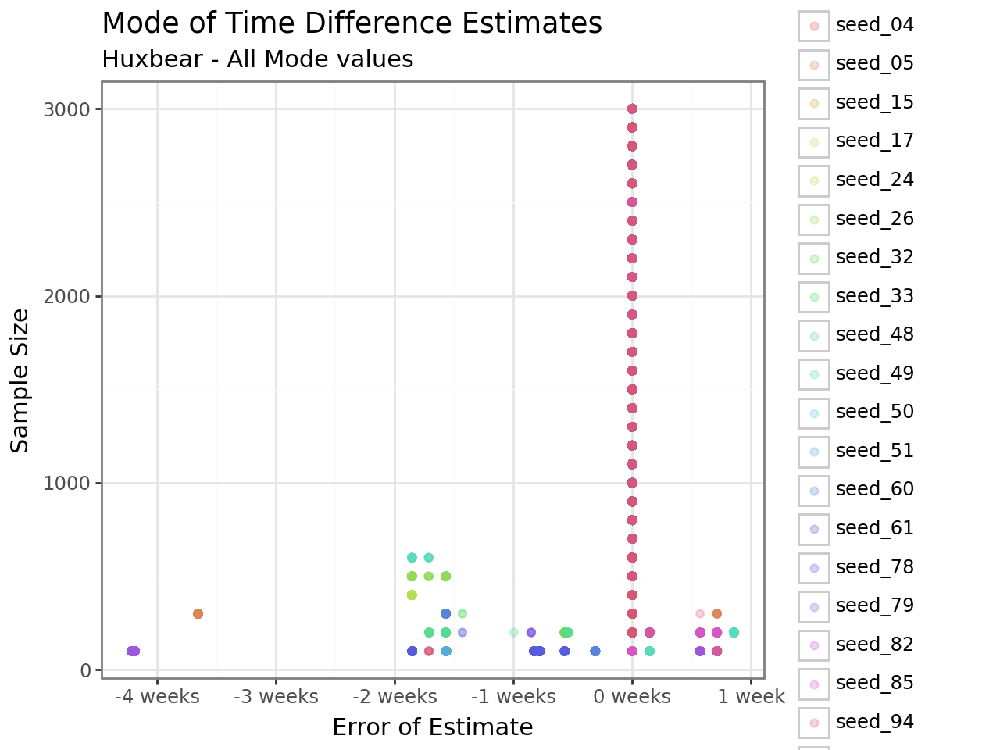

C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:606: PlotnineWarning: Saving 6.4 x 4.8 in image.
C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:607: PlotnineWarning: Filename: huxbear_all_results_all_mode.png


In [48]:
p = ggplot(huxbear_all_results_df, aes("error_estimate", "sample_size", colour = "set_seed"))  + geom_point(alpha = 0.25) + labs(title= "Mode of Time Difference Estimates", subtitle="Huxbear - All Mode values", x = "Error of Estimate",  y = "Sample Size", colour = "Simulation seed") + theme_bw()
p.show()
p.save(filename = 'huxbear_all_results_all_mode.png', dpi = 300)

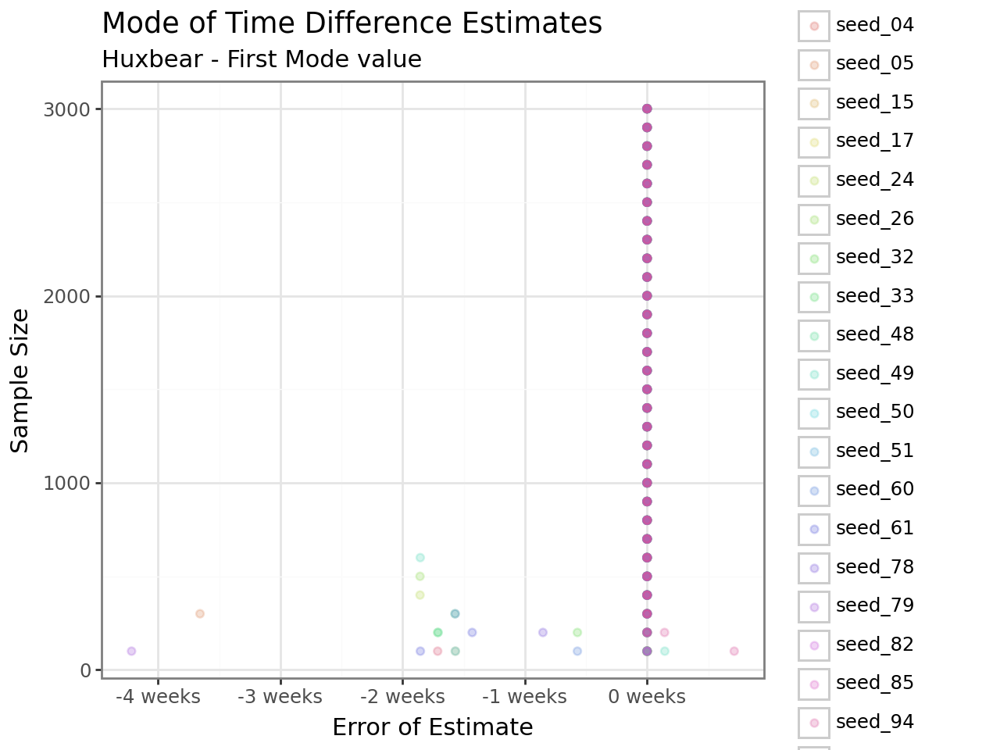

C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:606: PlotnineWarning: Saving 6.4 x 4.8 in image.
C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:607: PlotnineWarning: Filename: huxbear_all_results_first_mode.png


In [49]:
p = ggplot(huxbear_first_results_df, aes("error_estimate", "sample_size", colour = "set_seed")) + geom_point(alpha = 0.25) + labs(title= "Mode of Time Difference Estimates", subtitle="Huxbear - First Mode value", x = "Error of Estimate",  y = "Sample Size", colour = "Simulation seed") + theme_bw()
p.show()
p.save(filename = 'huxbear_all_results_first_mode.png', dpi = 300)

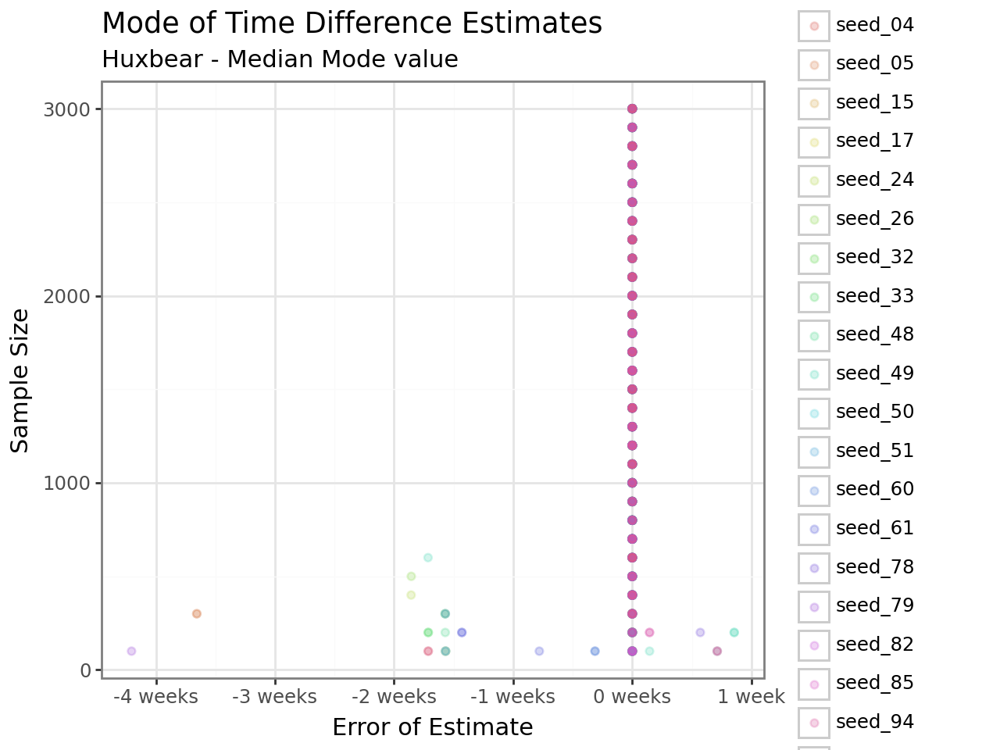

C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:606: PlotnineWarning: Saving 6.4 x 4.8 in image.
C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:607: PlotnineWarning: Filename: huxbear_all_results_median_mode.png


In [50]:
p = ggplot(huxbear_median_results_df, aes("error_estimate", "sample_size", colour = "set_seed"))  + geom_point(alpha = 0.25) + labs(title= "Mode of Time Difference Estimates", subtitle="Huxbear - Median Mode value", x = "Error of Estimate",  y = "Sample Size", colour = "Simulation seed") + theme_bw()
p.show()
p.save(filename = 'huxbear_all_results_median_mode.png', dpi = 300)

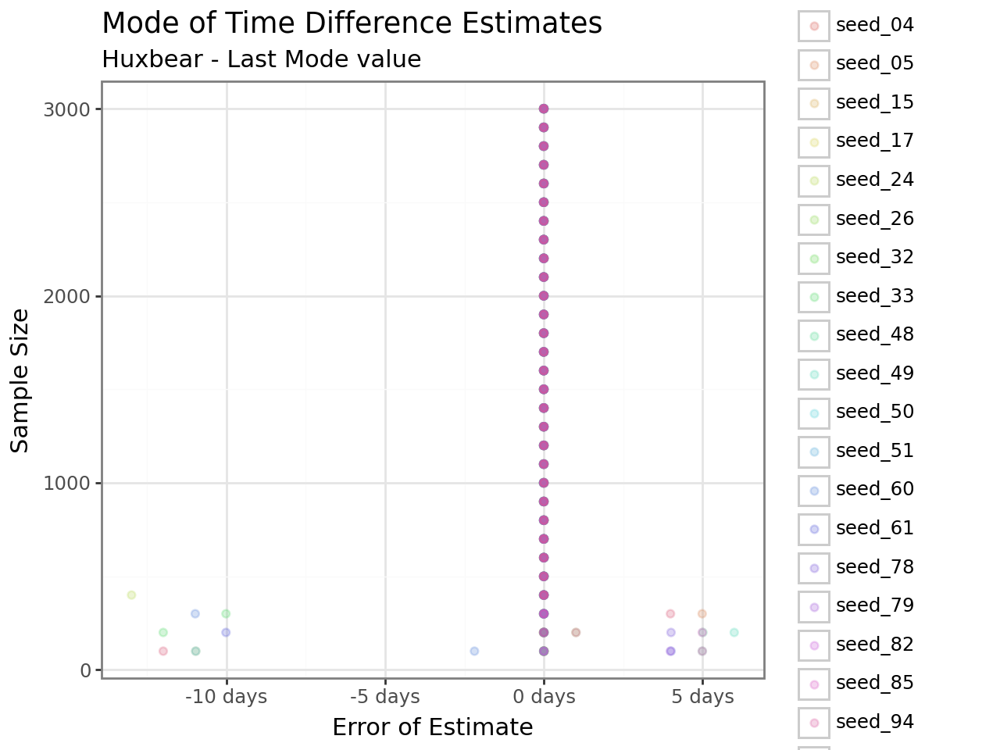

C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:606: PlotnineWarning: Saving 6.4 x 4.8 in image.
C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:607: PlotnineWarning: Filename: huxbear_all_results_last_mode.png


In [51]:
p = ggplot(huxbear_last_results_df, aes("error_estimate", "sample_size", colour = "set_seed"))  + geom_point(alpha = 0.25) + labs(title= "Mode of Time Difference Estimates", subtitle="Huxbear - Last Mode value", x = "Error of Estimate",  y = "Sample Size", colour = "Simulation seed") + theme_bw()
p.show()
p.save(filename = 'huxbear_all_results_last_mode.png', dpi = 300)

In [ ]:
#Create blank lists for results
all_results_list = []
first_results_list = []
median_results_list = []
last_results_list = []

for outer_key, inner_dict in dataframes.items():
    if re.match(re.compile(r'^Huxbear.*$'), outer_key):
        print(outer_key, type(inner_dict))
        seed_value = outer_key[8:15]
        print(seed_value)
        
        # Iterate over the inner dictionary
        for inner_key, df in inner_dict.items():
            if re.match(re.compile(r'.*_low_kl_div_error'), inner_key):
                print(inner_key, type(df))
                
                for final_key, final_df in df.items():
                    print(final_key)
                    ss_value = final_key[12:]
                    print(ss_value)
                    
                    if final_df.empty:
                        print('DataFrame is empty!')

                    else:
                        #create a copy of the dataframe before changing
                        new_df = final_df
                    
                        #create new columns of the sample size and the set seed of simnulation
                        new_df['sample_size'] = ss_value
                        new_df['set_seed'] = seed_value
                    
                        #calculate the mode values
                        first_mode = new_df.iloc[[0]]
                        last_mode = new_df.iloc[[-1]]
                        #median of the mode
                        new_df['median_diff'] = (new_df['time_diff'] - new_df['time_diff'].median()).abs()
                        median_mode = new_df.loc[new_df['median_diff'] == new_df['median_diff'].min()]
                    
                        #Add to dataframes
                        all_results_list.append(new_df)
                        first_results_list.append(first_mode)
                        median_results_list.append(median_mode)
                        last_results_list.append(last_mode)

huxbear_all_results_df = pd.concat(all_results_list, axis = 0, ignore_index = True)
huxbear_all_results_df[['sample_size']] = huxbear_all_results_df[['sample_size']].apply(pd.to_numeric)

huxbear_first_results_df = pd.concat(first_results_list, axis = 0, ignore_index = True)
huxbear_first_results_df[['sample_size']] = huxbear_first_results_df[['sample_size']].apply(pd.to_numeric)

huxbear_median_results_df = pd.concat(median_results_list, axis = 0, ignore_index = True)
huxbear_median_results_df[['sample_size']] = huxbear_median_results_df[['sample_size']].apply(pd.to_numeric)

huxbear_last_results_df = pd.concat(last_results_list, axis = 0, ignore_index = True)
huxbear_last_results_df[['sample_size']] = huxbear_last_results_df[['sample_size']].apply(pd.to_numeric)

In [53]:
huxbear_low_KL_div_sim_results = {
    "all_mode_results" : huxbear_all_results_df,
    "first_mode_results" : huxbear_first_results_df,
    "median_mode_results" : huxbear_median_results_df,
    "last_mode_results" : huxbear_last_results_df
}

In [54]:
#Remove NA values
huxbear_all_results_df.dropna(subset = ['error_estimate'], inplace = True)
huxbear_first_results_df.dropna(subset = ['error_estimate'], inplace = True)
huxbear_median_results_df.dropna(subset = ['error_estimate'], inplace = True)
huxbear_last_results_df.dropna(subset = ['error_estimate'], inplace = True)

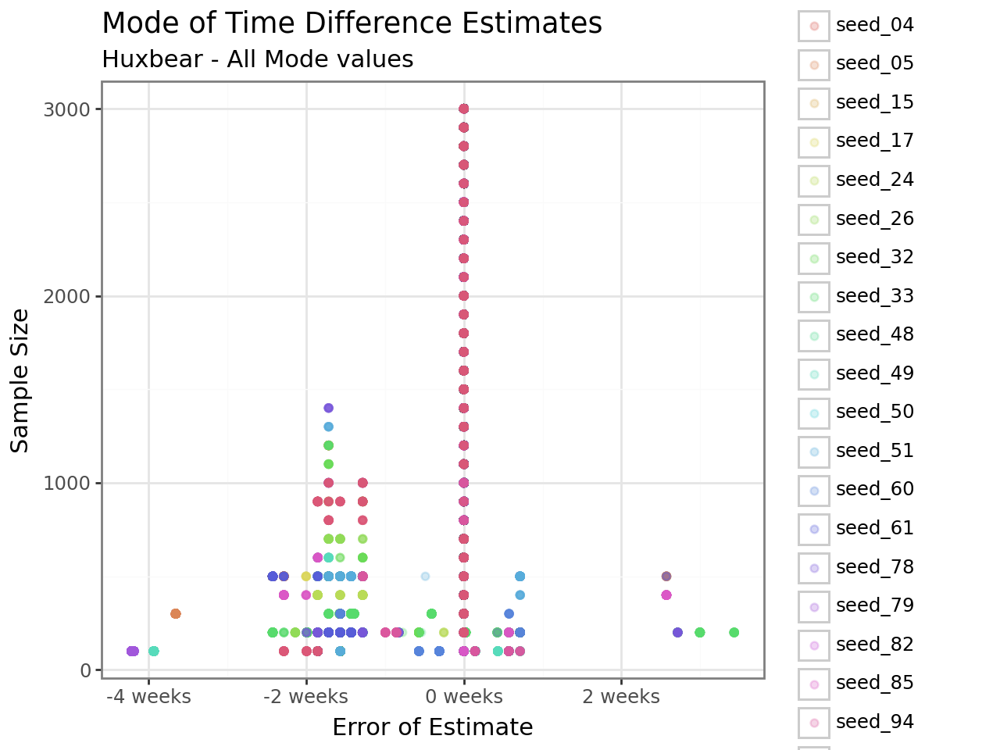

C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:606: PlotnineWarning: Saving 6.4 x 4.8 in image.
C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:607: PlotnineWarning: Filename: huxbear_low_results_all_mode.png


In [55]:
p = ggplot(huxbear_all_results_df, aes("error_estimate", "sample_size", colour = "set_seed"))  + geom_point(alpha = 0.25) + labs(title= "Mode of Time Difference Estimates", subtitle="Huxbear - All Mode values", x = "Error of Estimate",  y = "Sample Size", colour = "Simulation seed") + theme_bw()
p.show()
p.save(filename = 'huxbear_low_results_all_mode.png', dpi = 300)

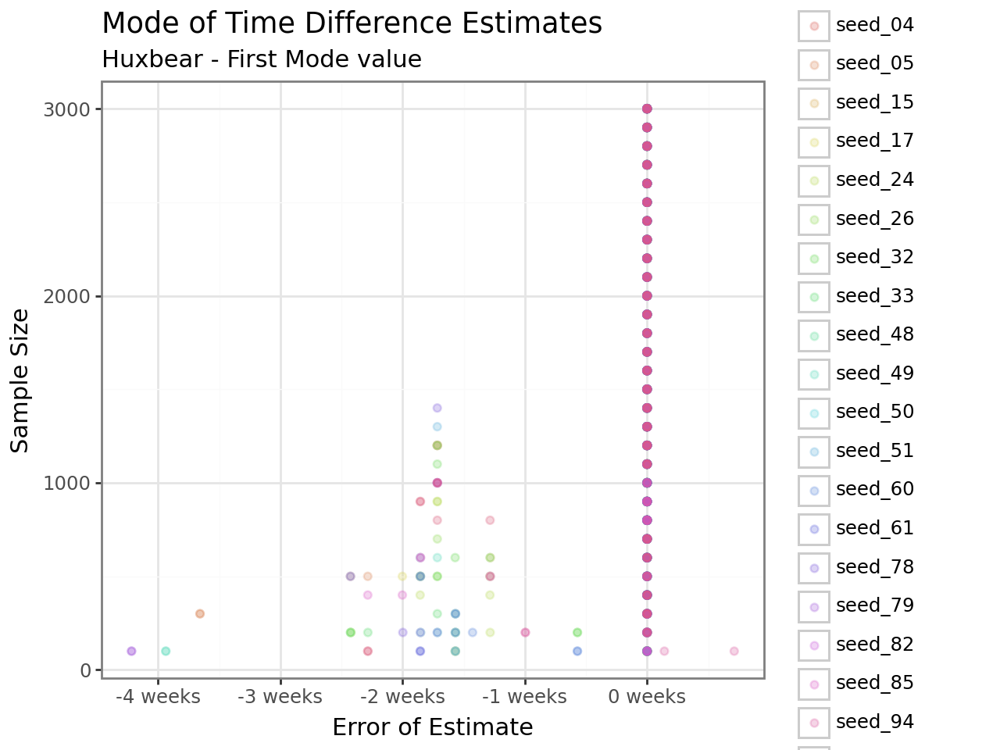

C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:606: PlotnineWarning: Saving 6.4 x 4.8 in image.
C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:607: PlotnineWarning: Filename: huxbear_low_results_first_mode.png


In [56]:
p = ggplot(huxbear_first_results_df, aes("error_estimate", "sample_size", colour = "set_seed")) + geom_point(alpha = 0.25) + labs(title= "Mode of Time Difference Estimates", subtitle="Huxbear - First Mode value", x = "Error of Estimate",  y = "Sample Size", colour = "Simulation seed") + theme_bw()
p.show()
p.save(filename = 'huxbear_low_results_first_mode.png', dpi = 300)

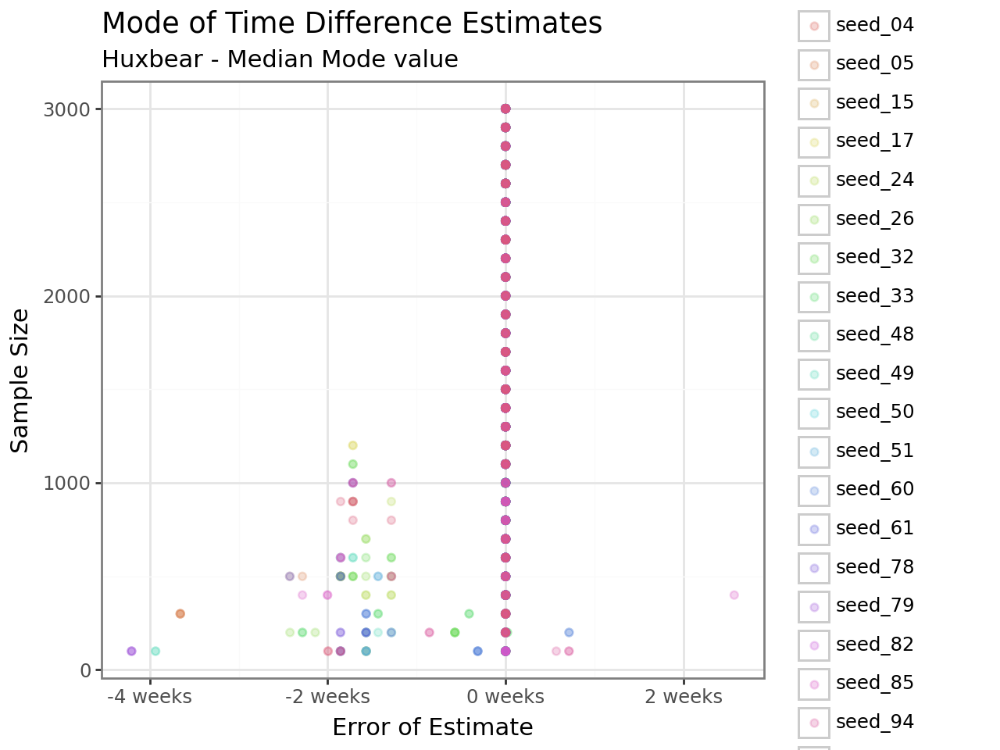

C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:606: PlotnineWarning: Saving 6.4 x 4.8 in image.
C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:607: PlotnineWarning: Filename: huxbear_low_results_median_mode.png


In [57]:
p = ggplot(huxbear_median_results_df, aes("error_estimate", "sample_size", colour = "set_seed"))  + geom_point(alpha = 0.25) + labs(title= "Mode of Time Difference Estimates", subtitle="Huxbear - Median Mode value", x = "Error of Estimate",  y = "Sample Size", colour = "Simulation seed") + theme_bw()
p.show()
p.save(filename = 'huxbear_low_results_median_mode.png', dpi = 300)

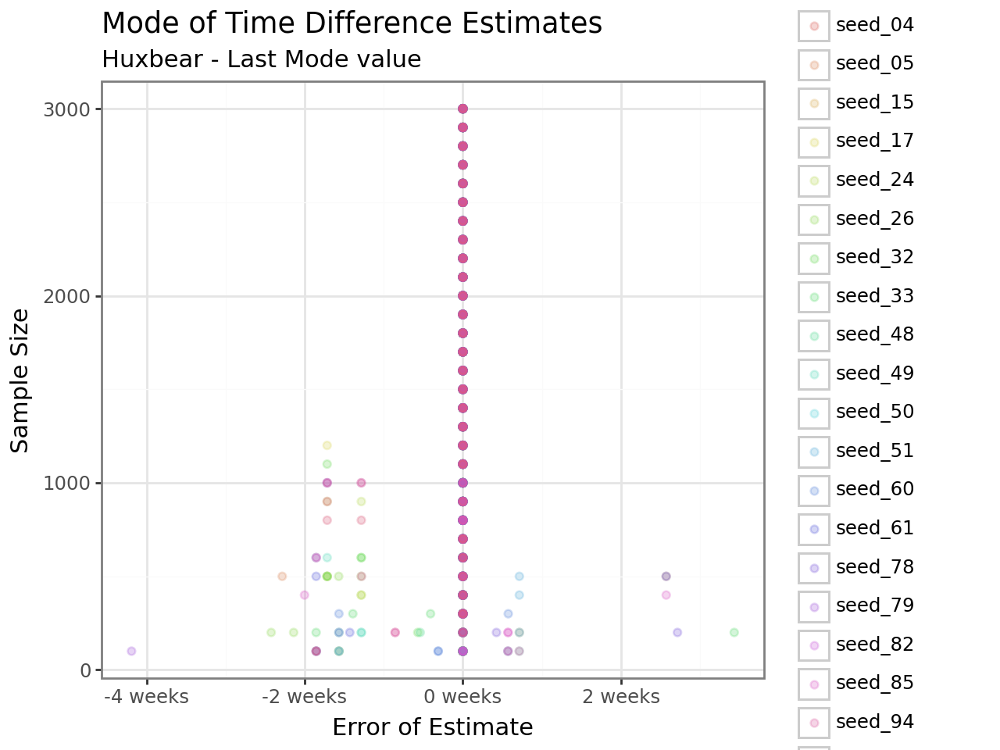

C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:606: PlotnineWarning: Saving 6.4 x 4.8 in image.
C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:607: PlotnineWarning: Filename: huxbear_low_results_last_mode.png


In [58]:
p = ggplot(huxbear_last_results_df, aes("error_estimate", "sample_size", colour = "set_seed"))  + geom_point(alpha = 0.25) + labs(title= "Mode of Time Difference Estimates", subtitle="Huxbear - Last Mode value", x = "Error of Estimate",  y = "Sample Size", colour = "Simulation seed") + theme_bw()
p.show()
p.save(filename = 'huxbear_low_results_last_mode.png', dpi = 300)

In [ ]:
#Create blank lists for results
all_results_list = []
first_results_list = []
median_results_list = []
last_results_list = []

for outer_key, inner_dict in dataframes.items():
    if re.match(re.compile(r'^Huxbear.*$'), outer_key):
        print(outer_key, type(inner_dict))
        seed_value = outer_key[8:15]
        print(seed_value)
        
        # Iterate over the inner dictionary
        for inner_key, df in inner_dict.items():
            if re.match(re.compile(r'.*_very_low_kl_div_error'), inner_key):
                print(inner_key, type(df))
                
                for final_key, final_df in df.items():
                    print(final_key)
                    ss_value = final_key[12:]
                    print(ss_value)
                    
                    if final_df.empty:
                        print('DataFrame is empty!')

                    else:
                        #create a copy of the dataframe before changing
                        new_df = final_df
                    
                        #create new columns of the sample size and the set seed of simnulation
                        new_df['sample_size'] = ss_value
                        new_df['set_seed'] = seed_value
                    
                        #calculate the mode values
                        first_mode = new_df.iloc[[0]]
                        last_mode = new_df.iloc[[-1]]
                        #median of the mode
                        new_df['median_diff'] = (new_df['time_diff'] - new_df['time_diff'].median()).abs()
                        median_mode = new_df.loc[new_df['median_diff'] == new_df['median_diff'].min()]
                    
                        #Add to dataframes
                        all_results_list.append(new_df)
                        first_results_list.append(first_mode)
                        median_results_list.append(median_mode)
                        last_results_list.append(last_mode)

huxbear_all_results_df = pd.concat(all_results_list, axis = 0, ignore_index = True)
huxbear_all_results_df[['sample_size']] = huxbear_all_results_df[['sample_size']].apply(pd.to_numeric)

huxbear_first_results_df = pd.concat(first_results_list, axis = 0, ignore_index = True)
huxbear_first_results_df[['sample_size']] = huxbear_first_results_df[['sample_size']].apply(pd.to_numeric)

huxbear_median_results_df = pd.concat(median_results_list, axis = 0, ignore_index = True)
huxbear_median_results_df[['sample_size']] = huxbear_median_results_df[['sample_size']].apply(pd.to_numeric)

huxbear_last_results_df = pd.concat(last_results_list, axis = 0, ignore_index = True)
huxbear_last_results_df[['sample_size']] = huxbear_last_results_df[['sample_size']].apply(pd.to_numeric)

In [60]:
huxbear_very_low_KL_div_sim_results = {
    "all_mode_results" : huxbear_all_results_df,
    "first_mode_results" : huxbear_first_results_df,
    "median_mode_results" : huxbear_median_results_df,
    "last_mode_results" : huxbear_last_results_df
}

In [61]:
#Remove NA values
huxbear_all_results_df.dropna(subset = ['error_estimate'], inplace = True)
huxbear_first_results_df.dropna(subset = ['error_estimate'], inplace = True)
huxbear_median_results_df.dropna(subset = ['error_estimate'], inplace = True)
huxbear_last_results_df.dropna(subset = ['error_estimate'], inplace = True)

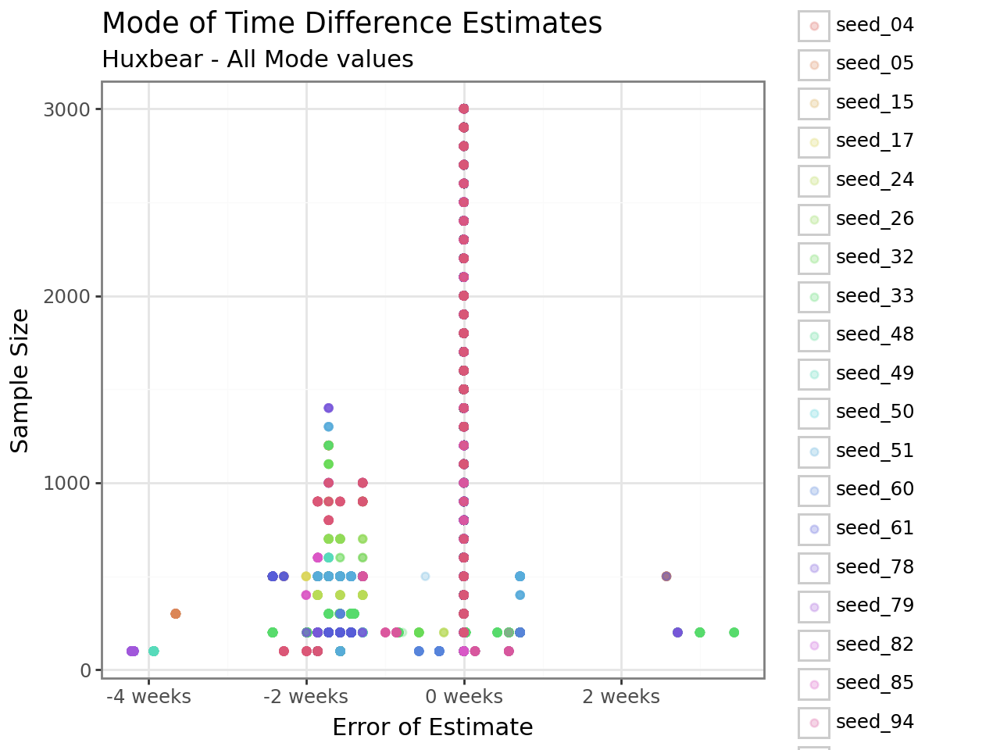

C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:606: PlotnineWarning: Saving 6.4 x 4.8 in image.
C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:607: PlotnineWarning: Filename: huxbear_very_low_results_all_mode.png


In [62]:
p = ggplot(huxbear_all_results_df, aes("error_estimate", "sample_size", colour = "set_seed"))  + geom_point(alpha = 0.25) + labs(title= "Mode of Time Difference Estimates", subtitle="Huxbear - All Mode values", x = "Error of Estimate",  y = "Sample Size", colour = "Simulation seed") + theme_bw()
p.show()
p.save(filename = 'huxbear_very_low_results_all_mode.png', dpi = 300)

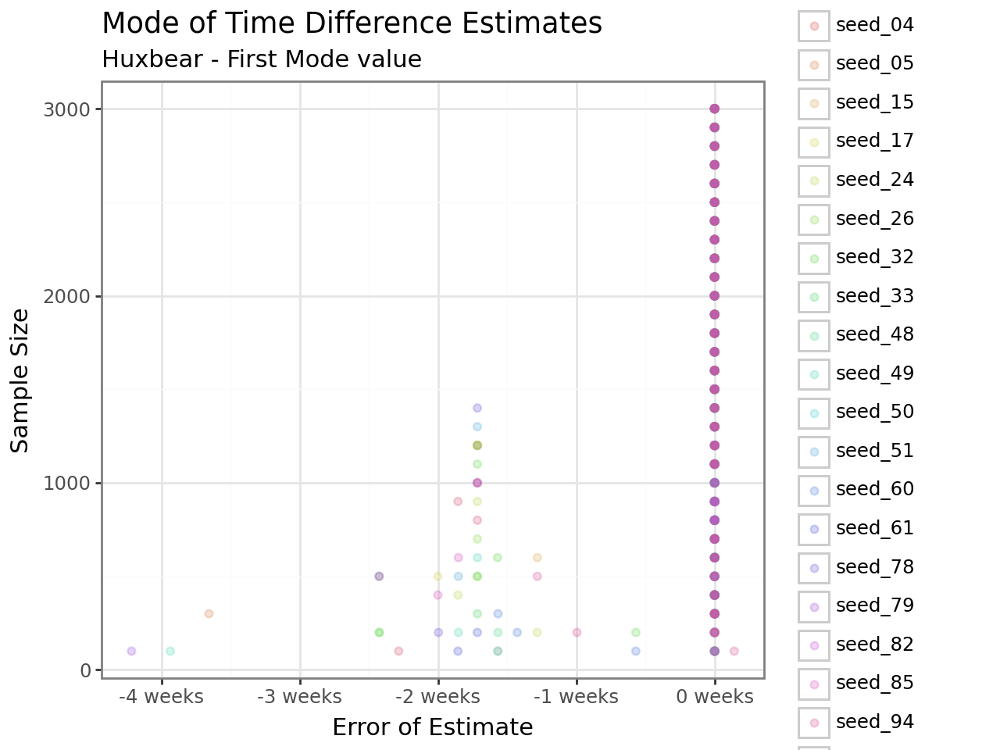

C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:606: PlotnineWarning: Saving 6.4 x 4.8 in image.
C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:607: PlotnineWarning: Filename: huxbear_very_low_results_first_mode.png


In [63]:
p = ggplot(huxbear_first_results_df, aes("error_estimate", "sample_size", colour = "set_seed")) + geom_point(alpha = 0.25) + labs(title= "Mode of Time Difference Estimates", subtitle="Huxbear - First Mode value", x = "Error of Estimate",  y = "Sample Size", colour = "Simulation seed") + theme_bw()
p.show()
p.save(filename = 'huxbear_very_low_results_first_mode.png', dpi = 300)

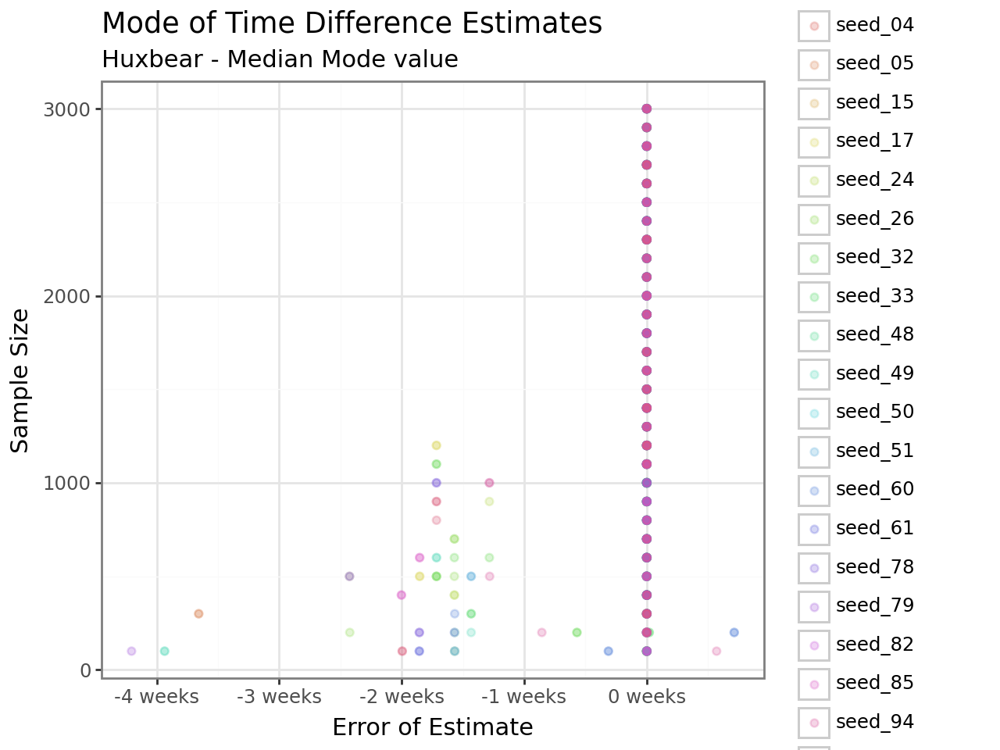

C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:606: PlotnineWarning: Saving 6.4 x 4.8 in image.
C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:607: PlotnineWarning: Filename: huxbear_very_low_results_median_mode.png


In [64]:
p = ggplot(huxbear_median_results_df, aes("error_estimate", "sample_size", colour = "set_seed"))  + geom_point(alpha = 0.25) + labs(title= "Mode of Time Difference Estimates", subtitle="Huxbear - Median Mode value", x = "Error of Estimate",  y = "Sample Size", colour = "Simulation seed") + theme_bw()
p.show()
p.save(filename = 'huxbear_very_low_results_median_mode.png', dpi = 300)

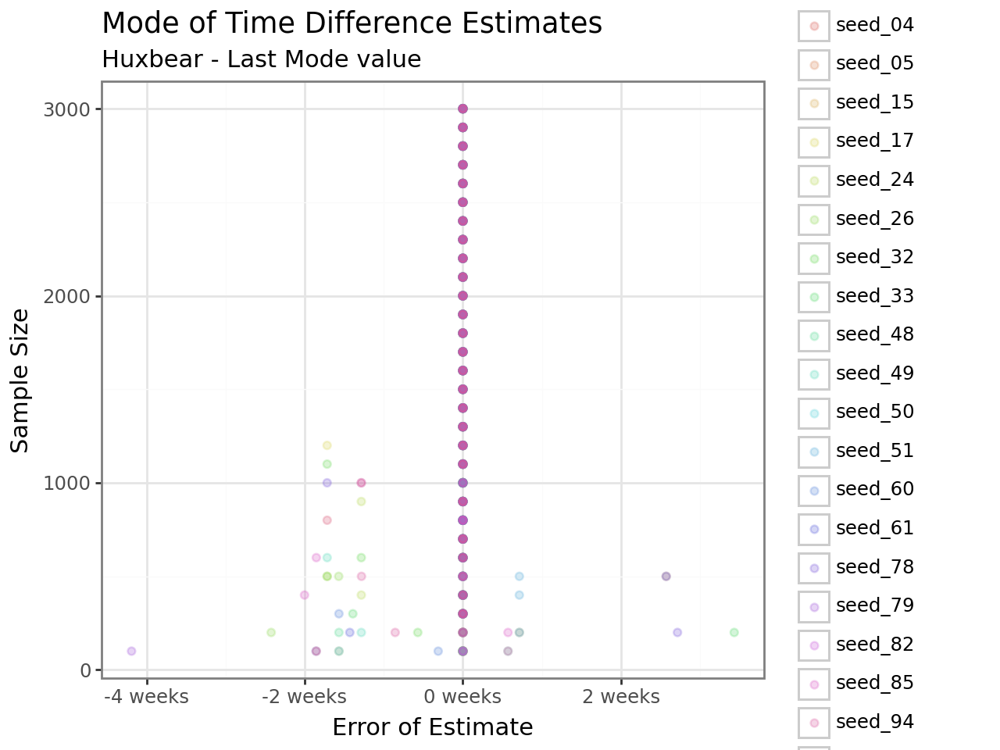

C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:606: PlotnineWarning: Saving 6.4 x 4.8 in image.
C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:607: PlotnineWarning: Filename: huxbear_very_low_results_last_mode.png


In [65]:
p = ggplot(huxbear_last_results_df, aes("error_estimate", "sample_size", colour = "set_seed"))  + geom_point(alpha = 0.25) + labs(title= "Mode of Time Difference Estimates", subtitle="Huxbear - Last Mode value", x = "Error of Estimate",  y = "Sample Size", colour = "Simulation seed") + theme_bw()
p.show()
p.save(filename = 'huxbear_very_low_results_last_mode.png', dpi = 300)

In [ ]:
#Create blank lists for results
all_results_list = []
first_results_list = []
median_results_list = []
last_results_list = []

for outer_key, inner_dict in dataframes.items():
    if re.match(re.compile(r'^Huxbear.*$'), outer_key):
        print(outer_key, type(inner_dict))
        seed_value = outer_key[8:15]
        print(seed_value)
        
        # Iterate over the inner dictionary
        for inner_key, df in inner_dict.items():
            if re.match(re.compile(r'.*_zero_kl_div_error'), inner_key):
                print(inner_key, type(df))
                
                for final_key, final_df in df.items():
                    print(final_key)
                    ss_value = final_key[12:]
                    print(ss_value)
                    
                    if final_df.empty:
                        print('DataFrame is empty!')

                    else:
                        #create a copy of the dataframe before changing
                        new_df = final_df
                    
                        #create new columns of the sample size and the set seed of simnulation
                        new_df['sample_size'] = ss_value
                        new_df['set_seed'] = seed_value
                    
                        #calculate the mode values
                        first_mode = new_df.iloc[[0]]
                        last_mode = new_df.iloc[[-1]]
                        #median of the mode
                        new_df['median_diff'] = (new_df['time_diff'] - new_df['time_diff'].median()).abs()
                        median_mode = new_df.loc[new_df['median_diff'] == new_df['median_diff'].min()]
                    
                        #Add to dataframes
                        all_results_list.append(new_df)
                        first_results_list.append(first_mode)
                        median_results_list.append(median_mode)
                        last_results_list.append(last_mode)

huxbear_all_results_df = pd.concat(all_results_list, axis = 0, ignore_index = True)
huxbear_all_results_df[['sample_size']] = huxbear_all_results_df[['sample_size']].apply(pd.to_numeric)

huxbear_first_results_df = pd.concat(first_results_list, axis = 0, ignore_index = True)
huxbear_first_results_df[['sample_size']] = huxbear_first_results_df[['sample_size']].apply(pd.to_numeric)

huxbear_median_results_df = pd.concat(median_results_list, axis = 0, ignore_index = True)
huxbear_median_results_df[['sample_size']] = huxbear_median_results_df[['sample_size']].apply(pd.to_numeric)

huxbear_last_results_df = pd.concat(last_results_list, axis = 0, ignore_index = True)
huxbear_last_results_df[['sample_size']] = huxbear_last_results_df[['sample_size']].apply(pd.to_numeric)

In [67]:
#Put results into dictionary
huxbear_zero_KL_div_sim_results = {
    "all_mode_results" : huxbear_all_results_df,
    "first_mode_results" : huxbear_first_results_df,
    "median_mode_results" : huxbear_median_results_df,
    "last_mode_results" : huxbear_last_results_df
}

In [68]:
#Remove NA values
huxbear_all_results_df.dropna(subset = ['error_estimate'], inplace = True)
huxbear_first_results_df.dropna(subset = ['error_estimate'], inplace = True)
huxbear_median_results_df.dropna(subset = ['error_estimate'], inplace = True)
huxbear_last_results_df.dropna(subset = ['error_estimate'], inplace = True)

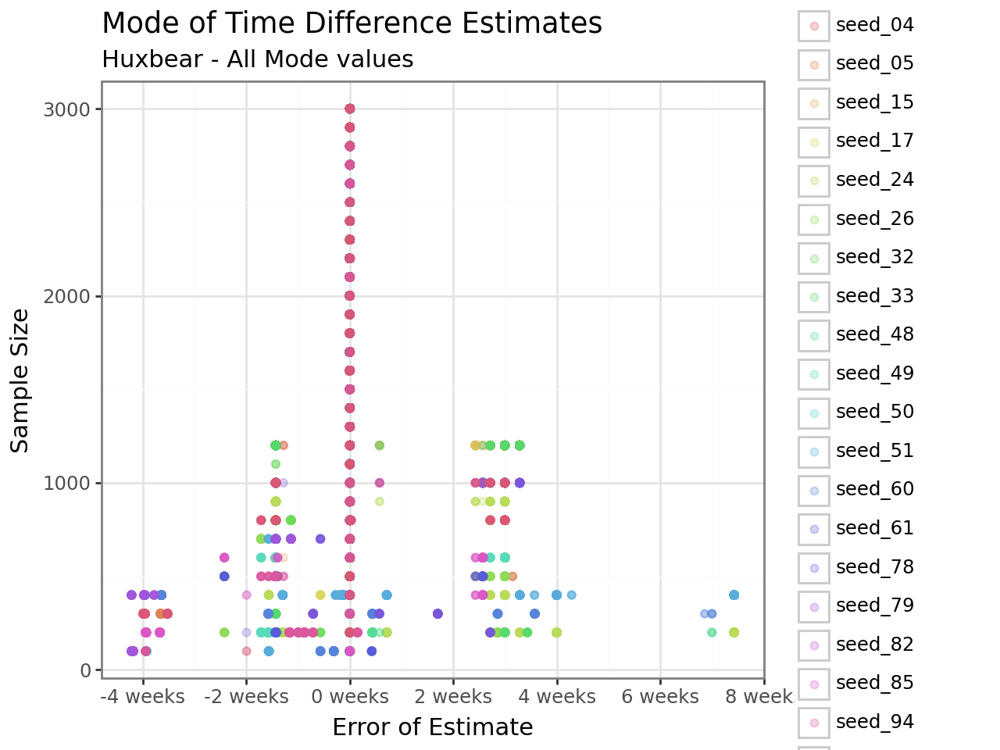

C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:606: PlotnineWarning: Saving 6.4 x 4.8 in image.
C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:607: PlotnineWarning: Filename: huxbear_zero_results_all_mode.png


In [69]:
p = ggplot(huxbear_all_results_df, aes("error_estimate", "sample_size", colour = "set_seed"))  + geom_point(alpha = 0.25) + labs(title= "Mode of Time Difference Estimates", subtitle="Huxbear - All Mode values", x = "Error of Estimate",  y = "Sample Size", colour = "Simulation seed") + theme_bw()
p.show()
p.save(filename = 'huxbear_zero_results_all_mode.png', dpi = 300)

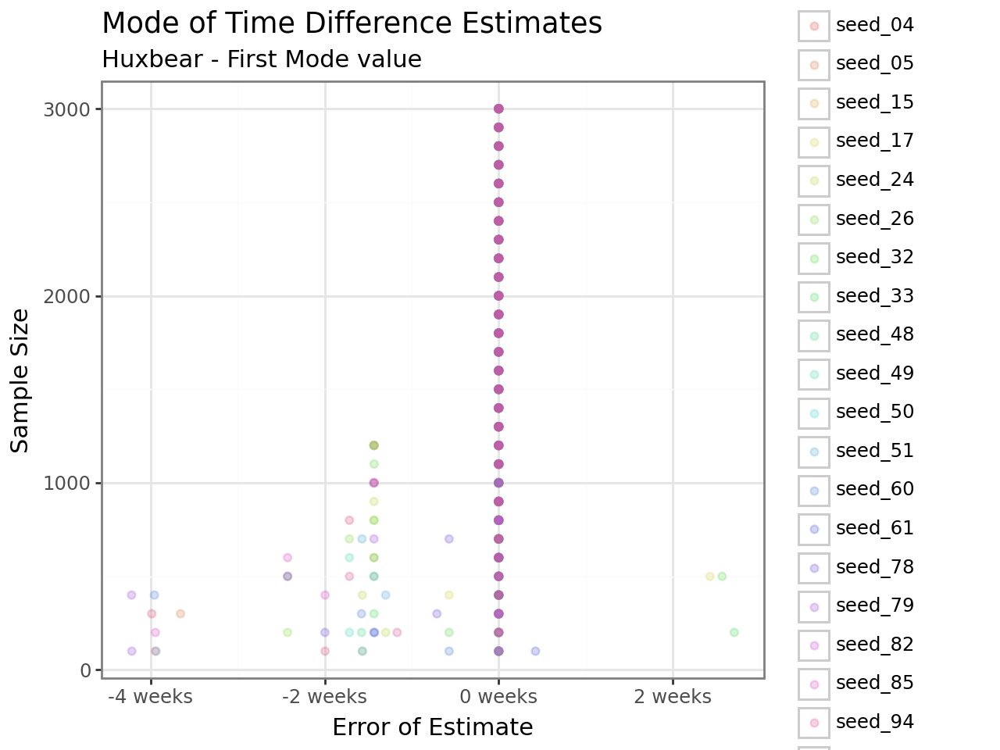

C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:606: PlotnineWarning: Saving 6.4 x 4.8 in image.
C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:607: PlotnineWarning: Filename: huxbear_zero_results_first_mode.png


In [70]:
p = ggplot(huxbear_first_results_df, aes("error_estimate", "sample_size", colour = "set_seed")) + geom_point(alpha = 0.25) + labs(title= "Mode of Time Difference Estimates", subtitle="Huxbear - First Mode value", x = "Error of Estimate",  y = "Sample Size", colour = "Simulation seed") + theme_bw()
p.show()
p.save(filename = 'huxbear_zero_results_first_mode.png', dpi = 300)

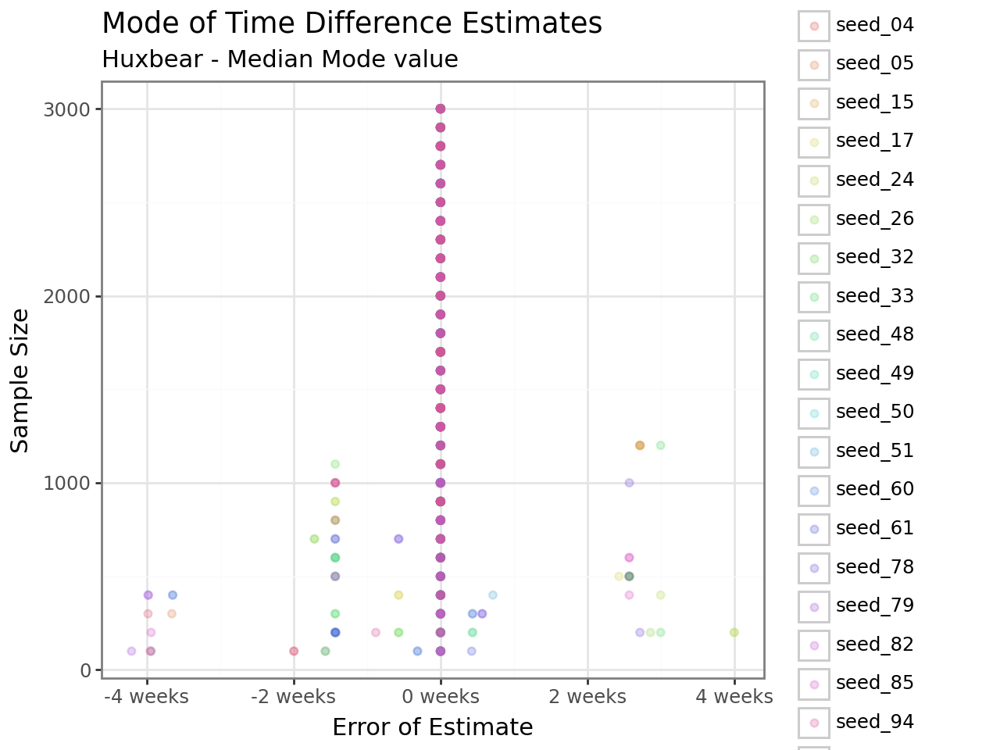

C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:606: PlotnineWarning: Saving 6.4 x 4.8 in image.
C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:607: PlotnineWarning: Filename: huxbear_zero_results_median_mode.png


In [71]:
p = ggplot(huxbear_median_results_df, aes("error_estimate", "sample_size", colour = "set_seed"))  + geom_point(alpha = 0.25) + labs(title= "Mode of Time Difference Estimates", subtitle="Huxbear - Median Mode value", x = "Error of Estimate",  y = "Sample Size", colour = "Simulation seed") + theme_bw()
p.show()
p.save(filename = 'huxbear_zero_results_median_mode.png', dpi = 300)

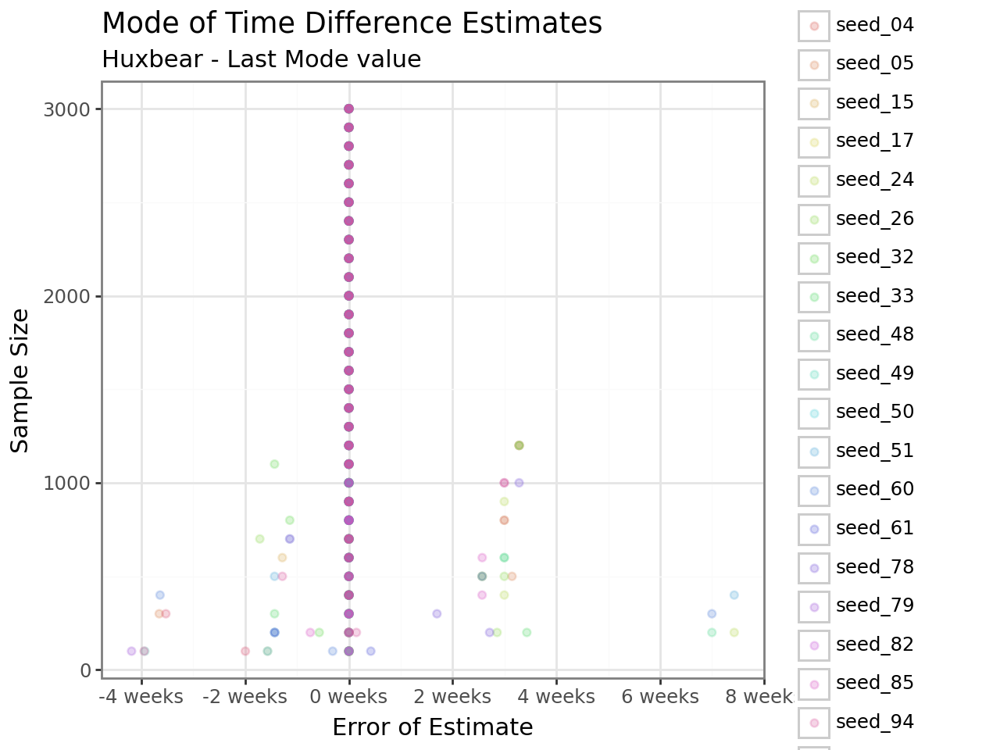

C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:606: PlotnineWarning: Saving 6.4 x 4.8 in image.
C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:607: PlotnineWarning: Filename: huxbear_zero_results_last_mode.png


In [72]:
p = ggplot(huxbear_last_results_df, aes("error_estimate", "sample_size", colour = "set_seed"))  + geom_point(alpha = 0.25) + labs(title= "Mode of Time Difference Estimates", subtitle="Huxbear - Last Mode value", x = "Error of Estimate",  y = "Sample Size", colour = "Simulation seed") + theme_bw()
p.show()
p.save(filename = 'huxbear_zero_results_last_mode.png', dpi = 300)

In [73]:
#Create dictionary of huxbear results
huxbear_sim_results = {
    "all_results" : huxbear_all_KL_div_sim_results,
    "low_results" : huxbear_low_KL_div_sim_results,
    "very_low_results" : huxbear_very_low_KL_div_sim_results,
    "zero_results" : huxbear_zero_KL_div_sim_results
}

In [ ]:
with open(f'{output_dir}/huxbear_sim_results.pickle', 'wb') as handle:
        pickle.dump(huxbear_sim_results, handle, protocol=pickle.HIGHEST_PROTOCOL)

## Data processing Olchard A results

In [ ]:
#Create blank lists for results
all_results_list = []
first_results_list = []
median_results_list = []
last_results_list = []

for outer_key, inner_dict in dataframes.items():
    if re.match(re.compile(r'^olchard_A.*$'), outer_key):
        print(outer_key, type(inner_dict))
        seed_value = outer_key[10:17]
        print(seed_value)
        
        # Iterate over the inner dictionary
        for inner_key, df in inner_dict.items():
            if re.match(re.compile(r'.*_all_kl_div_error'), inner_key):
                print(inner_key, type(df))
                
                for final_key, final_df in df.items():
                    print(final_key)
                    ss_value = final_key[12:]
                    print(ss_value)
                    
                    if final_df.empty:
                        print('DataFrame is empty!')

                    else:
                        #create a copy of the dataframe before changing
                        new_df = final_df
                    
                        #create new columns of the sample size and the set seed of simnulation
                        new_df['sample_size'] = ss_value
                        new_df['set_seed'] = seed_value
                    
                        #calculate the mode values
                        first_mode = new_df.iloc[[0]]
                        last_mode = new_df.iloc[[-1]]
                        #median of the mode
                        new_df['median_diff'] = (new_df['time_diff'] - new_df['time_diff'].median()).abs()
                        median_mode = new_df.loc[new_df['median_diff'] == new_df['median_diff'].min()]
                    
                        #Add to dataframes
                        all_results_list.append(new_df)
                        first_results_list.append(first_mode)
                        median_results_list.append(median_mode)
                        last_results_list.append(last_mode)

olchard_A_all_results_df = pd.concat(all_results_list, axis = 0, ignore_index = True)
olchard_A_all_results_df[['sample_size']] = olchard_A_all_results_df[['sample_size']].apply(pd.to_numeric)

olchard_A_first_results_df = pd.concat(first_results_list, axis = 0, ignore_index = True)
olchard_A_first_results_df[['sample_size']] = olchard_A_first_results_df[['sample_size']].apply(pd.to_numeric)

olchard_A_median_results_df = pd.concat(median_results_list, axis = 0, ignore_index = True)
olchard_A_median_results_df[['sample_size']] = olchard_A_median_results_df[['sample_size']].apply(pd.to_numeric)

olchard_A_last_results_df = pd.concat(last_results_list, axis = 0, ignore_index = True)
olchard_A_last_results_df[['sample_size']] = olchard_A_last_results_df[['sample_size']].apply(pd.to_numeric)

In [77]:
olchard_A_all_KL_div_sim_results = {
    "all_mode_results" : olchard_A_all_results_df,
    "first_mode_results" : olchard_A_first_results_df,
    "median_mode_results" : olchard_A_median_results_df,
    "last_mode_results" : olchard_A_last_results_df
}

In [78]:
#Remove NA values
olchard_A_all_results_df.dropna(subset = ['error_estimate'], inplace = True)
olchard_A_first_results_df.dropna(subset = ['error_estimate'], inplace = True)
olchard_A_median_results_df.dropna(subset = ['error_estimate'], inplace = True)
olchard_A_last_results_df.dropna(subset = ['error_estimate'], inplace = True)

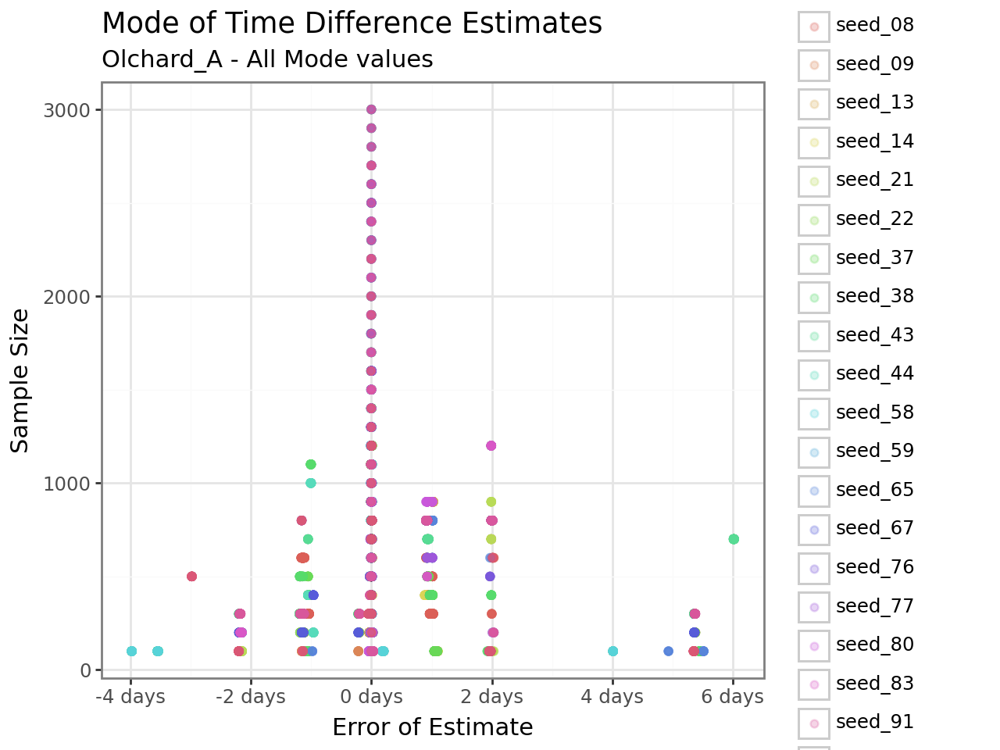

C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:606: PlotnineWarning: Saving 6.4 x 4.8 in image.
C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:607: PlotnineWarning: Filename: olchard_A_all_results_all_mode.png


In [79]:
p = ggplot(olchard_A_all_results_df, aes("error_estimate", "sample_size", colour = "set_seed"))  + geom_point(alpha = 0.25) + labs(title= "Mode of Time Difference Estimates", subtitle="Olchard_A - All Mode values", x = "Error of Estimate",  y = "Sample Size", colour = "Simulation seed") + theme_bw()
p.show()
p.save(filename = 'olchard_A_all_results_all_mode.png', dpi = 300)

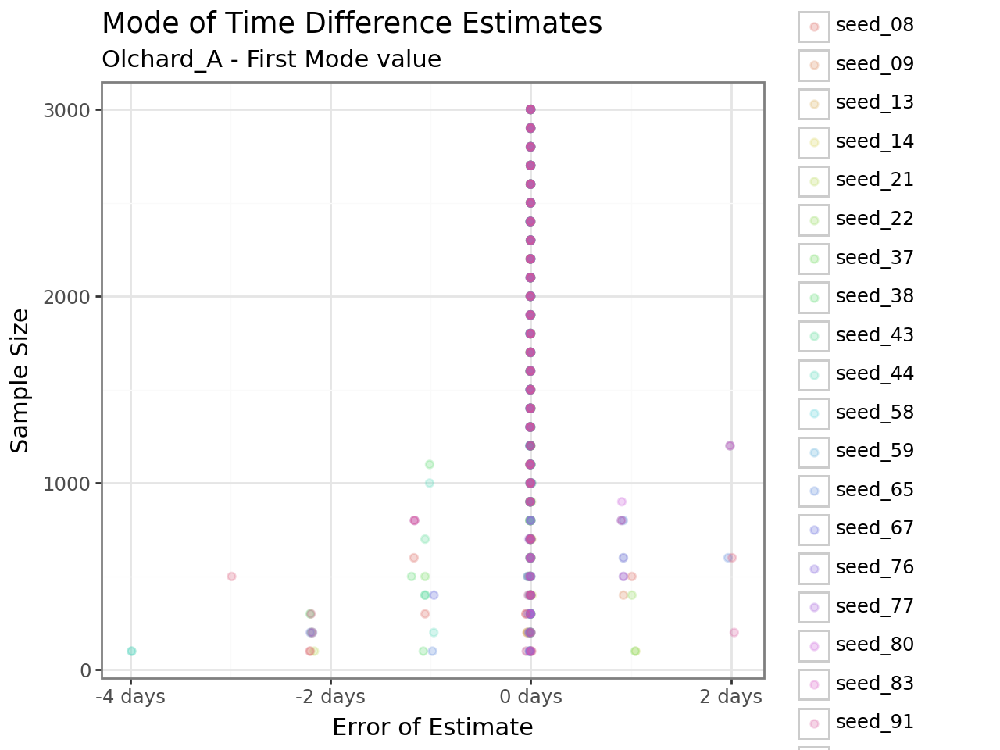

C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:606: PlotnineWarning: Saving 6.4 x 4.8 in image.
C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:607: PlotnineWarning: Filename: olchard_A_all_results_first_mode.png


In [80]:
p = ggplot(olchard_A_first_results_df, aes("error_estimate", "sample_size", colour = "set_seed")) + geom_point(alpha = 0.25) + labs(title= "Mode of Time Difference Estimates", subtitle="Olchard_A - First Mode value", x = "Error of Estimate",  y = "Sample Size", colour = "Simulation seed") + theme_bw()
p.show()
p.save(filename = 'olchard_A_all_results_first_mode.png', dpi = 300)

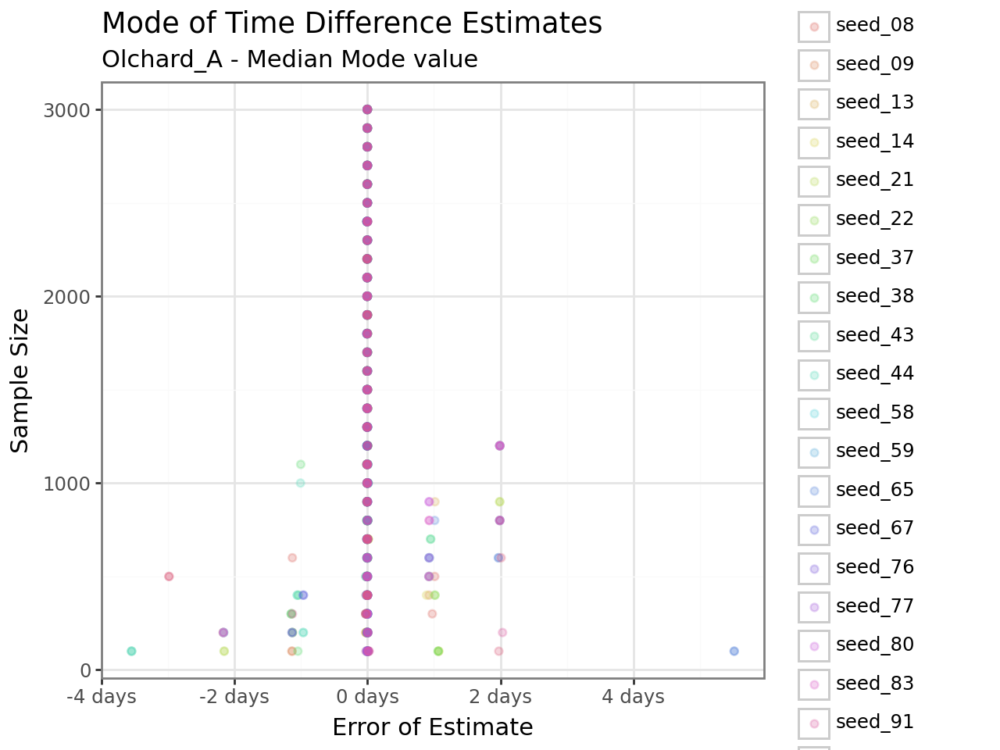

C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:606: PlotnineWarning: Saving 6.4 x 4.8 in image.
C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:607: PlotnineWarning: Filename: olchard_A_all_results_median_mode.png


In [81]:
p = ggplot(olchard_A_median_results_df, aes("error_estimate", "sample_size", colour = "set_seed"))  + geom_point(alpha = 0.25) + labs(title= "Mode of Time Difference Estimates", subtitle="Olchard_A - Median Mode value", x = "Error of Estimate",  y = "Sample Size", colour = "Simulation seed") + theme_bw()
p.show()
p.save(filename = 'olchard_A_all_results_median_mode.png', dpi = 300)

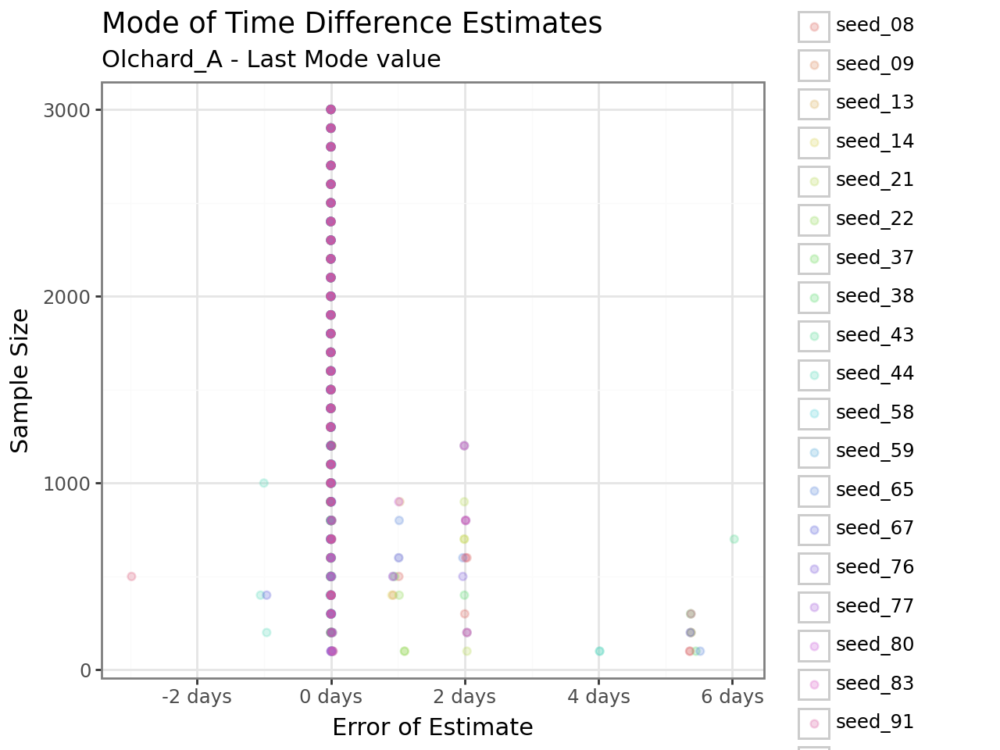

C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:606: PlotnineWarning: Saving 6.4 x 4.8 in image.
C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:607: PlotnineWarning: Filename: olchard_A_all_results_last_mode.png


In [82]:
p = ggplot(olchard_A_last_results_df, aes("error_estimate", "sample_size", colour = "set_seed"))  + geom_point(alpha = 0.25) + labs(title= "Mode of Time Difference Estimates", subtitle="Olchard_A - Last Mode value", x = "Error of Estimate",  y = "Sample Size", colour = "Simulation seed") + theme_bw()
p.show()
p.save(filename = 'olchard_A_all_results_last_mode.png', dpi = 300)

In [ ]:
#Create blank lists for results
all_results_list = []
first_results_list = []
median_results_list = []
last_results_list = []

for outer_key, inner_dict in dataframes.items():
    if re.match(re.compile(r'^olchard_A.*$'), outer_key):
        print(outer_key, type(inner_dict))
        seed_value = outer_key[10:17]
        print(seed_value)
        
        # Iterate over the inner dictionary
        for inner_key, df in inner_dict.items():
            if re.match(re.compile(r'.*_low_kl_div_error'), inner_key):
                print(inner_key, type(df))
                
                for final_key, final_df in df.items():
                    print(final_key)
                    ss_value = final_key[12:]
                    print(ss_value)
                    
                    if final_df.empty:
                        print('DataFrame is empty!')

                    else:
                        #create a copy of the dataframe before changing
                        new_df = final_df
                    
                        #create new columns of the sample size and the set seed of simnulation
                        new_df['sample_size'] = ss_value
                        new_df['set_seed'] = seed_value
                    
                        #calculate the mode values
                        first_mode = new_df.iloc[[0]]
                        last_mode = new_df.iloc[[-1]]
                        #median of the mode
                        new_df['median_diff'] = (new_df['time_diff'] - new_df['time_diff'].median()).abs()
                        median_mode = new_df.loc[new_df['median_diff'] == new_df['median_diff'].min()]
                    
                        #Add to dataframes
                        all_results_list.append(new_df)
                        first_results_list.append(first_mode)
                        median_results_list.append(median_mode)
                        last_results_list.append(last_mode)

olchard_A_all_results_df = pd.concat(all_results_list, axis = 0, ignore_index = True)
olchard_A_all_results_df[['sample_size']] = olchard_A_all_results_df[['sample_size']].apply(pd.to_numeric)

olchard_A_first_results_df = pd.concat(first_results_list, axis = 0, ignore_index = True)
olchard_A_first_results_df[['sample_size']] = olchard_A_first_results_df[['sample_size']].apply(pd.to_numeric)

olchard_A_median_results_df = pd.concat(median_results_list, axis = 0, ignore_index = True)
olchard_A_median_results_df[['sample_size']] = olchard_A_median_results_df[['sample_size']].apply(pd.to_numeric)

olchard_A_last_results_df = pd.concat(last_results_list, axis = 0, ignore_index = True)
olchard_A_last_results_df[['sample_size']] = olchard_A_last_results_df[['sample_size']].apply(pd.to_numeric)

In [84]:
olchard_A_low_KL_div_sim_results = {
    "all_mode_results" : olchard_A_all_results_df,
    "first_mode_results" : olchard_A_first_results_df,
    "median_mode_results" : olchard_A_median_results_df,
    "last_mode_results" : olchard_A_last_results_df
}

In [85]:
#Remove NA values
olchard_A_all_results_df.dropna(subset = ['error_estimate'], inplace = True)
olchard_A_first_results_df.dropna(subset = ['error_estimate'], inplace = True)
olchard_A_median_results_df.dropna(subset = ['error_estimate'], inplace = True)
olchard_A_last_results_df.dropna(subset = ['error_estimate'], inplace = True)

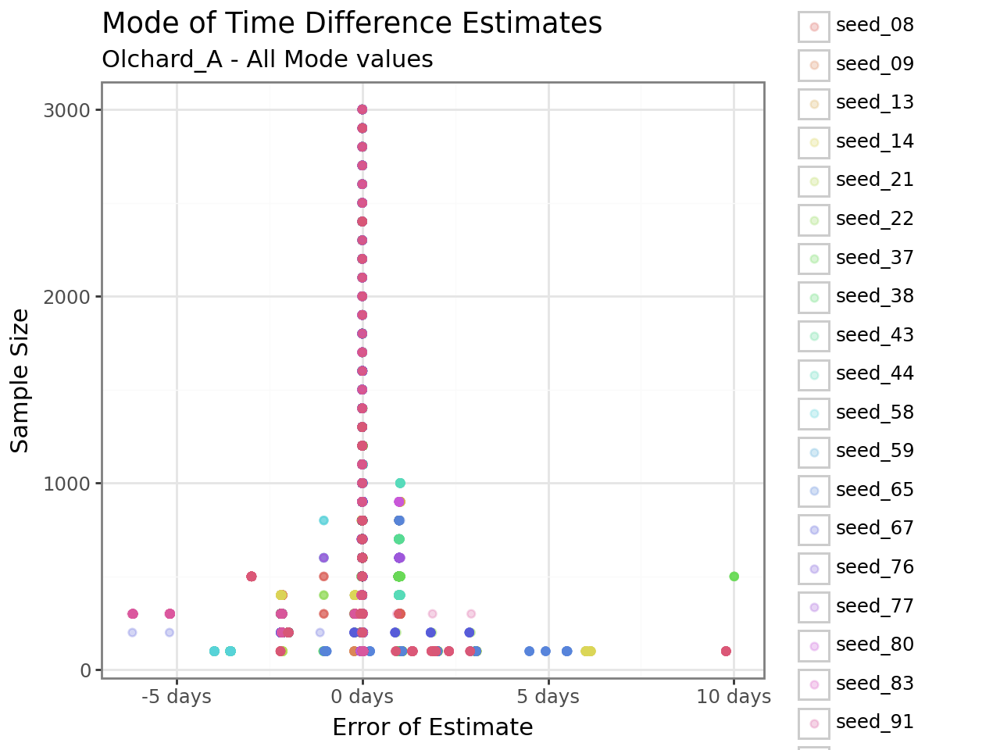

C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:606: PlotnineWarning: Saving 6.4 x 4.8 in image.
C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:607: PlotnineWarning: Filename: olchard_A_low_results_all_mode.png


In [86]:
p = ggplot(olchard_A_all_results_df, aes("error_estimate", "sample_size", colour = "set_seed"))  + geom_point(alpha = 0.25) + labs(title= "Mode of Time Difference Estimates", subtitle="Olchard_A - All Mode values", x = "Error of Estimate",  y = "Sample Size", colour = "Simulation seed") + theme_bw()
p.show()
p.save(filename = 'olchard_A_low_results_all_mode.png', dpi = 300)

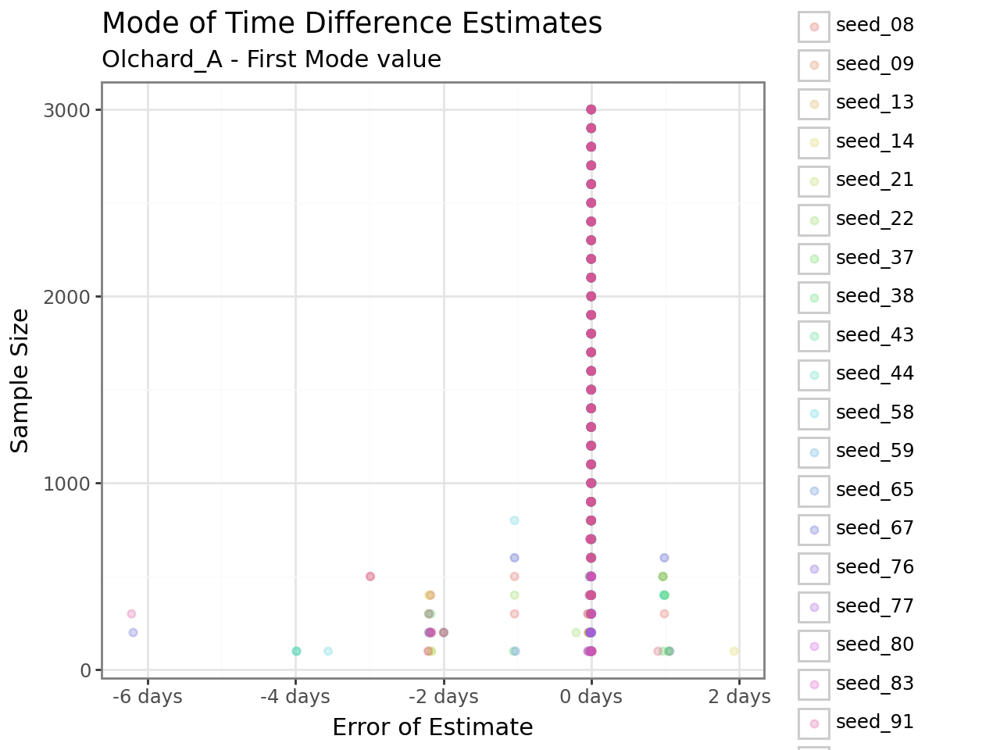

C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:606: PlotnineWarning: Saving 6.4 x 4.8 in image.
C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:607: PlotnineWarning: Filename: olchard_A_low_results_first_mode.png


In [87]:
p = ggplot(olchard_A_first_results_df, aes("error_estimate", "sample_size", colour = "set_seed")) + geom_point(alpha = 0.25) + labs(title= "Mode of Time Difference Estimates", subtitle="Olchard_A - First Mode value", x = "Error of Estimate",  y = "Sample Size", colour = "Simulation seed") + theme_bw()
p.show()
p.save(filename = 'olchard_A_low_results_first_mode.png', dpi = 300)

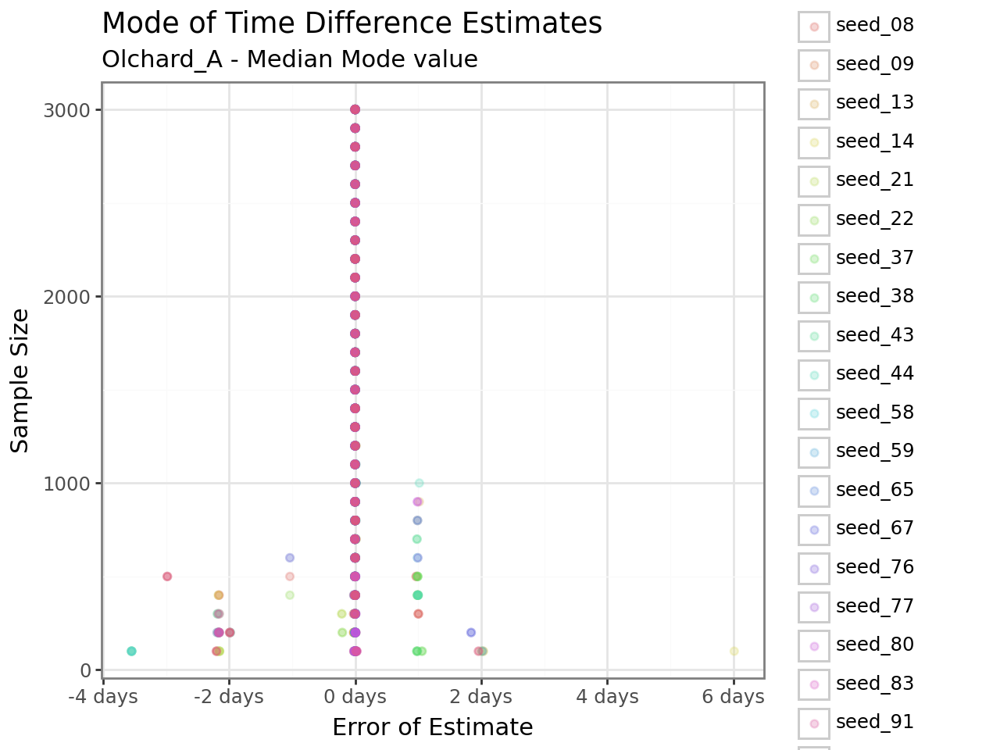

C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:606: PlotnineWarning: Saving 6.4 x 4.8 in image.
C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:607: PlotnineWarning: Filename: olchard_A_low_results_median_mode.png


In [88]:
p = ggplot(olchard_A_median_results_df, aes("error_estimate", "sample_size", colour = "set_seed"))  + geom_point(alpha = 0.25) + labs(title= "Mode of Time Difference Estimates", subtitle="Olchard_A - Median Mode value", x = "Error of Estimate",  y = "Sample Size", colour = "Simulation seed") + theme_bw()
p.show()
p.save(filename = 'olchard_A_low_results_median_mode.png', dpi = 300)

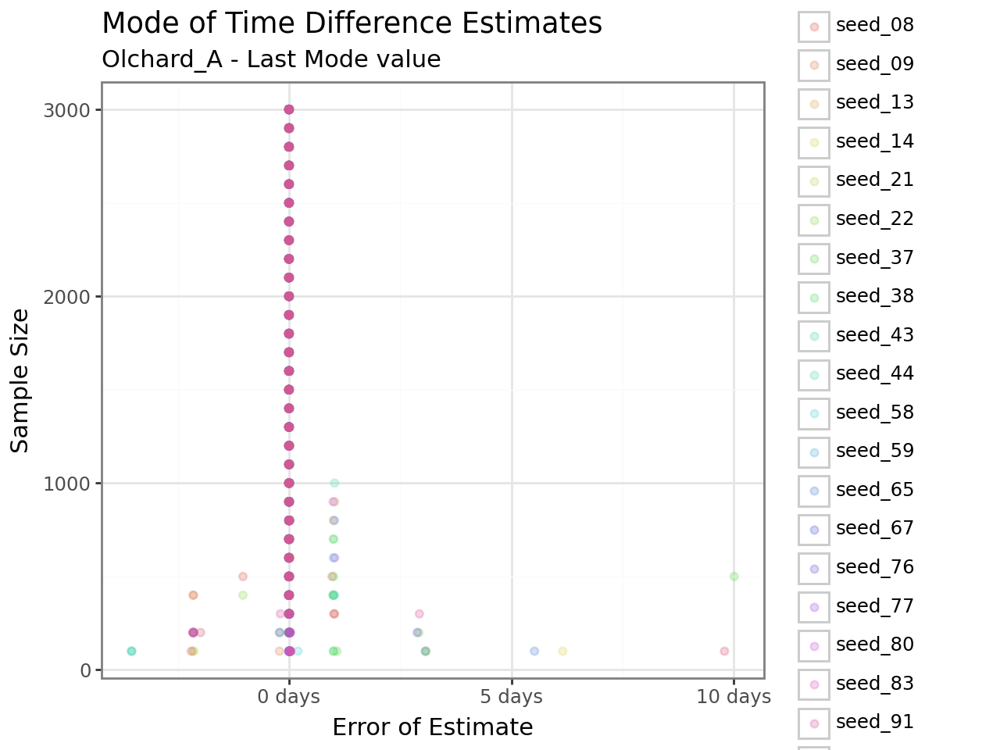

C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:606: PlotnineWarning: Saving 6.4 x 4.8 in image.
C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:607: PlotnineWarning: Filename: olchard_A_low_results_last_mode.png


In [89]:
p = ggplot(olchard_A_last_results_df, aes("error_estimate", "sample_size", colour = "set_seed"))  + geom_point(alpha = 0.25) + labs(title= "Mode of Time Difference Estimates", subtitle="Olchard_A - Last Mode value", x = "Error of Estimate",  y = "Sample Size", colour = "Simulation seed") + theme_bw()
p.show()
p.save(filename = 'olchard_A_low_results_last_mode.png', dpi = 300)

In [ ]:
#Create blank lists for results
all_results_list = []
first_results_list = []
median_results_list = []
last_results_list = []

for outer_key, inner_dict in dataframes.items():
    if re.match(re.compile(r'^olchard_A.*$'), outer_key):
        print(outer_key, type(inner_dict))
        seed_value = outer_key[10:17]
        print(seed_value)
        
        # Iterate over the inner dictionary
        for inner_key, df in inner_dict.items():
            if re.match(re.compile(r'.*_very_low_kl_div_error'), inner_key):
                print(inner_key, type(df))
                
                for final_key, final_df in df.items():
                    print(final_key)
                    ss_value = final_key[12:]
                    print(ss_value)
                    
                    if final_df.empty:
                        print('DataFrame is empty!')

                    else:
                        #create a copy of the dataframe before changing
                        new_df = final_df
                    
                        #create new columns of the sample size and the set seed of simnulation
                        new_df['sample_size'] = ss_value
                        new_df['set_seed'] = seed_value
                    
                        #calculate the mode values
                        first_mode = new_df.iloc[[0]]
                        last_mode = new_df.iloc[[-1]]
                        #median of the mode
                        new_df['median_diff'] = (new_df['time_diff'] - new_df['time_diff'].median()).abs()
                        median_mode = new_df.loc[new_df['median_diff'] == new_df['median_diff'].min()]
                    
                        #Add to dataframes
                        all_results_list.append(new_df)
                        first_results_list.append(first_mode)
                        median_results_list.append(median_mode)
                        last_results_list.append(last_mode)

olchard_A_all_results_df = pd.concat(all_results_list, axis = 0, ignore_index = True)
olchard_A_all_results_df[['sample_size']] = olchard_A_all_results_df[['sample_size']].apply(pd.to_numeric)

olchard_A_first_results_df = pd.concat(first_results_list, axis = 0, ignore_index = True)
olchard_A_first_results_df[['sample_size']] = olchard_A_first_results_df[['sample_size']].apply(pd.to_numeric)

olchard_A_median_results_df = pd.concat(median_results_list, axis = 0, ignore_index = True)
olchard_A_median_results_df[['sample_size']] = olchard_A_median_results_df[['sample_size']].apply(pd.to_numeric)

olchard_A_last_results_df = pd.concat(last_results_list, axis = 0, ignore_index = True)
olchard_A_last_results_df[['sample_size']] = olchard_A_last_results_df[['sample_size']].apply(pd.to_numeric)

In [91]:
olchard_A_very_low_KL_div_sim_results = {
    "all_mode_results" : olchard_A_all_results_df,
    "first_mode_results" : olchard_A_first_results_df,
    "median_mode_results" : olchard_A_median_results_df,
    "last_mode_results" : olchard_A_last_results_df
}

In [92]:
#Remove NA values
olchard_A_all_results_df.dropna(subset = ['error_estimate'], inplace = True)
olchard_A_first_results_df.dropna(subset = ['error_estimate'], inplace = True)
olchard_A_median_results_df.dropna(subset = ['error_estimate'], inplace = True)
olchard_A_last_results_df.dropna(subset = ['error_estimate'], inplace = True)

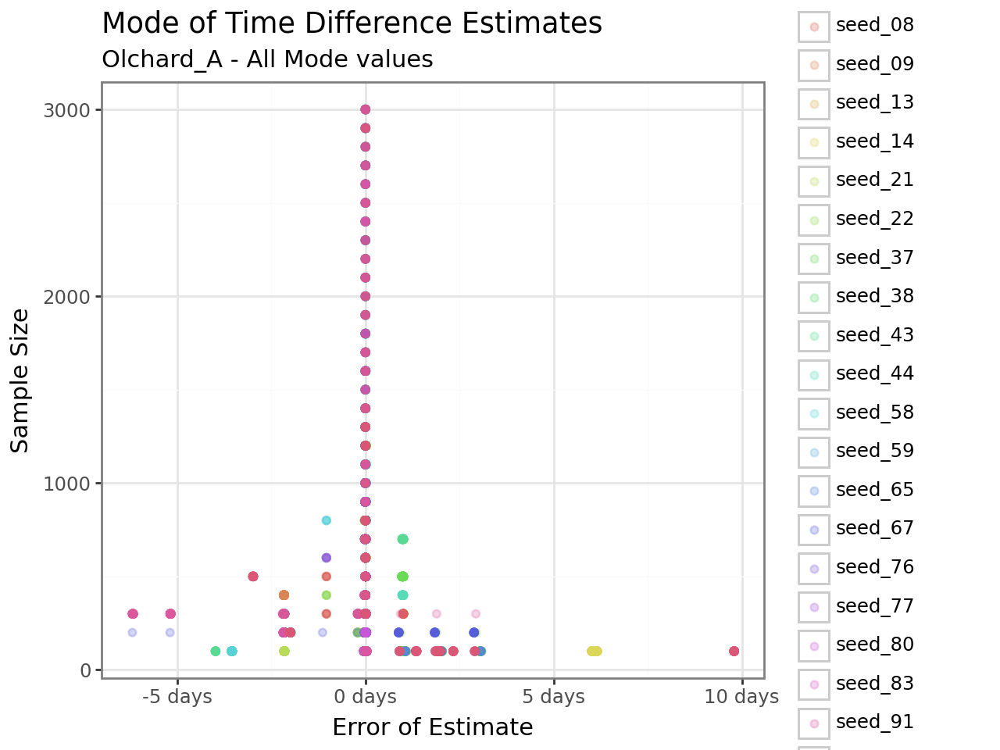

C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:606: PlotnineWarning: Saving 6.4 x 4.8 in image.
C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:607: PlotnineWarning: Filename: olchard_A_very_low_results_all_mode.png


In [93]:
p = ggplot(olchard_A_all_results_df, aes("error_estimate", "sample_size", colour = "set_seed"))  + geom_point(alpha = 0.25) + labs(title= "Mode of Time Difference Estimates", subtitle="Olchard_A - All Mode values", x = "Error of Estimate",  y = "Sample Size", colour = "Simulation seed") + theme_bw()
p.show()
p.save(filename = 'olchard_A_very_low_results_all_mode.png', dpi = 300)

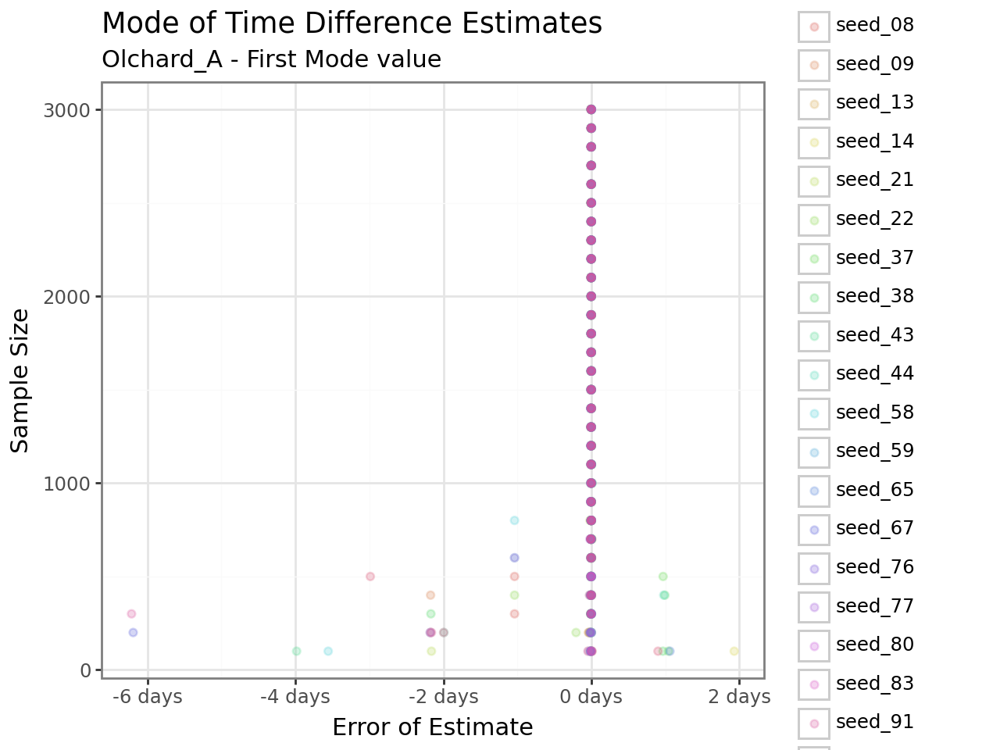

C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:606: PlotnineWarning: Saving 6.4 x 4.8 in image.
C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:607: PlotnineWarning: Filename: olchard_A_very_low_results_first_mode.png


In [94]:
p = ggplot(olchard_A_first_results_df, aes("error_estimate", "sample_size", colour = "set_seed")) + geom_point(alpha = 0.25) + labs(title= "Mode of Time Difference Estimates", subtitle="Olchard_A - First Mode value", x = "Error of Estimate",  y = "Sample Size", colour = "Simulation seed") + theme_bw()
p.show()
p.save(filename = 'olchard_A_very_low_results_first_mode.png', dpi = 300)

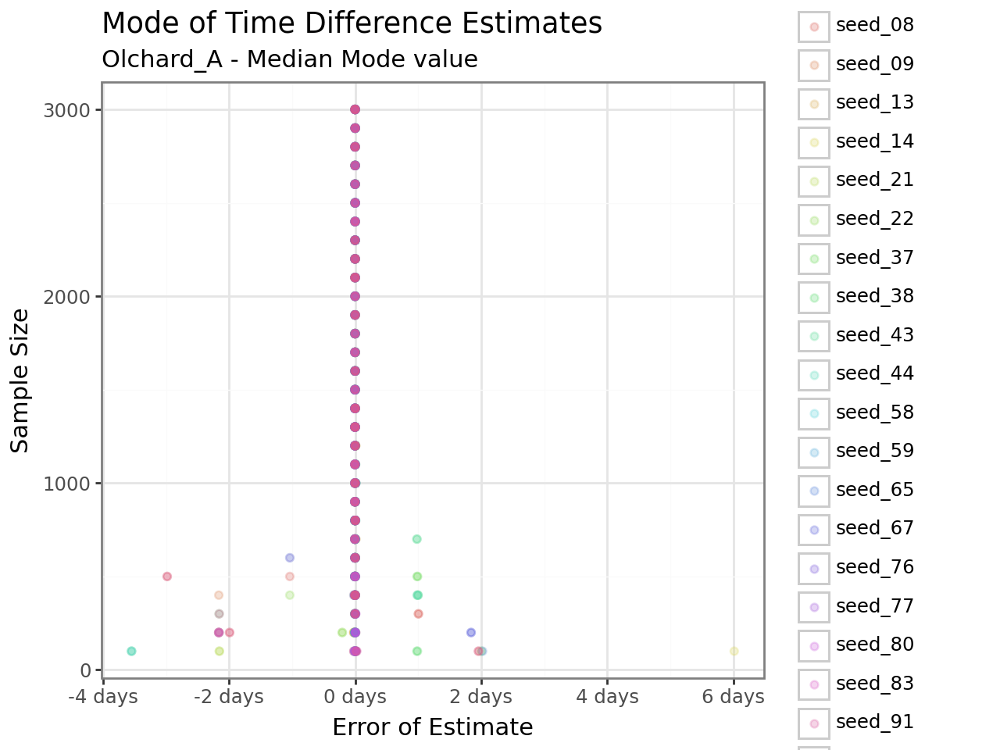

C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:606: PlotnineWarning: Saving 6.4 x 4.8 in image.
C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:607: PlotnineWarning: Filename: olchard_A_very_low_results_median_mode.png


In [95]:
p = ggplot(olchard_A_median_results_df, aes("error_estimate", "sample_size", colour = "set_seed"))  + geom_point(alpha = 0.25) + labs(title= "Mode of Time Difference Estimates", subtitle="Olchard_A - Median Mode value", x = "Error of Estimate",  y = "Sample Size", colour = "Simulation seed") + theme_bw()
p.show()
p.save(filename = 'olchard_A_very_low_results_median_mode.png', dpi = 300)

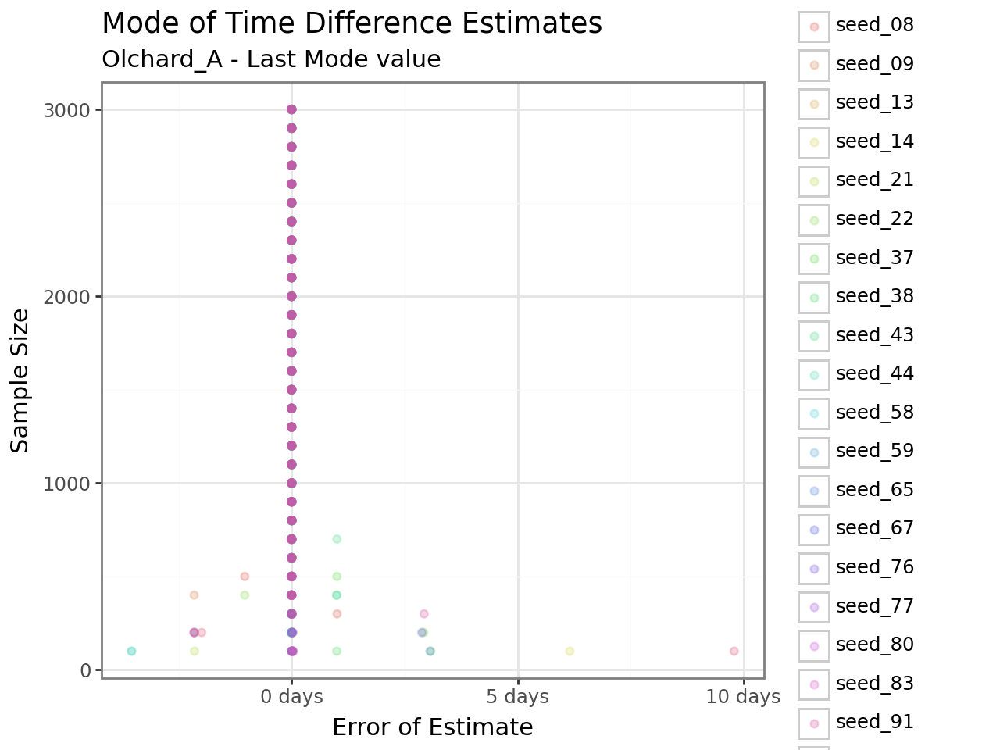

C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:606: PlotnineWarning: Saving 6.4 x 4.8 in image.
C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:607: PlotnineWarning: Filename: olchard_A_very_low_results_last_mode.png


In [96]:
p = ggplot(olchard_A_last_results_df, aes("error_estimate", "sample_size", colour = "set_seed"))  + geom_point(alpha = 0.25) + labs(title= "Mode of Time Difference Estimates", subtitle="Olchard_A - Last Mode value", x = "Error of Estimate",  y = "Sample Size", colour = "Simulation seed") + theme_bw()
p.show()
p.save(filename = 'olchard_A_very_low_results_last_mode.png', dpi = 300)

In [ ]:
#Create blank lists for results
all_results_list = []
first_results_list = []
median_results_list = []
last_results_list = []

for outer_key, inner_dict in dataframes.items():
    if re.match(re.compile(r'^olchard_A.*$'), outer_key):
        print(outer_key, type(inner_dict))
        seed_value = outer_key[10:17]
        print(seed_value)
        
        # Iterate over the inner dictionary
        for inner_key, df in inner_dict.items():
            if re.match(re.compile(r'.*_zero_kl_div_error'), inner_key):
                print(inner_key, type(df))
                
                for final_key, final_df in df.items():
                    print(final_key)
                    ss_value = final_key[12:]
                    print(ss_value)
                    
                    if final_df.empty:
                        print('DataFrame is empty!')

                    else:
                        #create a copy of the dataframe before changing
                        new_df = final_df
                    
                        #create new columns of the sample size and the set seed of simnulation
                        new_df['sample_size'] = ss_value
                        new_df['set_seed'] = seed_value
                    
                        #calculate the mode values
                        first_mode = new_df.iloc[[0]]
                        last_mode = new_df.iloc[[-1]]
                        #median of the mode
                        new_df['median_diff'] = (new_df['time_diff'] - new_df['time_diff'].median()).abs()
                        median_mode = new_df.loc[new_df['median_diff'] == new_df['median_diff'].min()]
                    
                        #Add to dataframes
                        all_results_list.append(new_df)
                        first_results_list.append(first_mode)
                        median_results_list.append(median_mode)
                        last_results_list.append(last_mode)

olchard_A_all_results_df = pd.concat(all_results_list, axis = 0, ignore_index = True)
olchard_A_all_results_df[['sample_size']] = olchard_A_all_results_df[['sample_size']].apply(pd.to_numeric)

olchard_A_first_results_df = pd.concat(first_results_list, axis = 0, ignore_index = True)
olchard_A_first_results_df[['sample_size']] = olchard_A_first_results_df[['sample_size']].apply(pd.to_numeric)

olchard_A_median_results_df = pd.concat(median_results_list, axis = 0, ignore_index = True)
olchard_A_median_results_df[['sample_size']] = olchard_A_median_results_df[['sample_size']].apply(pd.to_numeric)

olchard_A_last_results_df = pd.concat(last_results_list, axis = 0, ignore_index = True)
olchard_A_last_results_df[['sample_size']] = olchard_A_last_results_df[['sample_size']].apply(pd.to_numeric)

In [98]:
#Put results into dictionary
olchard_A_zero_KL_div_sim_results = {
    "all_mode_results" : olchard_A_all_results_df,
    "first_mode_results" : olchard_A_first_results_df,
    "median_mode_results" : olchard_A_median_results_df,
    "last_mode_results" : olchard_A_last_results_df
}

In [99]:
#Remove NA values
olchard_A_all_results_df.dropna(subset = ['error_estimate'], inplace = True)
olchard_A_first_results_df.dropna(subset = ['error_estimate'], inplace = True)
olchard_A_median_results_df.dropna(subset = ['error_estimate'], inplace = True)
olchard_A_last_results_df.dropna(subset = ['error_estimate'], inplace = True)

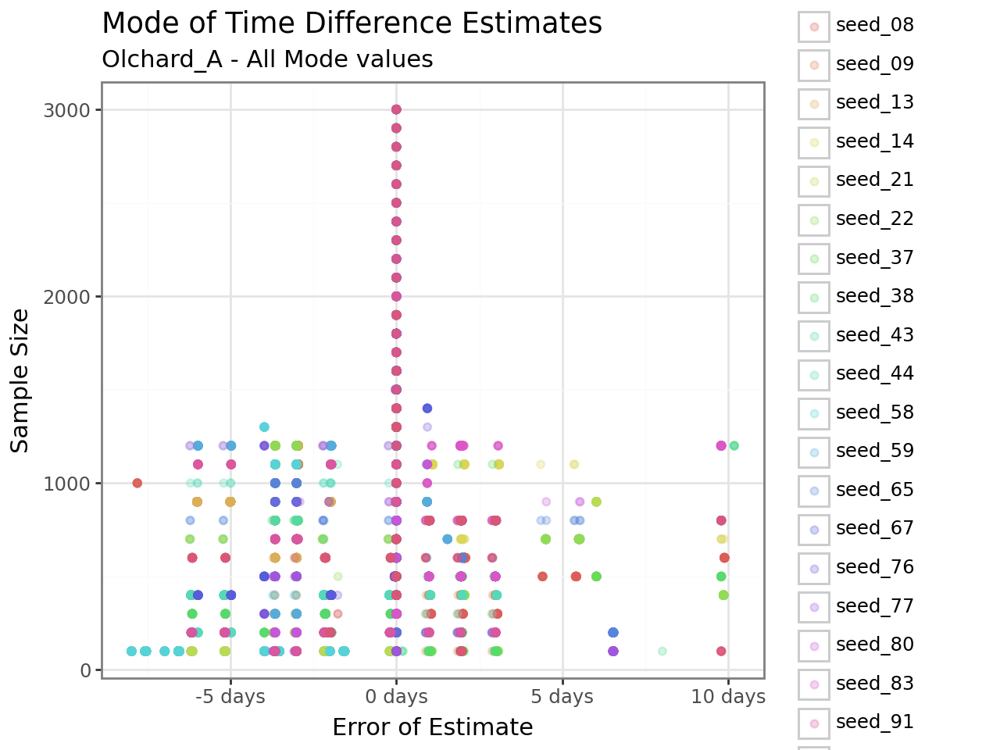

C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:606: PlotnineWarning: Saving 6.4 x 4.8 in image.
C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:607: PlotnineWarning: Filename: olchard_A_zero_results_all_mode.png


In [100]:
p = ggplot(olchard_A_all_results_df, aes("error_estimate", "sample_size", colour = "set_seed"))  + geom_point(alpha = 0.25) + labs(title= "Mode of Time Difference Estimates", subtitle="Olchard_A - All Mode values", x = "Error of Estimate",  y = "Sample Size", colour = "Simulation seed") + theme_bw()
p.show()
p.save(filename = 'olchard_A_zero_results_all_mode.png', dpi = 300)

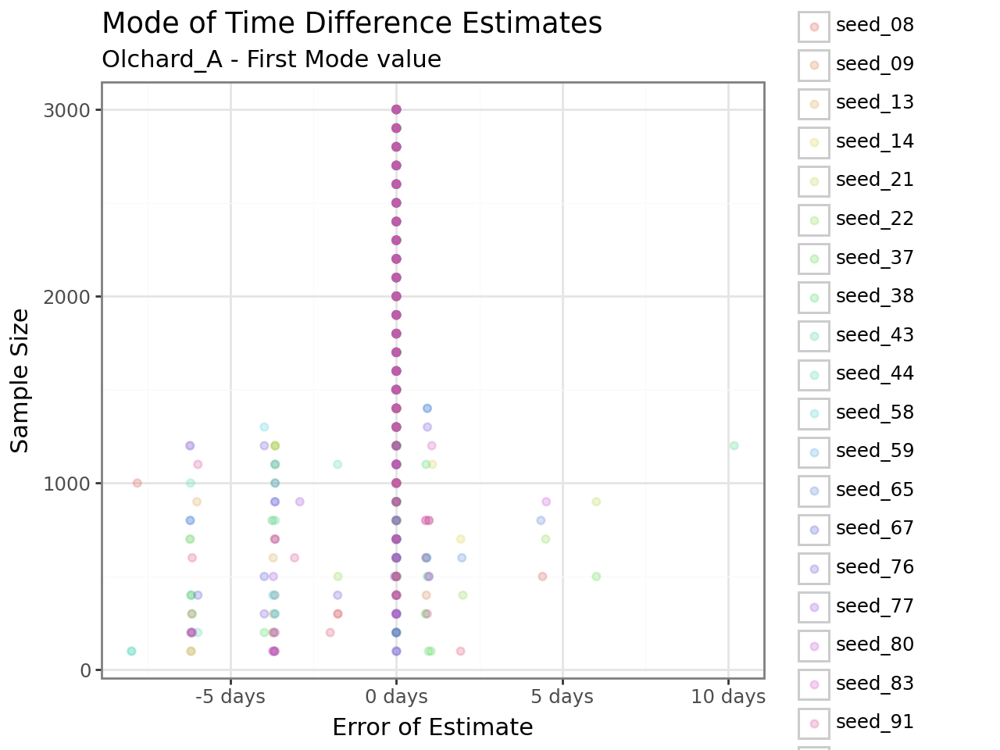

C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:606: PlotnineWarning: Saving 6.4 x 4.8 in image.
C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:607: PlotnineWarning: Filename: olchard_A_zero_results_first_mode.png


In [101]:
p = ggplot(olchard_A_first_results_df, aes("error_estimate", "sample_size", colour = "set_seed")) + geom_point(alpha = 0.25) + labs(title= "Mode of Time Difference Estimates", subtitle="Olchard_A - First Mode value", x = "Error of Estimate",  y = "Sample Size", colour = "Simulation seed") + theme_bw()
p.show()
p.save(filename = 'olchard_A_zero_results_first_mode.png', dpi = 300)

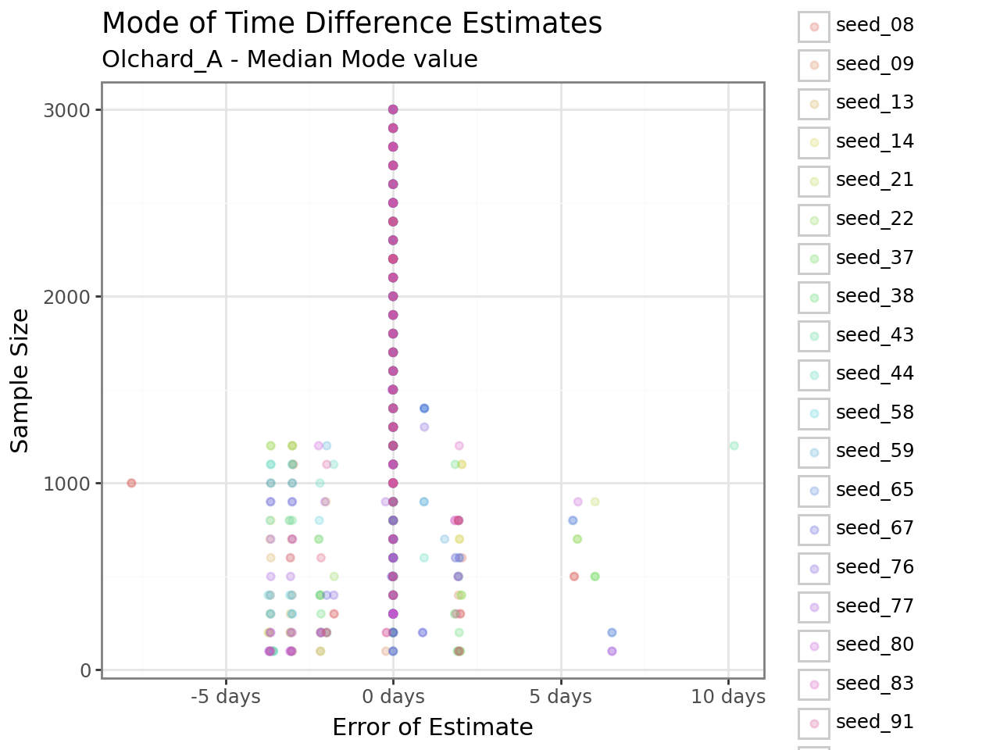

C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:606: PlotnineWarning: Saving 6.4 x 4.8 in image.
C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:607: PlotnineWarning: Filename: olchard_A_zero_results_median_mode.png


In [102]:
p = ggplot(olchard_A_median_results_df, aes("error_estimate", "sample_size", colour = "set_seed"))  + geom_point(alpha = 0.25) + labs(title= "Mode of Time Difference Estimates", subtitle="Olchard_A - Median Mode value", x = "Error of Estimate",  y = "Sample Size", colour = "Simulation seed") + theme_bw()
p.show()
p.save(filename = 'olchard_A_zero_results_median_mode.png', dpi = 300)

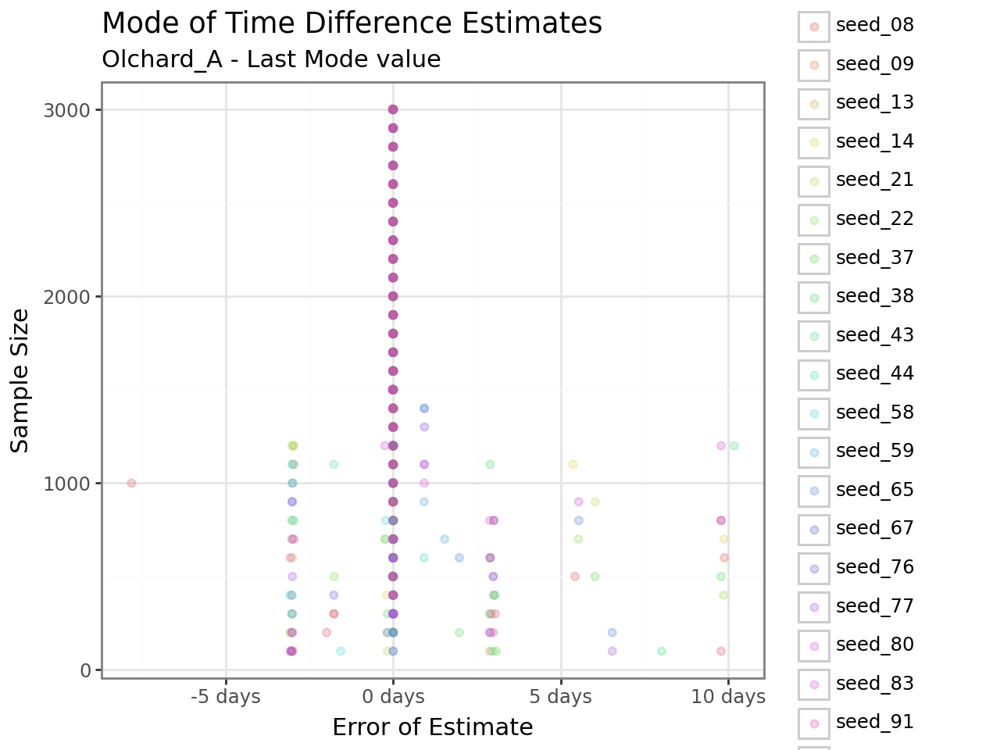

C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:606: PlotnineWarning: Saving 6.4 x 4.8 in image.
C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:607: PlotnineWarning: Filename: olchard_A_zero_results_last_mode.png


In [103]:
p = ggplot(olchard_A_last_results_df, aes("error_estimate", "sample_size", colour = "set_seed"))  + geom_point(alpha = 0.25) + labs(title= "Mode of Time Difference Estimates", subtitle="Olchard_A - Last Mode value", x = "Error of Estimate",  y = "Sample Size", colour = "Simulation seed") + theme_bw()
p.show()
p.save(filename = 'olchard_A_zero_results_last_mode.png', dpi = 300)

In [104]:
#Create dictionary of olchard_A results
olchard_A_sim_results = {
    "all_results" : olchard_A_all_KL_div_sim_results,
    "low_results" : olchard_A_low_KL_div_sim_results,
    "very_low_results" : olchard_A_very_low_KL_div_sim_results,
    "zero_results" : olchard_A_zero_KL_div_sim_results
}

In [ ]:
with open(f'{output_dir}/olchard_A_sim_results.pickle', 'wb') as handle:
        pickle.dump(olchard_A_sim_results, handle, protocol=pickle.HIGHEST_PROTOCOL)

## Data processing Olchard C results

In [ ]:
#Create blank lists for results
all_results_list = []
first_results_list = []
median_results_list = []
last_results_list = []

for outer_key, inner_dict in dataframes.items():
    if re.match(re.compile(r'^olchard_C.*$'), outer_key):
        print(outer_key, type(inner_dict))
        seed_value = outer_key[10:17]
        print(seed_value)
        
        # Iterate over the inner dictionary
        for inner_key, df in inner_dict.items():
            if re.match(re.compile(r'.*_all_kl_div_error'), inner_key):
                print(inner_key, type(df))
                
                for final_key, final_df in df.items():
                    print(final_key)
                    ss_value = final_key[12:]
                    print(ss_value)
                    
                    if final_df.empty:
                        print('DataFrame is empty!')

                    else:
                        #create a copy of the dataframe before changing
                        new_df = final_df
                    
                        #create new columns of the sample size and the set seed of simnulation
                        new_df['sample_size'] = ss_value
                        new_df['set_seed'] = seed_value
                    
                        #calculate the mode values
                        first_mode = new_df.iloc[[0]]
                        last_mode = new_df.iloc[[-1]]
                        #median of the mode
                        new_df['median_diff'] = (new_df['time_diff'] - new_df['time_diff'].median()).abs()
                        median_mode = new_df.loc[new_df['median_diff'] == new_df['median_diff'].min()]
                    
                        #Add to dataframes
                        all_results_list.append(new_df)
                        first_results_list.append(first_mode)
                        median_results_list.append(median_mode)
                        last_results_list.append(last_mode)

olchard_C_all_results_df = pd.concat(all_results_list, axis = 0, ignore_index = True)
olchard_C_all_results_df[['sample_size']] = olchard_C_all_results_df[['sample_size']].apply(pd.to_numeric)

olchard_C_first_results_df = pd.concat(first_results_list, axis = 0, ignore_index = True)
olchard_C_first_results_df[['sample_size']] = olchard_C_first_results_df[['sample_size']].apply(pd.to_numeric)

olchard_C_median_results_df = pd.concat(median_results_list, axis = 0, ignore_index = True)
olchard_C_median_results_df[['sample_size']] = olchard_C_median_results_df[['sample_size']].apply(pd.to_numeric)

olchard_C_last_results_df = pd.concat(last_results_list, axis = 0, ignore_index = True)
olchard_C_last_results_df[['sample_size']] = olchard_C_last_results_df[['sample_size']].apply(pd.to_numeric)

In [108]:
olchard_C_all_KL_div_sim_results = {
    "all_mode_results" : olchard_C_all_results_df,
    "first_mode_results" : olchard_C_first_results_df,
    "median_mode_results" : olchard_C_median_results_df,
    "last_mode_results" : olchard_C_last_results_df
}

In [109]:
#Remove NA values
olchard_C_all_results_df.dropna(subset = ['error_estimate'], inplace = True)
olchard_C_first_results_df.dropna(subset = ['error_estimate'], inplace = True)
olchard_C_median_results_df.dropna(subset = ['error_estimate'], inplace = True)
olchard_C_last_results_df.dropna(subset = ['error_estimate'], inplace = True)

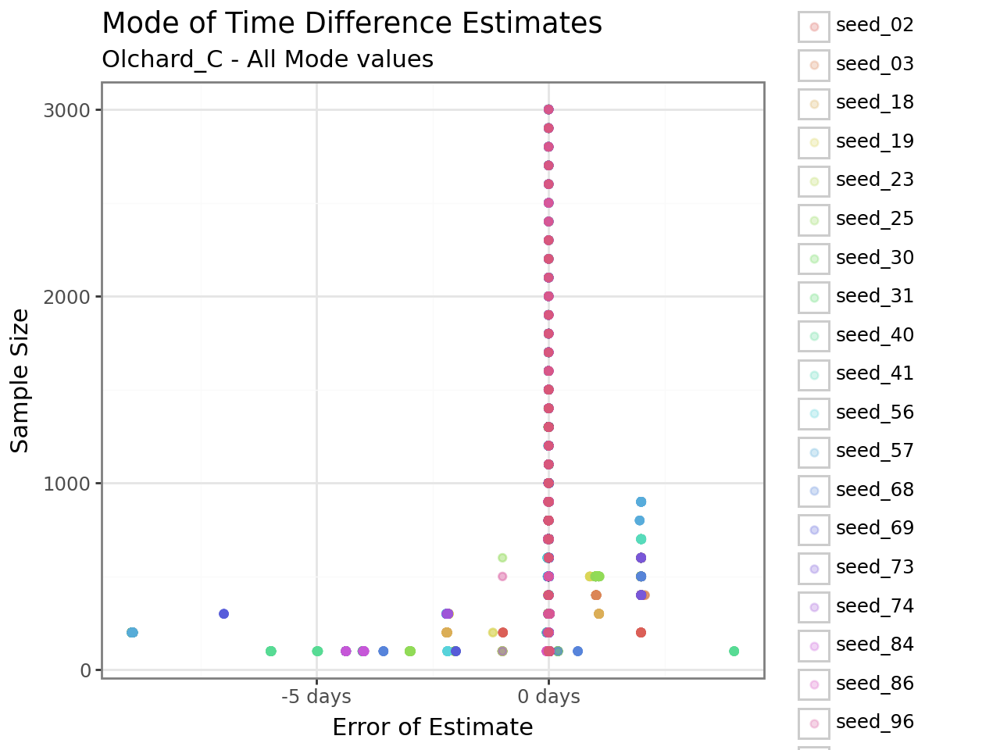

C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:606: PlotnineWarning: Saving 6.4 x 4.8 in image.
C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:607: PlotnineWarning: Filename: olchard_C_all_results_all_mode.png


In [110]:
p = ggplot(olchard_C_all_results_df, aes("error_estimate", "sample_size", colour = "set_seed"))  + geom_point(alpha = 0.25) + labs(title= "Mode of Time Difference Estimates", subtitle="Olchard_C - All Mode values", x = "Error of Estimate",  y = "Sample Size", colour = "Simulation seed") + theme_bw()
p.show()
p.save(filename = 'olchard_C_all_results_all_mode.png', dpi = 300)

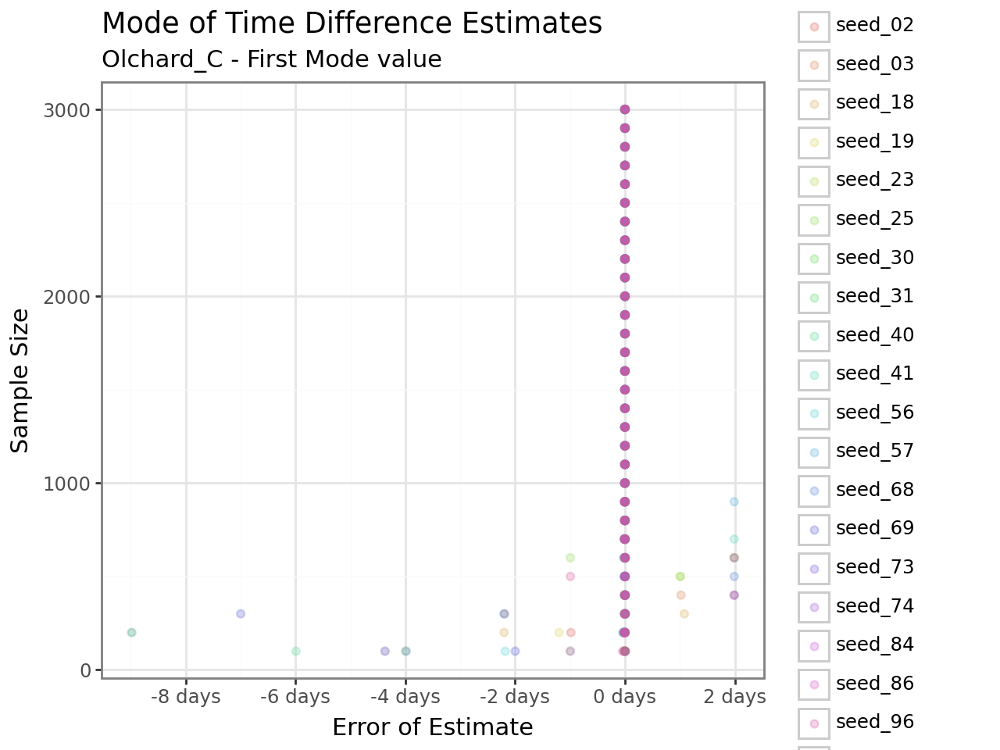

C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:606: PlotnineWarning: Saving 6.4 x 4.8 in image.
C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:607: PlotnineWarning: Filename: olchard_C_all_results_first_mode.png


In [111]:
p = ggplot(olchard_C_first_results_df, aes("error_estimate", "sample_size", colour = "set_seed")) + geom_point(alpha = 0.25) + labs(title= "Mode of Time Difference Estimates", subtitle="Olchard_C - First Mode value", x = "Error of Estimate",  y = "Sample Size", colour = "Simulation seed") + theme_bw()
p.show()
p.save(filename = 'olchard_C_all_results_first_mode.png', dpi = 300)

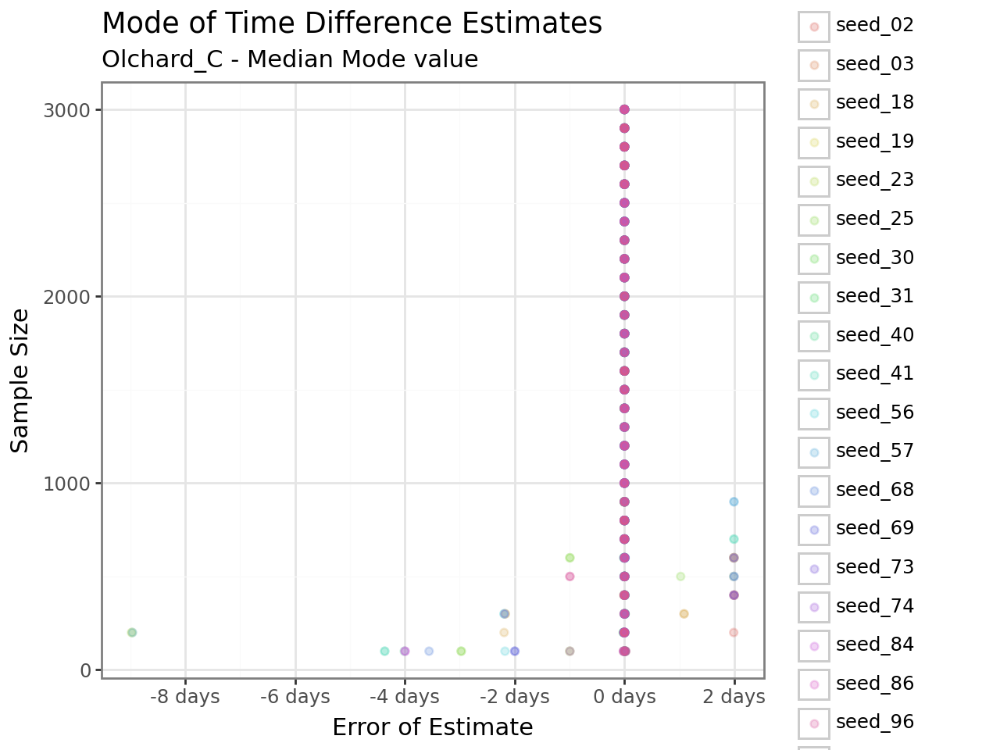

C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:606: PlotnineWarning: Saving 6.4 x 4.8 in image.
C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:607: PlotnineWarning: Filename: olchard_C_all_results_median_mode.png


In [112]:
p = ggplot(olchard_C_median_results_df, aes("error_estimate", "sample_size", colour = "set_seed"))  + geom_point(alpha = 0.25) + labs(title= "Mode of Time Difference Estimates", subtitle="Olchard_C - Median Mode value", x = "Error of Estimate",  y = "Sample Size", colour = "Simulation seed") + theme_bw()
p.show()
p.save(filename = 'olchard_C_all_results_median_mode.png', dpi = 300)

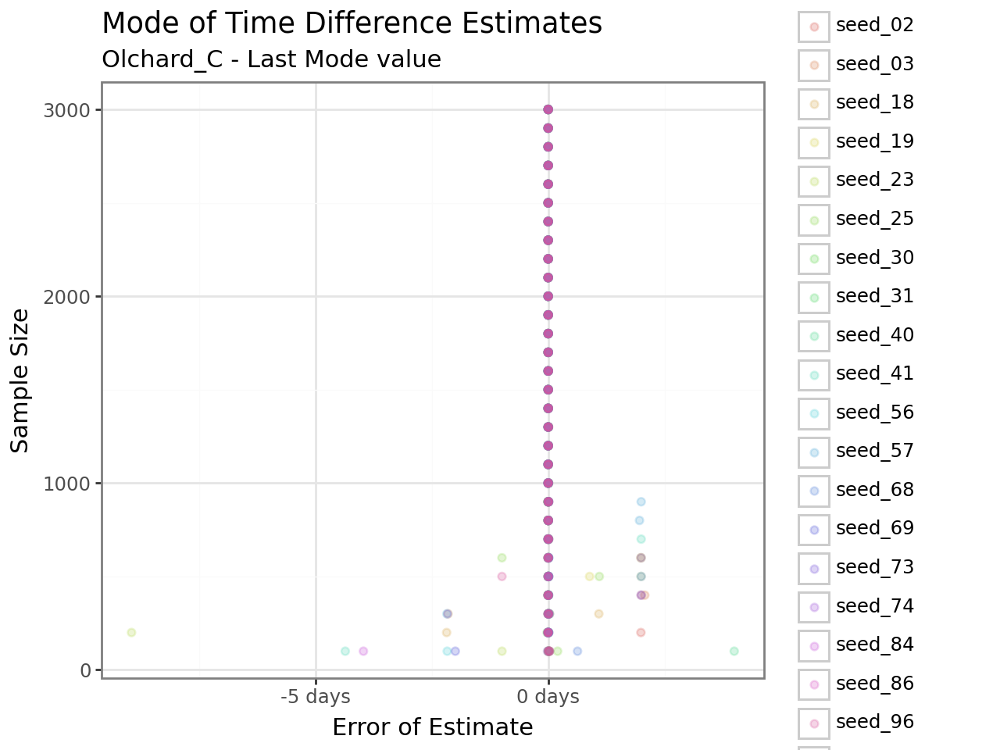

C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:606: PlotnineWarning: Saving 6.4 x 4.8 in image.
C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:607: PlotnineWarning: Filename: olchard_C_all_results_last_mode.png


In [113]:
p = ggplot(olchard_C_last_results_df, aes("error_estimate", "sample_size", colour = "set_seed"))  + geom_point(alpha = 0.25) + labs(title= "Mode of Time Difference Estimates", subtitle="Olchard_C - Last Mode value", x = "Error of Estimate",  y = "Sample Size", colour = "Simulation seed") + theme_bw()
p.show()
p.save(filename = 'olchard_C_all_results_last_mode.png', dpi = 300)

In [ ]:
#Create blank lists for results
all_results_list = []
first_results_list = []
median_results_list = []
last_results_list = []

for outer_key, inner_dict in dataframes.items():
    if re.match(re.compile(r'^olchard_C.*$'), outer_key):
        print(outer_key, type(inner_dict))
        seed_value = outer_key[10:17]
        print(seed_value)
        
        # Iterate over the inner dictionary
        for inner_key, df in inner_dict.items():
            if re.match(re.compile(r'.*_low_kl_div_error'), inner_key):
                print(inner_key, type(df))
                
                for final_key, final_df in df.items():
                    print(final_key)
                    ss_value = final_key[12:]
                    print(ss_value)
                    
                    if final_df.empty:
                        print('DataFrame is empty!')

                    else:
                        #create a copy of the dataframe before changing
                        new_df = final_df
                    
                        #create new columns of the sample size and the set seed of simnulation
                        new_df['sample_size'] = ss_value
                        new_df['set_seed'] = seed_value
                    
                        #calculate the mode values
                        first_mode = new_df.iloc[[0]]
                        last_mode = new_df.iloc[[-1]]
                        #median of the mode
                        new_df['median_diff'] = (new_df['time_diff'] - new_df['time_diff'].median()).abs()
                        median_mode = new_df.loc[new_df['median_diff'] == new_df['median_diff'].min()]
                    
                        #Add to dataframes
                        all_results_list.append(new_df)
                        first_results_list.append(first_mode)
                        median_results_list.append(median_mode)
                        last_results_list.append(last_mode)

olchard_C_all_results_df = pd.concat(all_results_list, axis = 0, ignore_index = True)
olchard_C_all_results_df[['sample_size']] = olchard_C_all_results_df[['sample_size']].apply(pd.to_numeric)

olchard_C_first_results_df = pd.concat(first_results_list, axis = 0, ignore_index = True)
olchard_C_first_results_df[['sample_size']] = olchard_C_first_results_df[['sample_size']].apply(pd.to_numeric)

olchard_C_median_results_df = pd.concat(median_results_list, axis = 0, ignore_index = True)
olchard_C_median_results_df[['sample_size']] = olchard_C_median_results_df[['sample_size']].apply(pd.to_numeric)

olchard_C_last_results_df = pd.concat(last_results_list, axis = 0, ignore_index = True)
olchard_C_last_results_df[['sample_size']] = olchard_C_last_results_df[['sample_size']].apply(pd.to_numeric)

In [115]:
olchard_C_low_KL_div_sim_results = {
    "all_mode_results" : olchard_C_all_results_df,
    "first_mode_results" : olchard_C_first_results_df,
    "median_mode_results" : olchard_C_median_results_df,
    "last_mode_results" : olchard_C_last_results_df
}

In [116]:
#Remove NA values
olchard_C_all_results_df.dropna(subset = ['error_estimate'], inplace = True)
olchard_C_first_results_df.dropna(subset = ['error_estimate'], inplace = True)
olchard_C_median_results_df.dropna(subset = ['error_estimate'], inplace = True)
olchard_C_last_results_df.dropna(subset = ['error_estimate'], inplace = True)

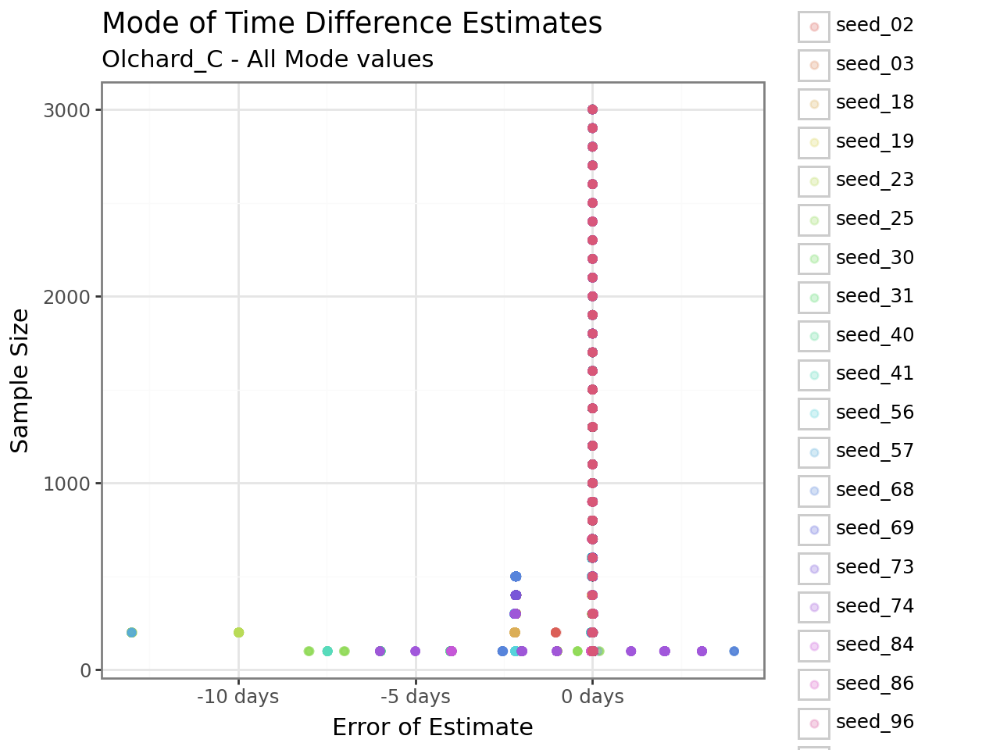

C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:606: PlotnineWarning: Saving 6.4 x 4.8 in image.
C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:607: PlotnineWarning: Filename: olchard_C_low_results_all_mode.png


In [117]:
p = ggplot(olchard_C_all_results_df, aes("error_estimate", "sample_size", colour = "set_seed"))  + geom_point(alpha = 0.25) + labs(title= "Mode of Time Difference Estimates", subtitle="Olchard_C - All Mode values", x = "Error of Estimate",  y = "Sample Size", colour = "Simulation seed") + theme_bw()
p.show()
p.save(filename = 'olchard_C_low_results_all_mode.png', dpi = 300)

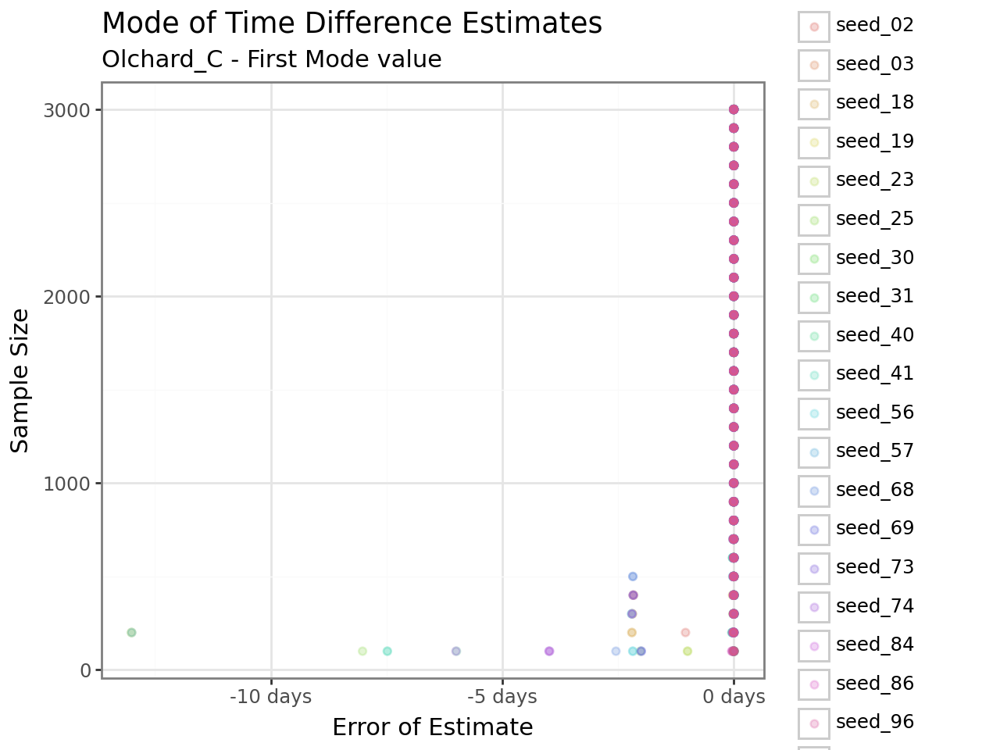

C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:606: PlotnineWarning: Saving 6.4 x 4.8 in image.
C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:607: PlotnineWarning: Filename: olchard_C_low_results_first_mode.png


In [118]:
p = ggplot(olchard_C_first_results_df, aes("error_estimate", "sample_size", colour = "set_seed")) + geom_point(alpha = 0.25) + labs(title= "Mode of Time Difference Estimates", subtitle="Olchard_C - First Mode value", x = "Error of Estimate",  y = "Sample Size", colour = "Simulation seed") + theme_bw()
p.show()
p.save(filename = 'olchard_C_low_results_first_mode.png', dpi = 300)

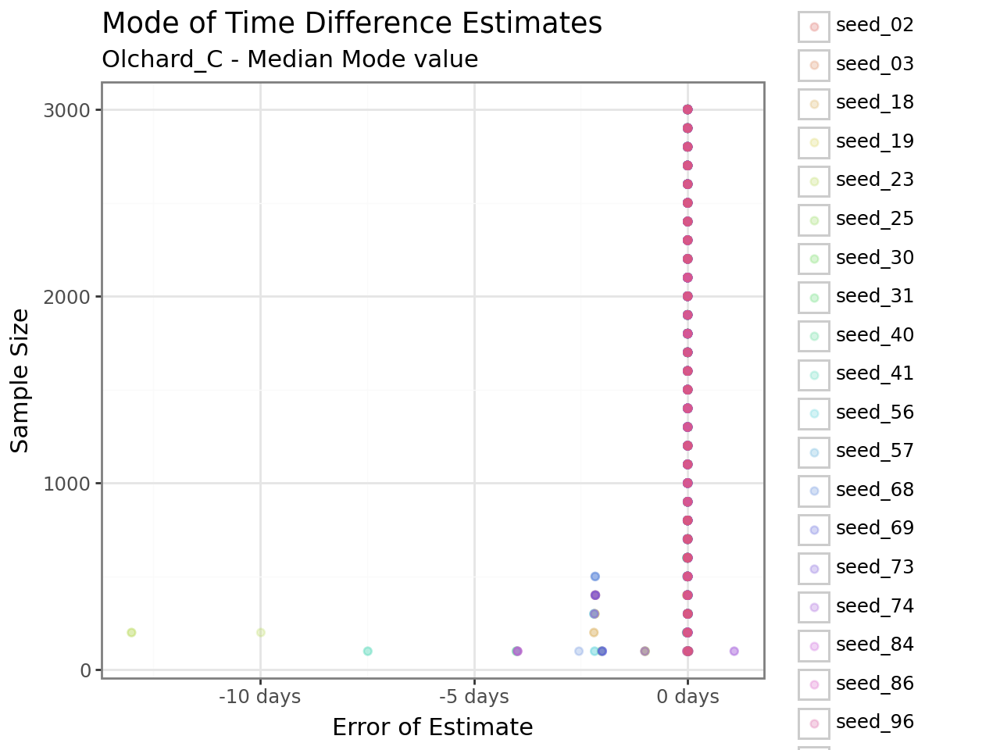

C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:606: PlotnineWarning: Saving 6.4 x 4.8 in image.
C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:607: PlotnineWarning: Filename: olchard_C_low_results_median_mode.png


In [119]:
p = ggplot(olchard_C_median_results_df, aes("error_estimate", "sample_size", colour = "set_seed"))  + geom_point(alpha = 0.25) + labs(title= "Mode of Time Difference Estimates", subtitle="Olchard_C - Median Mode value", x = "Error of Estimate",  y = "Sample Size", colour = "Simulation seed") + theme_bw()
p.show()
p.save(filename = 'olchard_C_low_results_median_mode.png', dpi = 300)

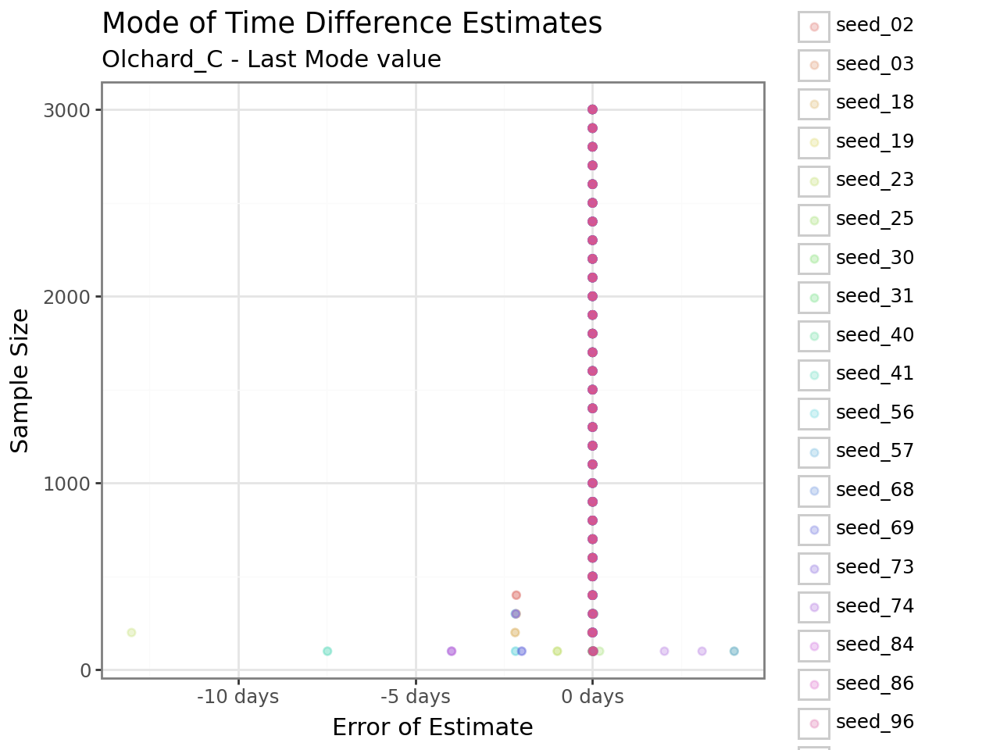

C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:606: PlotnineWarning: Saving 6.4 x 4.8 in image.
C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:607: PlotnineWarning: Filename: olchard_C_low_results_last_mode.png


In [120]:
p = ggplot(olchard_C_last_results_df, aes("error_estimate", "sample_size", colour = "set_seed"))  + geom_point(alpha = 0.25) + labs(title= "Mode of Time Difference Estimates", subtitle="Olchard_C - Last Mode value", x = "Error of Estimate",  y = "Sample Size", colour = "Simulation seed") + theme_bw()
p.show()
p.save(filename = 'olchard_C_low_results_last_mode.png', dpi = 300)

In [ ]:
#Create blank lists for results
all_results_list = []
first_results_list = []
median_results_list = []
last_results_list = []

for outer_key, inner_dict in dataframes.items():
    if re.match(re.compile(r'^olchard_C.*$'), outer_key):
        print(outer_key, type(inner_dict))
        seed_value = outer_key[10:17]
        print(seed_value)
        
        # Iterate over the inner dictionary
        for inner_key, df in inner_dict.items():
            if re.match(re.compile(r'.*_very_low_kl_div_error'), inner_key):
                print(inner_key, type(df))
                
                for final_key, final_df in df.items():
                    print(final_key)
                    ss_value = final_key[12:]
                    print(ss_value)
                    
                    if final_df.empty:
                        print('DataFrame is empty!')

                    else:
                        #create a copy of the dataframe before changing
                        new_df = final_df
                    
                        #create new columns of the sample size and the set seed of simnulation
                        new_df['sample_size'] = ss_value
                        new_df['set_seed'] = seed_value
                    
                        #calculate the mode values
                        first_mode = new_df.iloc[[0]]
                        last_mode = new_df.iloc[[-1]]
                        #median of the mode
                        new_df['median_diff'] = (new_df['time_diff'] - new_df['time_diff'].median()).abs()
                        median_mode = new_df.loc[new_df['median_diff'] == new_df['median_diff'].min()]
                    
                        #Add to dataframes
                        all_results_list.append(new_df)
                        first_results_list.append(first_mode)
                        median_results_list.append(median_mode)
                        last_results_list.append(last_mode)

olchard_C_all_results_df = pd.concat(all_results_list, axis = 0, ignore_index = True)
olchard_C_all_results_df[['sample_size']] = olchard_C_all_results_df[['sample_size']].apply(pd.to_numeric)

olchard_C_first_results_df = pd.concat(first_results_list, axis = 0, ignore_index = True)
olchard_C_first_results_df[['sample_size']] = olchard_C_first_results_df[['sample_size']].apply(pd.to_numeric)

olchard_C_median_results_df = pd.concat(median_results_list, axis = 0, ignore_index = True)
olchard_C_median_results_df[['sample_size']] = olchard_C_median_results_df[['sample_size']].apply(pd.to_numeric)

olchard_C_last_results_df = pd.concat(last_results_list, axis = 0, ignore_index = True)
olchard_C_last_results_df[['sample_size']] = olchard_C_last_results_df[['sample_size']].apply(pd.to_numeric)

In [122]:
olchard_C_very_low_KL_div_sim_results = {
    "all_mode_results" : olchard_C_all_results_df,
    "first_mode_results" : olchard_C_first_results_df,
    "median_mode_results" : olchard_C_median_results_df,
    "last_mode_results" : olchard_C_last_results_df
}

In [123]:
#Remove NA values
olchard_C_all_results_df.dropna(subset = ['error_estimate'], inplace = True)
olchard_C_first_results_df.dropna(subset = ['error_estimate'], inplace = True)
olchard_C_median_results_df.dropna(subset = ['error_estimate'], inplace = True)
olchard_C_last_results_df.dropna(subset = ['error_estimate'], inplace = True)

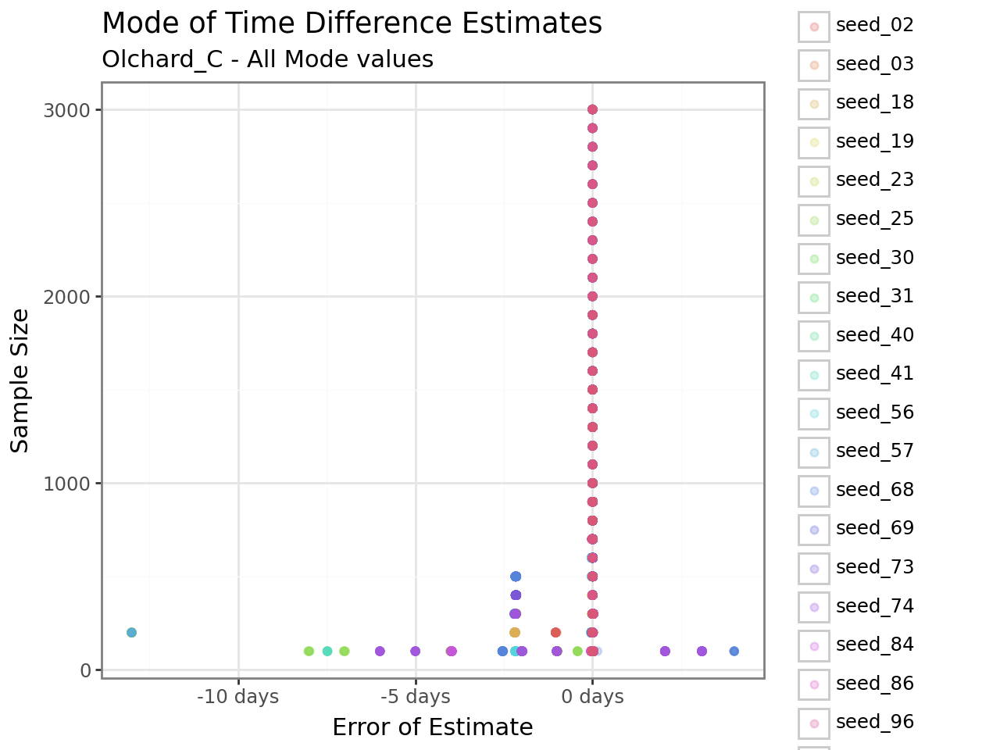

C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:606: PlotnineWarning: Saving 6.4 x 4.8 in image.
C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:607: PlotnineWarning: Filename: olchard_C_very_low_results_all_mode.png


In [124]:
p = ggplot(olchard_C_all_results_df, aes("error_estimate", "sample_size", colour = "set_seed"))  + geom_point(alpha = 0.25) + labs(title= "Mode of Time Difference Estimates", subtitle="Olchard_C - All Mode values", x = "Error of Estimate",  y = "Sample Size", colour = "Simulation seed") + theme_bw()
p.show()
p.save(filename = 'olchard_C_very_low_results_all_mode.png', dpi = 300)

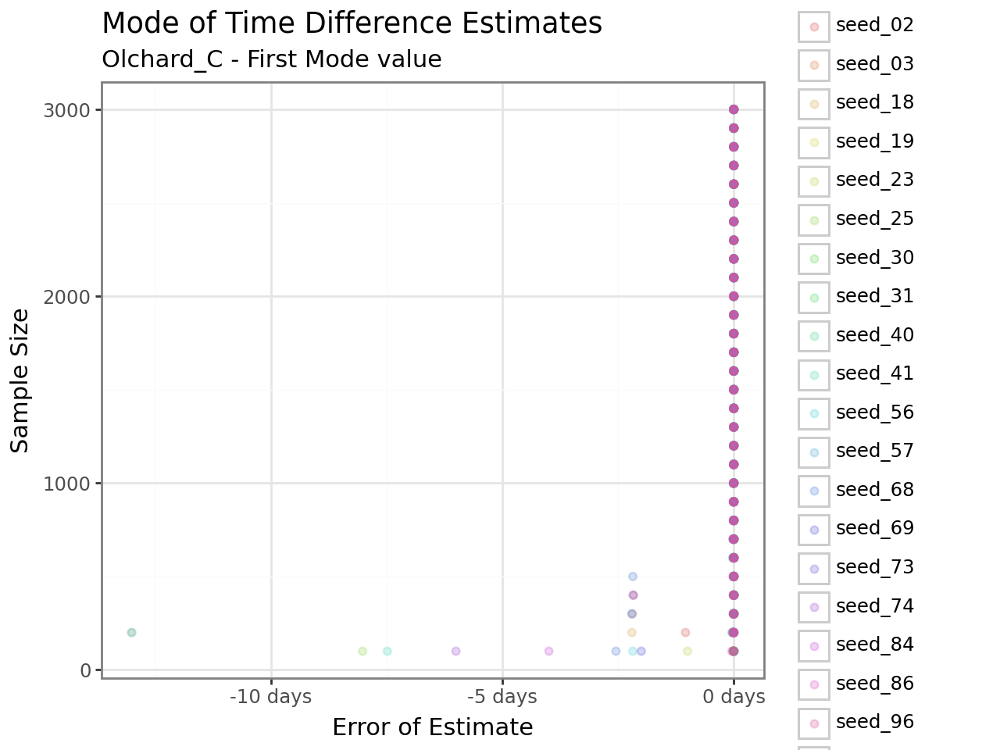

C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:606: PlotnineWarning: Saving 6.4 x 4.8 in image.
C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:607: PlotnineWarning: Filename: olchard_C_very_low_results_first_mode.png


In [125]:
p = ggplot(olchard_C_first_results_df, aes("error_estimate", "sample_size", colour = "set_seed")) + geom_point(alpha = 0.25) + labs(title= "Mode of Time Difference Estimates", subtitle="Olchard_C - First Mode value", x = "Error of Estimate",  y = "Sample Size", colour = "Simulation seed") + theme_bw()
p.show()
p.save(filename = 'olchard_C_very_low_results_first_mode.png', dpi = 300)

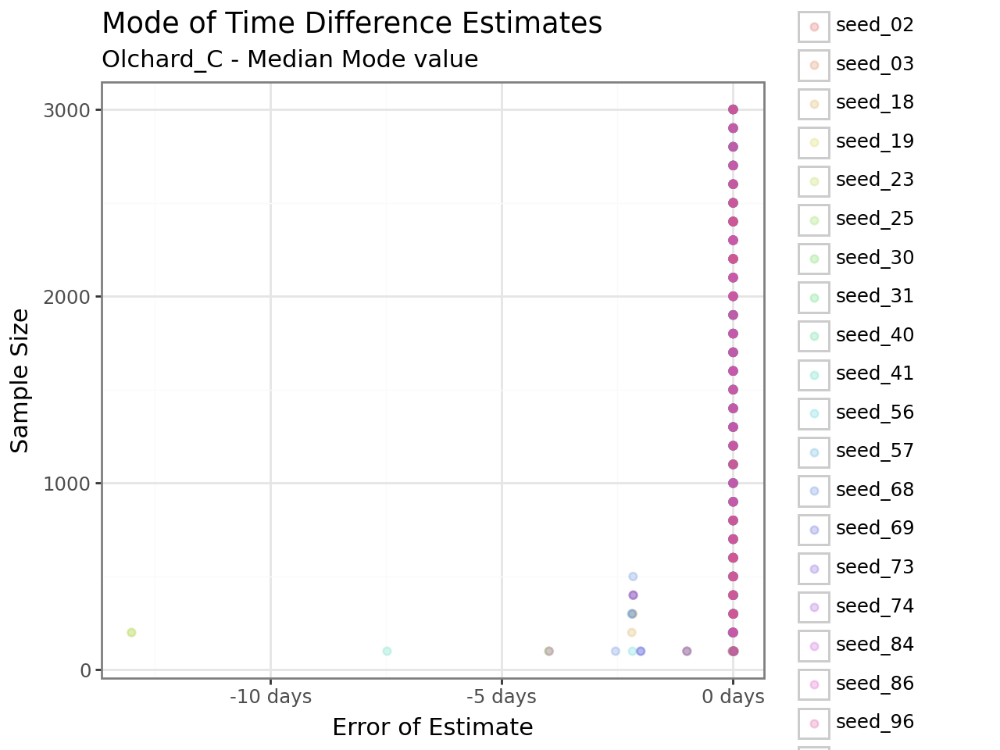

C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:606: PlotnineWarning: Saving 6.4 x 4.8 in image.
C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:607: PlotnineWarning: Filename: olchard_C_very_low_results_median_mode.png


In [126]:
p = ggplot(olchard_C_median_results_df, aes("error_estimate", "sample_size", colour = "set_seed"))  + geom_point(alpha = 0.25) + labs(title= "Mode of Time Difference Estimates", subtitle="Olchard_C - Median Mode value", x = "Error of Estimate",  y = "Sample Size", colour = "Simulation seed") + theme_bw()
p.show()
p.save(filename = 'olchard_C_very_low_results_median_mode.png', dpi = 300)

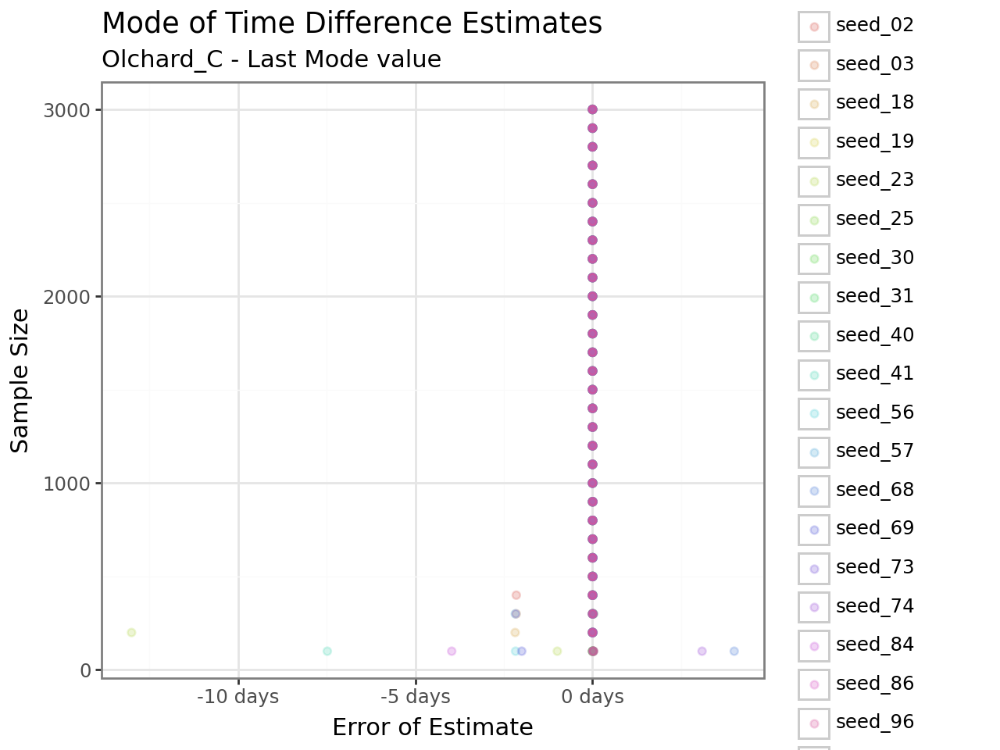

C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:606: PlotnineWarning: Saving 6.4 x 4.8 in image.
C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:607: PlotnineWarning: Filename: olchard_C_very_low_results_last_mode.png


In [127]:
p = ggplot(olchard_C_last_results_df, aes("error_estimate", "sample_size", colour = "set_seed"))  + geom_point(alpha = 0.25) + labs(title= "Mode of Time Difference Estimates", subtitle="Olchard_C - Last Mode value", x = "Error of Estimate",  y = "Sample Size", colour = "Simulation seed") + theme_bw()
p.show()
p.save(filename = 'olchard_C_very_low_results_last_mode.png', dpi = 300)

In [ ]:
#Create blank lists for results
all_results_list = []
first_results_list = []
median_results_list = []
last_results_list = []

for outer_key, inner_dict in dataframes.items():
    if re.match(re.compile(r'^olchard_C.*$'), outer_key):
        print(outer_key, type(inner_dict))
        seed_value = outer_key[10:17]
        print(seed_value)
        
        # Iterate over the inner dictionary
        for inner_key, df in inner_dict.items():
            if re.match(re.compile(r'.*_zero_kl_div_error'), inner_key):
                print(inner_key, type(df))
                
                for final_key, final_df in df.items():
                    print(final_key)
                    ss_value = final_key[12:]
                    print(ss_value)
                    
                    if final_df.empty:
                        print('DataFrame is empty!')

                    else:
                        #create a copy of the dataframe before changing
                        new_df = final_df
                    
                        #create new columns of the sample size and the set seed of simnulation
                        new_df['sample_size'] = ss_value
                        new_df['set_seed'] = seed_value
                    
                        #calculate the mode values
                        first_mode = new_df.iloc[[0]]
                        last_mode = new_df.iloc[[-1]]
                        #median of the mode
                        new_df['median_diff'] = (new_df['time_diff'] - new_df['time_diff'].median()).abs()
                        median_mode = new_df.loc[new_df['median_diff'] == new_df['median_diff'].min()]
                    
                        #Add to dataframes
                        all_results_list.append(new_df)
                        first_results_list.append(first_mode)
                        median_results_list.append(median_mode)
                        last_results_list.append(last_mode)

olchard_C_all_results_df = pd.concat(all_results_list, axis = 0, ignore_index = True)
olchard_C_all_results_df[['sample_size']] = olchard_C_all_results_df[['sample_size']].apply(pd.to_numeric)

olchard_C_first_results_df = pd.concat(first_results_list, axis = 0, ignore_index = True)
olchard_C_first_results_df[['sample_size']] = olchard_C_first_results_df[['sample_size']].apply(pd.to_numeric)

olchard_C_median_results_df = pd.concat(median_results_list, axis = 0, ignore_index = True)
olchard_C_median_results_df[['sample_size']] = olchard_C_median_results_df[['sample_size']].apply(pd.to_numeric)

olchard_C_last_results_df = pd.concat(last_results_list, axis = 0, ignore_index = True)
olchard_C_last_results_df[['sample_size']] = olchard_C_last_results_df[['sample_size']].apply(pd.to_numeric)

In [129]:
#Put results into dictionary
olchard_C_zero_KL_div_sim_results = {
    "all_mode_results" : olchard_C_all_results_df,
    "first_mode_results" : olchard_C_first_results_df,
    "median_mode_results" : olchard_C_median_results_df,
    "last_mode_results" : olchard_C_last_results_df
}

In [130]:
#Remove NA values
olchard_C_all_results_df.dropna(subset = ['error_estimate'], inplace = True)
olchard_C_first_results_df.dropna(subset = ['error_estimate'], inplace = True)
olchard_C_median_results_df.dropna(subset = ['error_estimate'], inplace = True)
olchard_C_last_results_df.dropna(subset = ['error_estimate'], inplace = True)

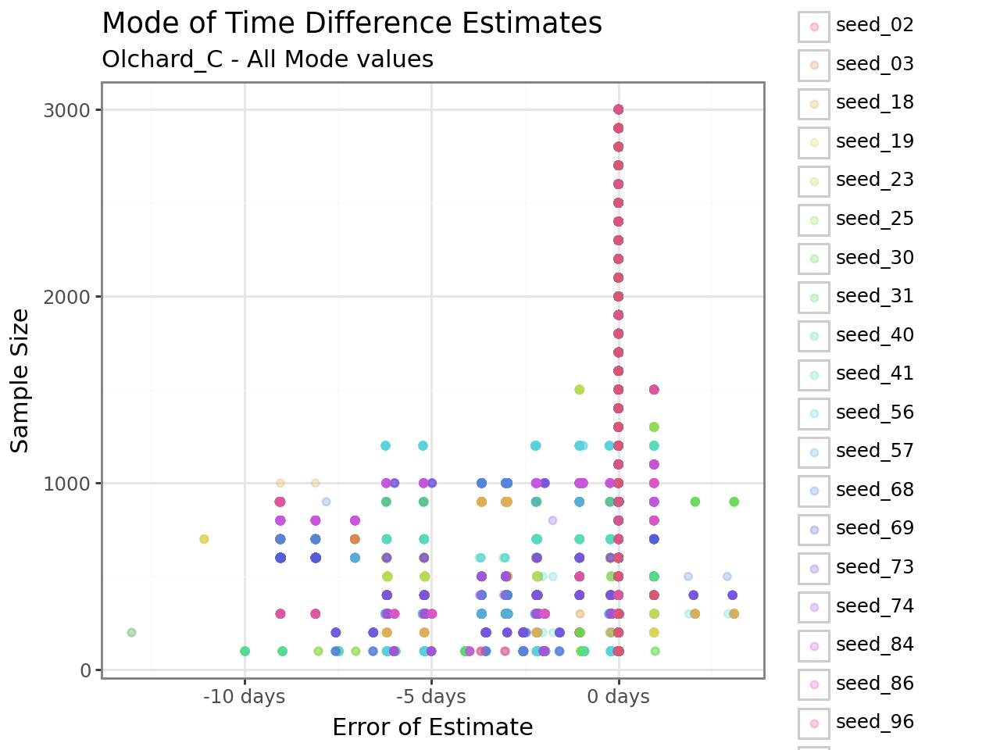

C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:606: PlotnineWarning: Saving 6.4 x 4.8 in image.
C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:607: PlotnineWarning: Filename: olchard_C_zero_results_all_mode.png


In [131]:
p = ggplot(olchard_C_all_results_df, aes("error_estimate", "sample_size", colour = "set_seed"))  + geom_point(alpha = 0.25) + labs(title= "Mode of Time Difference Estimates", subtitle="Olchard_C - All Mode values", x = "Error of Estimate",  y = "Sample Size", colour = "Simulation seed") + theme_bw()
p.show()
p.save(filename = 'olchard_C_zero_results_all_mode.png', dpi = 300)

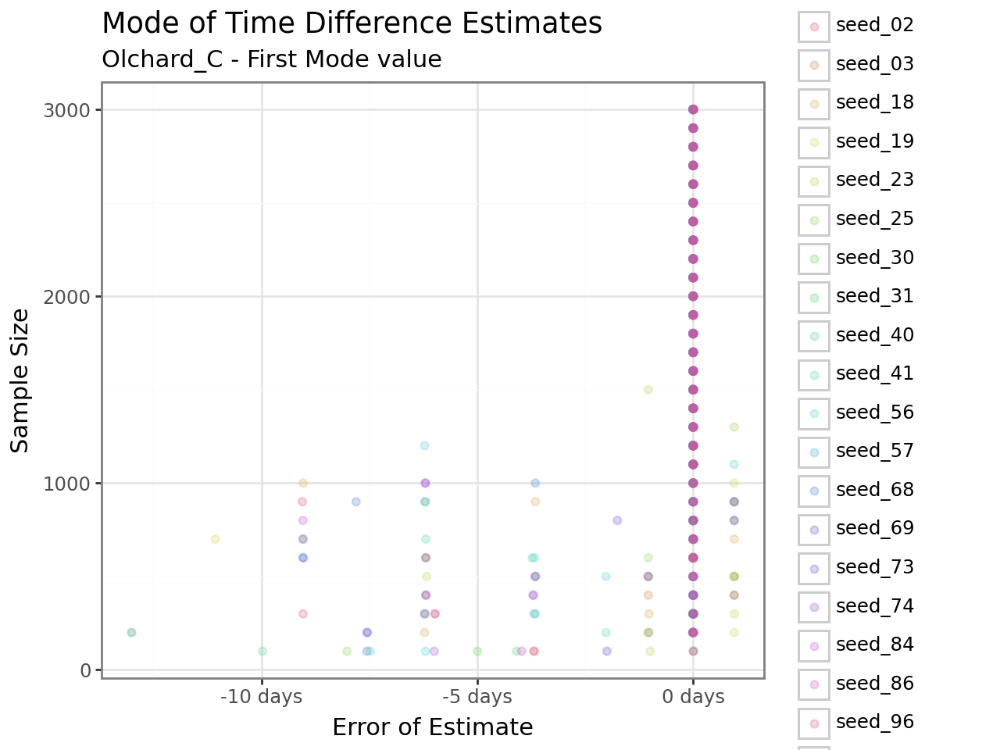

C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:606: PlotnineWarning: Saving 6.4 x 4.8 in image.
C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:607: PlotnineWarning: Filename: olchard_C_zero_results_first_mode.png


In [132]:
p = ggplot(olchard_C_first_results_df, aes("error_estimate", "sample_size", colour = "set_seed")) + geom_point(alpha = 0.25) + labs(title= "Mode of Time Difference Estimates", subtitle="Olchard_C - First Mode value", x = "Error of Estimate",  y = "Sample Size", colour = "Simulation seed") + theme_bw()
p.show()
p.save(filename = 'olchard_C_zero_results_first_mode.png', dpi = 300)

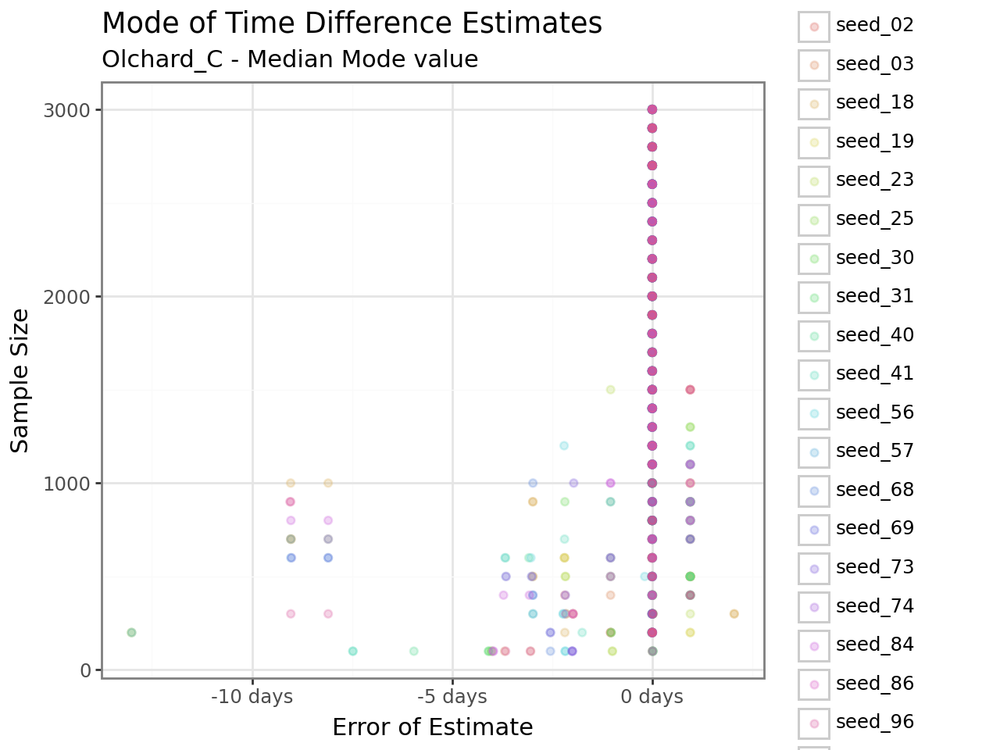

C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:606: PlotnineWarning: Saving 6.4 x 4.8 in image.
C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:607: PlotnineWarning: Filename: olchard_C_zero_results_median_mode.png


In [133]:
p = ggplot(olchard_C_median_results_df, aes("error_estimate", "sample_size", colour = "set_seed"))  + geom_point(alpha = 0.25) + labs(title= "Mode of Time Difference Estimates", subtitle="Olchard_C - Median Mode value", x = "Error of Estimate",  y = "Sample Size", colour = "Simulation seed") + theme_bw()
p.show()
p.save(filename = 'olchard_C_zero_results_median_mode.png', dpi = 300)

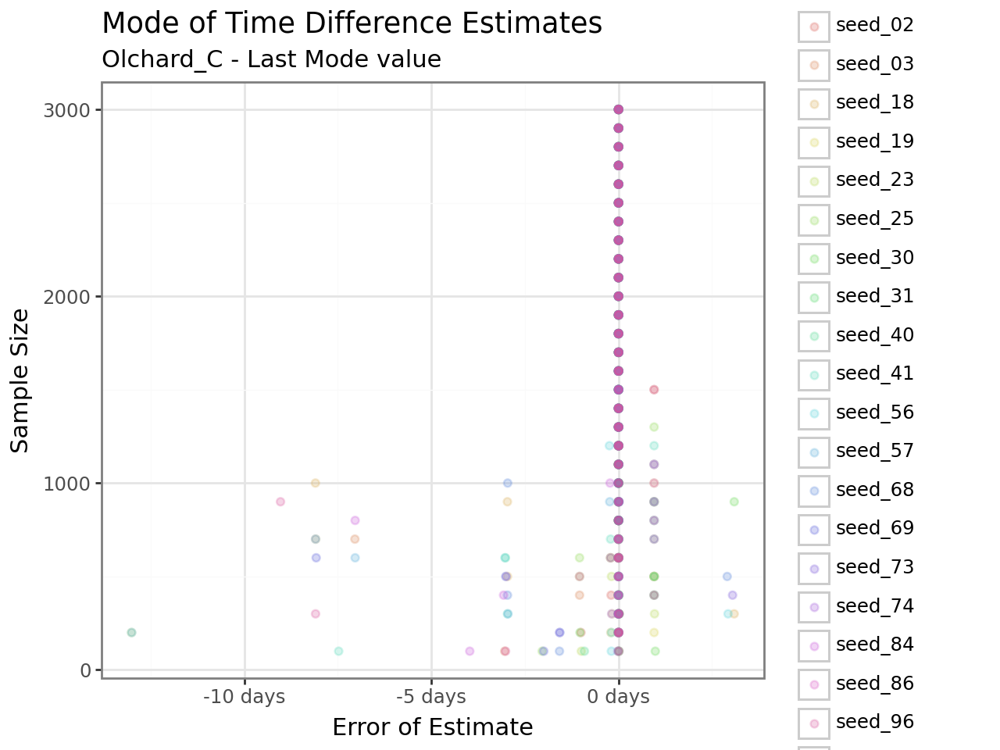

C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:606: PlotnineWarning: Saving 6.4 x 4.8 in image.
C:\Users\katie\anaconda3\Lib\site-packages\plotnine\ggplot.py:607: PlotnineWarning: Filename: olchard_C_zero_results_last_mode.png


In [134]:
p = ggplot(olchard_C_last_results_df, aes("error_estimate", "sample_size", colour = "set_seed"))  + geom_point(alpha = 0.25) + labs(title= "Mode of Time Difference Estimates", subtitle="Olchard_C - Last Mode value", x = "Error of Estimate",  y = "Sample Size", colour = "Simulation seed") + theme_bw()
p.show()
p.save(filename = 'olchard_C_zero_results_last_mode.png', dpi = 300)

In [135]:
#Create dictionary of olchard_C results
olchard_C_sim_results = {
    "all_results" : olchard_C_all_KL_div_sim_results,
    "low_results" : olchard_C_low_KL_div_sim_results,
    "very_low_results" : olchard_C_very_low_KL_div_sim_results,
    "zero_results" : olchard_C_zero_KL_div_sim_results
}

In [ ]:
with open(f'{output_dir}/olchard_C_sim_results.pickle', 'wb') as handle:
        pickle.dump(olchard_C_sim_results, handle, protocol=pickle.HIGHEST_PROTOCOL)